# Modelation mode choice

## 00_ charging and review data

In [1]:
import pandas as pd
import numpy as np
import sklearn
import statsmodels
import scipy
import matplotlib
import seaborn
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Statsmodels:", statsmodels.__version__)
print("SciPy:", scipy.__version__)

Pandas: 2.3.3
NumPy: 2.5.4
Scikit-learn: 1.9.1
Statsmodels: 0.15.0
SciPy: 1.18.1


In [2]:

from pathlib import Path

# Inspect the current working directory
project_path = Path.cwd()

print(f"Current working directory: {project_path}")
print(f"df_base already loaded: {'df_base' in globals()}")
print(f"df_model already loaded: {'df_model' in globals()}")

# Check expected analytical data files
candidate_paths = [
    project_path / "data" / "analytical",
    project_path.parent / "data" / "analytical",
    project_path / "508_TP_Proyect" / "data" / "analytical"
]

print("\nAvailable analytical data directories:")

for path in candidate_paths:
    print(f"{path}: {'Exists' if path.exists() else 'Not found'}")


Current working directory: d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\notebooks
df_base already loaded: False
df_model already loaded: False

Available analytical data directories:
d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\notebooks\data\analytical: Not found
d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\data\analytical: Exists
d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\notebooks\508_TP_Proyect\data\analytical: Not found


In [3]:
data_base_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\data\analytical\df_base.csv")
data_model_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\data\analytical\df_model.csv")

df_base = pd.read_csv(data_base_path, low_memory=False)
df_model = pd.read_csv(data_model_path, low_memory=False)

In [4]:
df_base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100143 entries, 0 to 100142
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   key_viaje                     100143 non-null  object 
 1   modo_principal_agrupado       100143 non-null  object 
 2   modo_principal_desagrupado    100143 non-null  object 
 3   edad                          100143 non-null  int64  
 4   sexo                          100143 non-null  object 
 5   income_group                  100143 non-null  object 
 6   estra_hg                      100143 non-null  object 
 7   vehicle_availability          100143 non-null  object 
 8   has_car_license               100143 non-null  int64  
 9   has_motorcycle_license        100143 non-null  int64  
 10  has_public_transport_license  100143 non-null  int64  
 11  purpose_group                 100143 non-null  object 
 12  time_period_6                 100143 non-nul

In [5]:
df_base.head(5)

,key_viaje,modo_principal_agrupado,modo_principal_desagrupado,edad,sexo,income_group,estra_hg,vehicle_availability,has_car_license,has_motorcycle_license,has_public_transport_license,purpose_group,time_period_6,zat_centroid_distance_m,travel_frequency_3,education_group,occupation_group,household_size_group,duracion_min
0,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,AUTO,Vehículo privado como conductor,41,Hombre,NS_NR,3,2+,1,0,0,WORK,AM_PEAK,12730.630894,DAILY,SECONDARY,EMPLOYEE,4_5_PERSONS,60.0
1,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,AUTO,Vehículo privado como conductor,41,Hombre,NS_NR,3,2+,1,0,0,HOME_RETURN,PM_PEAK,12730.630894,DAILY,SECONDARY,EMPLOYEE,4_5_PERSONS,95.0
2,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,BICICLETA,Bicicleta convencional como conductor,42,Mujer,NS_NR,3,2+,0,0,0,WORK,AM_PEAK,1454.544478,DAILY,TECHNICAL_TECHNOLOGICAL,EMPLOYEE,4_5_PERSONS,30.0
3,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,BICICLETA,Bicicleta convencional como conductor,42,Mujer,NS_NR,3,2+,0,0,0,HOME_RETURN,PM_OFF_PEAK,1454.544478,DAILY,TECHNICAL_TECHNOLOGICAL,EMPLOYEE,4_5_PERSONS,3.0
4,uuid:0001256a-c2fc-4816-91c7-ab0348c4e74b/acce...,A PIE > 15 MIN,A pie (Mayores de 15 min),42,Mujer,NS_NR,3,2+,0,0,0,PERSONAL_ERRANDS,PM_OFF_PEAK,1134.070694,RARELY,TECHNICAL_TECHNOLOGICAL,EMPLOYEE,4_5_PERSONS,15.0


In [6]:

# Load the analytical dataset if it is not already in memory
if "df_model" not in globals():
    df_model = pd.read_csv(data_model_path, low_memory=False)

# Recover the individual identifier associated with each trip
person_map = (
    df_model[["key_viaje", "key_pers"]]
    .drop_duplicates()
)

# Validate the trip-to-person relationship
if person_map["key_viaje"].duplicated().any():
    raise ValueError("Some trips are associated with multiple individuals.")

# Merge individual identifiers into the modeling dataset
if "key_pers" not in df_base.columns:
    df_base = df_base.merge(
        person_map,
        on="key_viaje",
        how="left",
        validate="many_to_one"
    )

# Report recovery results
print(f"Modeling observations: {len(df_base):,}")
print(f"Unique individuals: {df_base['key_pers'].nunique():,}")
print(f"Missing individual identifiers: {df_base['key_pers'].isna().sum():,}")
print(f"Target categories: {df_base['modo_principal_agrupado'].nunique()}")


Modeling observations: 100,143
Unique individuals: 48,528
Missing individual identifiers: 0
Target categories: 11


## 01 Escenario 1 BASE (Usando variables del Viajero)

Este va a ser el primer escenario usando las variables con las que se cuenta de manera mas senciall en la EM2023

In [7]:

# Define target variable
target = "modo_principal_agrupado"

# Define baseline explanatory variables
baseline_features = [
    "edad",
    "sexo",
    "income_group",
    "estra_hg",
    "vehicle_availability",
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license",
    "purpose_group",
    "time_period_6",
    "zat_centroid_distance_m"
]

# Separate predictors and target
X = df_base[baseline_features].copy()
y = df_base[target].copy()

# Identify numerical and categorical features
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in baseline_features
    if col not in numerical_features
]

# Basic validation
assert X.isna().sum().sum() == 0, "Missing values detected in predictors."
assert y.notna().all(), "Missing values detected in target."

print(f"Observations: {len(X):,}")
print(f"Predictors: {len(baseline_features)}")
print(f"Numerical features: {numerical_features}")
print(f"Categorical features: {categorical_features}")
print(f"Target classes: {y.nunique()}")
print("\nTarget distribution:")
print(y.value_counts())


Observations: 100,143
Predictors: 11
Numerical features: ['edad', 'has_car_license', 'has_motorcycle_license', 'has_public_transport_license', 'zat_centroid_distance_m']
Categorical features: ['sexo', 'income_group', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6']
Target classes: 11

Target distribution:
modo_principal_agrupado
TRANSPORTE PÚBLICO    29400
A PIE > 15 MIN        24923
AUTO                  12582
A PIE <15 MIN         12387
MOTO                   6247
BICICLETA              6101
TAXI OCUPADO           3266
TRANSPORTE ESCOLAR     2058
ESPECIAL OCUPADO       1981
INFORMAL                866
OTRO                    332
Name: count, dtype: int64


### 1.1 Particion del data base

In [8]:
# Define reproducibility parameters
RANDOM_STATE = 42
N_SPLITS = 5

# Define grouping variable
groups = df_base["key_pers"]

# Create grouped and stratified holdout split
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

train_idx, test_idx = next( outer_cv.split(X, y, groups=groups))

# Create development and test datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Validate individual separation
assert set(groups_train).isdisjoint(set(groups_test))

# Report partition statistics
print("PARTITION SUMMARY")
print("-" * 40)

print(f"Training observations: {len(X_train):,} "
      f"({len(X_train)/len(X):.2%})")

print(f"Test observations: {len(X_test):,} "
      f"({len(X_test)/len(X):.2%})")

print(f"Training individuals: {groups_train.nunique():,}")
print(f"Test individuals: {groups_test.nunique():,}")

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

# Define grouped cross-validation for model development
inner_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)


PARTITION SUMMARY
----------------------------------------
Training observations: 80,114 (80.00%)
Test observations: 20,029 (20.00%)
Training individuals: 38,821
Test individuals: 9,707

Training target distribution:
modo_principal_agrupado
TRANSPORTE PÚBLICO    0.294
A PIE > 15 MIN        0.249
AUTO                  0.126
A PIE <15 MIN         0.124
MOTO                  0.062
BICICLETA             0.061
TAXI OCUPADO          0.033
TRANSPORTE ESCOLAR    0.021
ESPECIAL OCUPADO      0.020
INFORMAL              0.009
OTRO                  0.003
Name: proportion, dtype: float64

Test target distribution:
modo_principal_agrupado
TRANSPORTE PÚBLICO    0.294
A PIE > 15 MIN        0.249
AUTO                  0.126
A PIE <15 MIN         0.124
MOTO                  0.062
BICICLETA             0.061
TAXI OCUPADO          0.033
TRANSPORTE ESCOLAR    0.021
ESPECIAL OCUPADO      0.020
INFORMAL              0.009
OTRO                  0.003
Name: proportion, dtype: float64


### 1.2 Preprocesamiento

In [9]:

# Identify binary and categorical variables using training data only

binary_features = []
categorical_features = []
numerical_features = []

for col in baseline_features:
    unique_values = X_train[col].dropna().unique()

    if len(unique_values) == 2:
        binary_features.append(col)

    elif (
        pd.api.types.is_numeric_dtype(X_train[col])
    ):
        numerical_features.append(col)

    else:
        categorical_features.append(col)

# Display variable classification
print("BINARY FEATURES")
for col in binary_features:
    print(f"{col}: {sorted(X_train[col].dropna().unique().tolist(), key=str)}")

print("\nCATEGORICAL FEATURES")
for col in categorical_features:
    print(f"{col}: {X_train[col].nunique()} categories")

print("\nNUMERICAL FEATURES")
for col in numerical_features:
    print(f"{col}: {X_train[col].dtype}")

# Validate that all predictors are classified exactly once
classified_features = (
    binary_features + categorical_features + numerical_features
)

assert len(classified_features) == len(baseline_features)
assert len(set(classified_features)) == len(baseline_features)

print("\nFeature classification validated.")


BINARY FEATURES
has_car_license: [0, 1]
has_motorcycle_license: [0, 1]
has_public_transport_license: [0, 1]

CATEGORICAL FEATURES
sexo: 3 categories
income_group: 4 categories
estra_hg: 7 categories
vehicle_availability: 3 categories
purpose_group: 8 categories
time_period_6: 6 categories

NUMERICAL FEATURES
edad: int64
zat_centroid_distance_m: float64

Feature classification validated.


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", binary_features),
        ("categorical", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ],
    remainder="drop"
)

print("Preprocessor configured successfully.")

Preprocessor configured successfully.


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Original features:", X_train.shape[1])
print("Processed features:", X_train_processed.shape[1])
print("Processed matrix shape:", X_train_processed.shape)

Original features: 11
Processed features: 30
Processed matrix shape: (80114, 30)


In [12]:
feature_names = preprocessor.get_feature_names_out()

print("Processed feature names:")
for i, feature in enumerate(feature_names, start=1):
    print(f"{i:02d}. {feature}")

print(f"\nTotal processed features: {len(feature_names)}")

Processed feature names:
01. binary__has_car_license
02. binary__has_motorcycle_license
03. binary__has_public_transport_license
04. categorical__sexo_Intersexual
05. categorical__sexo_Mujer
06. categorical__income_group_LOW_INCOME
07. categorical__income_group_MEDIUM_INCOME
08. categorical__income_group_NS_NR
09. categorical__estra_hg_2
10. categorical__estra_hg_3
11. categorical__estra_hg_4
12. categorical__estra_hg_5
13. categorical__estra_hg_6
14. categorical__estra_hg_No aplica
15. categorical__vehicle_availability_1
16. categorical__vehicle_availability_2+
17. categorical__purpose_group_ESCORT
18. categorical__purpose_group_HEALTH
19. categorical__purpose_group_HOME_RETURN
20. categorical__purpose_group_LEISURE
21. categorical__purpose_group_PERSONAL_ERRANDS
22. categorical__purpose_group_SOCIAL_RELIGIOUS
23. categorical__purpose_group_WORK
24. categorical__time_period_6_AM_PEAK
25. categorical__time_period_6_EVENING
26. categorical__time_period_6_OVERNIGHT
27. categorical__time_

In [13]:
# Identify reference categories used by OneHotEncoder

encoder = preprocessor.named_transformers_["categorical"]

for feature, categories, drop_idx in zip(
    categorical_features,
    encoder.categories_,
    encoder.drop_idx_
):
    reference = categories[drop_idx] if drop_idx is not None else None
    print(f"{feature}: {reference}")

sexo: Hombre
income_group: HIGH_INCOME
estra_hg: 1
vehicle_availability: 0
purpose_group: EDUCATION
time_period_6: AM_OFF_PEAK


### 1.3 Unrestricted MNL MODEL (Base Model)

In [14]:
import statsmodels.api as sm
from scipy.sparse import issparse

# Define AUTO as the reference alternative
mode_categories = ["AUTO"] + sorted(
    [mode for mode in y_train.unique() if mode != "AUTO"]
)

y_train_mnl = pd.Series(
    pd.Categorical(
        y_train,
        categories=mode_categories
    ).codes,
    index=y_train.index,
    name="mode_choice"
)

# Transform training predictors
X_train_mnl = preprocessor.fit_transform(X_train)

if issparse(X_train_mnl):
    X_train_mnl = X_train_mnl.toarray()

X_train_mnl = pd.DataFrame(
    X_train_mnl,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

# Add intercept
X_train_mnl = sm.add_constant(X_train_mnl, has_constant="add")

# Verify model inputs
print("Alternative coding:")
for code, mode in enumerate(mode_categories):
    print(f"{code}: {mode}")

print("\nDesign matrix:", X_train_mnl.shape)
print("Target vector:", y_train_mnl.shape)
print("Reference alternative:", mode_categories[0])

Alternative coding:
0: AUTO
1: A PIE <15 MIN
2: A PIE > 15 MIN
3: BICICLETA
4: ESPECIAL OCUPADO
5: INFORMAL
6: MOTO
7: OTRO
8: TAXI OCUPADO
9: TRANSPORTE ESCOLAR
10: TRANSPORTE PÚBLICO

Design matrix: (80114, 31)
Target vector: (80114,)
Reference alternative: AUTO


In [40]:
# Estimate the baseline Multinomial Logit model

mnl_model = sm.MNLogit(
    y_train_mnl,
    X_train_mnl
)


In [18]:
# Estimate MNL using L-BFGS optimization

mnl_results_lbfgs = mnl_model.fit(
    method="lbfgs",
    maxiter=1000,
    pgtol=1e-6,
    disp=True
)

print("\nConvergence:", mnl_results_lbfgs.mle_retvals["converged"])
print("Iterations:", mnl_results_lbfgs.mle_retvals["fcalls"])
print("Log-likelihood:", mnl_results_lbfgs.llf)


Convergence: True
Iterations: 943
Log-likelihood: -108311.7273193966


In [19]:
# Evaluate MNL estimation diagnostics

print("CONVERGENCE:", mnl_results_lbfgs.mle_retvals["converged"])
print("OPTIMIZER:", mnl_results_lbfgs.mle_settings["optimizer"])

print("\nOPTIMIZATION DETAILS")
for key in ["nit", "fcalls", "warnflag", "fopt"]:
    print(f"{key}: {mnl_results_lbfgs.mle_retvals.get(key, 'Not available')}")

print("\nMODEL FIT")
print(f"Log-likelihood: {mnl_results_lbfgs.llf:.4f}")
print(f"AIC: {mnl_results_lbfgs.aic:.4f}")
print(f"BIC: {mnl_results_lbfgs.bic:.4f}")

print("\nPARAMETER DIAGNOSTICS")
print("Finite coefficients:", np.isfinite(mnl_results_lbfgs.params.to_numpy()).all())
print("Finite standard errors:", np.isfinite(mnl_results_lbfgs.bse.to_numpy()).all())

CONVERGENCE: True
OPTIMIZER: lbfgs

OPTIMIZATION DETAILS
nit: Not available
fcalls: 943
warnflag: 0
fopt: 1.3519700341937313

MODEL FIT
Log-likelihood: -108311.7273
AIC: 217243.4546
BIC: 220123.7285

PARAMETER DIAGNOSTICS
Finite coefficients: True
Finite standard errors: True


In [20]:
# Build the MNL coefficient results table

params = mnl_results_lbfgs.params.copy()
standard_errors = mnl_results_lbfgs.bse.copy()
p_values = mnl_results_lbfgs.pvalues.copy()

params.columns = mode_categories[1:]
standard_errors.columns = mode_categories[1:]
p_values.columns = mode_categories[1:]

coef_table = pd.concat({
    "Coefficient": params.stack(),
    "Std_Error": standard_errors.stack(),
    "P_value": p_values.stack()
}, axis=1).reset_index()

coef_table.columns = [
    "Feature", "Alternative",
    "Coefficient", "Std_Error", "P_value"
]

coef_table["Z_stat"] = (
    coef_table["Coefficient"] / coef_table["Std_Error"]
)

coef_table["CI_lower"] = (
    coef_table["Coefficient"] - 1.96 * coef_table["Std_Error"]
)

coef_table["CI_upper"] = (
    coef_table["Coefficient"] + 1.96 * coef_table["Std_Error"]
)

coef_table["Significance"] = np.select(
    [
        coef_table["P_value"] < 0.01,
        coef_table["P_value"] < 0.05,
        coef_table["P_value"] < 0.10
    ],
    ["***", "**", "*"],
    default=""
)

coef_table.head(15)

,Feature,Alternative,Coefficient,Std_Error,P_value,Z_stat,CI_lower,CI_upper,Significance
0,const,A PIE <15 MIN,2.706292,0.131045,9.425398e-95,20.651695,2.449445,2.963140,***
1,const,A PIE > 15 MIN,3.961519,0.121915,1.287952e-231,32.494193,3.722566,4.200472,***
2,const,BICICLETA,-0.628024,0.160565,9.178637e-05,-3.911338,-0.942732,-0.313317,***
3,const,ESPECIAL OCUPADO,-0.426299,0.225754,5.898166e-02,-1.888330,-0.868778,0.016180,*
4,const,INFORMAL,0.952630,0.263793,3.046937e-04,3.611276,0.435595,1.469664,***
5,const,MOTO,-1.724768,0.200027,6.540011e-18,-8.622689,-2.116821,-1.332716,***
6,const,OTRO,-2.451234,0.698464,4.490090e-04,-3.509465,-3.820223,-1.082245,***
7,const,TAXI OCUPADO,0.911031,0.199771,5.105961e-06,4.560386,0.519481,1.302582,***
8,const,TRANSPORTE ESCOLAR,-1.691810,0.243266,3.536342e-12,-6.954572,-2.168611,-1.215009,***
9,const,TRANSPORTE PÚBLICO,3.916757,0.119703,7.914628e-235,32.720760,3.682140,4.151374,***


In [21]:
# Test the joint significance of each predictor across alternatives

wald_results = []

for feature in X_train_mnl.columns:
    if feature == "const":
        continue

    feature_positions = [
        i for i, name in enumerate(X_train_mnl.columns)
        if name == feature
    ]

    restrictions = np.zeros(
        (len(feature_positions) * (len(mode_categories) - 1),
         len(mnl_results_lbfgs.params.to_numpy().ravel()))
    )

    # Joint Wald test will be constructed in the next step

In [38]:
# Inspect the MNL parameter structure

print("Parameter matrix shape:", mnl_results_lbfgs.params.shape)
print("Number of predictors:", len(mnl_results_lbfgs.params.index))
print("Alternatives:", mnl_results_lbfgs.params.columns.tolist())
print("First predictor names:", mnl_results_lbfgs.params.index[:5].tolist())

Parameter matrix shape: (31, 10)
Number of predictors: 31
Alternatives: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
First predictor names: ['const', 'binary__has_car_license', 'binary__has_motorcycle_license', 'binary__has_public_transport_license', 'categorical__sexo_Intersexual']


#### 1.3.1 Analisis de Wald para seleccion de coeficientes

In [24]:
# Perform joint Wald tests for each predictor across alternatives

from scipy.stats import chi2

params = mnl_results_lbfgs.params
cov_matrix = mnl_results_lbfgs.cov_params().to_numpy()

n_predictors, n_alternatives = params.shape
parameter_vector = params.to_numpy().ravel(order="F")

wald_results = []

for feature in params.index:
    if feature == "const":
        continue

    feature_idx = params.index.get_loc(feature)

    positions = (
        feature_idx + n_predictors * np.arange(n_alternatives)
    )

    beta = parameter_vector[positions]
    covariance = cov_matrix[np.ix_(positions, positions)]

    wald_stat = beta @ np.linalg.pinv(covariance) @ beta
    degrees_freedom = n_alternatives
    p_value = chi2.sf(wald_stat, degrees_freedom)

    wald_results.append({
        "Feature": feature,
        "Wald_Statistic": wald_stat,
        "Degrees_Freedom": degrees_freedom,
        "P_value": p_value
    })

wald_table = pd.DataFrame(wald_results)

wald_table["Significance"] = np.select(
    [
        wald_table["P_value"] < 0.01,
        wald_table["P_value"] < 0.05,
        wald_table["P_value"] < 0.10
    ],
    ["***", "**", "*"],
    default=""
)

wald_table = wald_table.sort_values("P_value")

display(wald_table)

,Feature,Wald_Statistic,Degrees_Freedom,P_value,Significance
0,binary__has_car_license,3601.599615,10,0.000000e+00,***
15,categorical__vehicle_availability_2+,5106.939406,10,0.000000e+00,***
28,numerical__edad,1684.942942,10,0.000000e+00,***
4,categorical__sexo_Mujer,1955.985079,10,0.000000e+00,***
14,categorical__vehicle_availability_1,4880.846458,10,0.000000e+00,***
29,numerical__zat_centroid_distance_m,10449.431543,10,0.000000e+00,***
1,binary__has_motorcycle_license,6665.134666,10,0.000000e+00,***
22,categorical__purpose_group_WORK,1449.375244,10,2.162506e-305,***
12,categorical__estra_hg_6,1120.009076,10,2.563196e-234,***
13,categorical__estra_hg_No aplica,1084.411928,10,1.209476e-226,***


##### 1.3.1.1 wald General

In [23]:
# Test joint significance of original variables

variable_groups = {
    "has_car_license": ["binary__has_car_license"],
    "has_motorcycle_license": ["binary__has_motorcycle_license"],
    "has_public_transport_license": ["binary__has_public_transport_license"],
    "sexo": [f for f in params.index if f.startswith("categorical__sexo_")],
    "income_group": [f for f in params.index if f.startswith("categorical__income_group_")],
    "estra_hg": [f for f in params.index if f.startswith("categorical__estra_hg_")],
    "vehicle_availability": [f for f in params.index if f.startswith("categorical__vehicle_availability_")],
    "purpose_group": [f for f in params.index if f.startswith("categorical__purpose_group_")],
    "time_period_6": [f for f in params.index if f.startswith("categorical__time_period_6_")],
    "edad": ["numerical__edad"],
    "zat_centroid_distance_m": ["numerical__zat_centroid_distance_m"]
}

group_wald_results = []

for variable, features in variable_groups.items():
    feature_indices = [params.index.get_loc(f) for f in features]

    positions = np.concatenate([
        idx + n_predictors * np.arange(n_alternatives)
        for idx in feature_indices
    ])

    beta = parameter_vector[positions]
    covariance = cov_matrix[np.ix_(positions, positions)]

    wald_stat = beta @ np.linalg.pinv(covariance) @ beta
    df_test = len(positions)
    p_value = chi2.sf(wald_stat, df_test)

    group_wald_results.append({
        "Variable": variable,
        "Wald_Statistic": wald_stat,
        "Degrees_Freedom": df_test,
        "P_value": p_value
    })

group_wald_table = pd.DataFrame(group_wald_results)
group_wald_table = group_wald_table.sort_values("P_value")

display(group_wald_table)

,Variable,Wald_Statistic,Degrees_Freedom,P_value
0,has_car_license,3601.599615,10,0.000000e+00
1,has_motorcycle_license,6665.134666,10,0.000000e+00
3,sexo,1972.704933,20,0.000000e+00
5,estra_hg,4057.514441,60,0.000000e+00
6,vehicle_availability,5869.549632,20,0.000000e+00
7,purpose_group,4113.346665,70,0.000000e+00
9,edad,1684.942942,10,0.000000e+00
10,zat_centroid_distance_m,10449.431543,10,0.000000e+00
8,time_period_6,1455.597809,50,6.777376e-272
4,income_group,813.280922,30,1.004634e-151


In [25]:
from scipy.stats import chi2

wald_by_alternative = []

for variable, features in variable_groups.items():

    feature_indices = [
        params.index.get_loc(feature)
        for feature in features
    ]

    for alt_idx, alternative in enumerate(mode_categories[1:]):

        positions = [
            idx + n_predictors * alt_idx
            for idx in feature_indices
        ]

        beta = parameter_vector[positions]
        covariance = cov_matrix[np.ix_(positions, positions)]

        wald_stat = beta @ np.linalg.pinv(covariance) @ beta
        df_test = len(positions)
        p_value = chi2.sf(wald_stat, df_test)

        wald_by_alternative.append({
            "Variable": variable,
            "Alternative": alternative,
            "Wald": wald_stat,
            "DF": df_test,
            "P_value": p_value
        })

wald_alt_df = pd.DataFrame(wald_by_alternative)

wald_alt_df.head(15)

,Variable,Alternative,Wald,DF,P_value
0,has_car_license,A PIE <15 MIN,1516.511575,1,0.000000e+00
1,has_car_license,A PIE > 15 MIN,1967.585251,1,0.000000e+00
2,has_car_license,BICICLETA,1937.371740,1,0.000000e+00
3,has_car_license,ESPECIAL OCUPADO,339.943556,1,6.563918e-76
4,has_car_license,INFORMAL,206.391424,1,8.417568e-47
5,has_car_license,MOTO,1721.805440,1,0.000000e+00
6,has_car_license,OTRO,120.493627,1,4.932499e-28
7,has_car_license,TAXI OCUPADO,486.119170,1,9.959631e-108
8,has_car_license,TRANSPORTE ESCOLAR,182.277319,1,1.542432e-41
9,has_car_license,TRANSPORTE PÚBLICO,2075.908436,1,0.000000e+00


In [26]:
from statsmodels.stats.multitest import multipletests

wald_alt_df["P_adjusted"] = multipletests(
    wald_alt_df["P_value"],
    method="fdr_bh"
)[1]

wald_alt_df["Significant_5pct"] = (
    wald_alt_df["P_adjusted"] < 0.05
)

wald_summary = (
    wald_alt_df
    .groupby("Variable")
    .agg(
        Significant_Alternatives=("Significant_5pct", "sum"),
        Total_Alternatives=("Alternative", "count"),
        Min_Adjusted_P=("P_adjusted", "min"),
        Max_Adjusted_P=("P_adjusted", "max")
    )
    .reset_index()
)

wald_summary.sort_values(
    "Significant_Alternatives",
    ascending=False
)

,Variable,Significant_Alternatives,Total_Alternatives,Min_Adjusted_P,Max_Adjusted_P
1,estra_hg,10,10,3.129255e-301,1.340650e-04
2,has_car_license,10,10,0.000000e+00,1.023726e-27
6,purpose_group,10,10,1.541846e-106,2.477555e-02
9,vehicle_availability,10,10,0.000000e+00,4.690139e-06
0,edad,9,10,9.293881e-249,7.904416e-01
8,time_period_6,9,10,2.425729e-52,3.409514e-01
10,zat_centroid_distance_m,9,10,0.000000e+00,2.718838e-01
4,has_public_transport_license,8,10,1.267950e-33,7.025579e-01
5,income_group,8,10,3.237578e-61,3.366697e-01
7,sexo,8,10,1.782938e-145,5.839936e-02


##### 1.3.1.2 wald para 10 variables por modo (10x10)

In [27]:
from statsmodels.stats.multitest import multipletests

wald_alt_df["P_adjusted"] = multipletests(
    wald_alt_df["P_value"],
    method="fdr_bh"
)[1]

wald_pvalue_matrix = wald_alt_df.pivot(
    index="Variable",
    columns="Alternative",
    values="P_adjusted"
)

wald_pvalue_matrix

Alternative,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
Variable,,,,,,,,,,
edad,3.869044e-62,5.493012e-58,1.649162e-34,1.348556e-25,3.703875e-11,2.913780e-47,7.904416e-01,4.267190e-08,9.293881e-249,4.634102e-31
estra_hg,1.520792e-139,4.760586e-174,2.103885e-81,1.577235e-32,4.620495e-36,1.347932e-70,1.340650e-04,2.634611e-75,8.963564e-33,3.129255e-301
has_car_license,0.000000e+00,0.000000e+00,0.000000e+00,2.634611e-75,2.572035e-46,0.000000e+00,1.023726e-27,5.216949e-107,4.585608e-41,0.000000e+00
has_motorcycle_license,2.505818e-02,2.093672e-01,1.881388e-01,5.790443e-01,2.487065e-01,0.000000e+00,8.911314e-01,2.991670e-01,8.148519e-04,7.372588e-01
has_public_transport_license,7.025579e-01,7.038990e-08,5.744708e-15,6.817286e-01,2.609201e-02,5.546057e-10,1.267950e-33,2.609201e-02,1.394111e-09,6.449630e-10
income_group,1.448215e-18,3.682248e-37,3.237578e-61,3.366697e-01,1.923429e-07,6.691175e-19,1.287702e-02,2.403371e-01,1.925041e-02,4.970107e-31
purpose_group,3.760068e-104,1.545222e-98,5.908993e-71,1.971054e-19,2.477555e-02,1.844572e-35,2.850553e-09,4.642776e-31,1.198858e-27,1.541846e-106
sexo,1.400997e-31,4.702509e-15,1.782938e-145,2.907669e-06,5.839936e-02,3.735486e-14,7.082336e-06,2.581606e-18,5.786177e-02,6.731021e-33
time_period_6,1.253341e-39,2.425729e-52,3.705481e-14,3.054900e-21,3.409514e-01,7.825133e-09,1.665946e-02,1.568852e-08,3.991667e-38,7.668569e-21


In [28]:
wald_significance_matrix = wald_pvalue_matrix.lt(0.10).replace(
    {True: "✓", False: "—"}
)

wald_significance_matrix

Alternative,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
Variable,,,,,,,,,,
edad,✓,✓,✓,✓,✓,✓,—,✓,✓,✓
estra_hg,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
has_car_license,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
has_motorcycle_license,✓,—,—,—,—,✓,—,—,✓,—
has_public_transport_license,—,✓,✓,—,✓,✓,✓,✓,✓,✓
income_group,✓,✓,✓,—,✓,✓,✓,—,✓,✓
purpose_group,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
sexo,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
time_period_6,✓,✓,✓,✓,—,✓,✓,✓,✓,✓


##### 1.3.1.3  Wald detallado por categorias (30x10)

In [32]:
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests

individual_wald_results = []

for alt_idx, alternative in enumerate(mode_categories[1:]):
    for feature_idx, feature in enumerate(params.index):

        position = feature_idx + n_predictors * alt_idx

        beta = parameter_vector[position]
        variance = cov_matrix[position, position]
        std_error = np.sqrt(variance)

        wald_stat = (beta / std_error) ** 2
        p_value = chi2.sf(wald_stat, df=1)

        individual_wald_results.append({
            "Feature": feature,
            "Alternative": alternative,
            "Coefficient": beta,
            "Std_Error": std_error,
            "Wald": wald_stat,
            "P_value": p_value
        })

individual_wald_df = pd.DataFrame(individual_wald_results)

individual_wald_df["P_adjusted"] = multipletests(
    individual_wald_df["P_value"],
    method="fdr_bh"
)[1]

individual_wald_df.head()

,Feature,Alternative,Coefficient,Std_Error,Wald,P_value,P_adjusted
0,const,A PIE <15 MIN,2.706292,0.131045,426.492512,9.425398e-95,1.082175e-93
1,binary__has_car_license,A PIE <15 MIN,-1.791374,0.046001,1516.511575,0.000000e+00,0.000000e+00
2,binary__has_motorcycle_license,A PIE <15 MIN,0.159028,0.068758,5.349354,2.072995e-02,3.197157e-02
3,binary__has_public_transport_license,A PIE <15 MIN,-0.042199,0.103472,0.166327,6.833972e-01,7.512523e-01
4,categorical__sexo_Intersexual,A PIE <15 MIN,-2.735232,5.741560,0.226949,6.337952e-01,7.093015e-01


In [33]:
individual_pvalue_matrix = individual_wald_df.pivot(
    index="Feature",
    columns="Alternative",
    values="P_adjusted"
)

individual_pvalue_matrix

Alternative,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
Feature,,,,,,,,,,
binary__has_car_license,0.000000e+00,0.000000e+00,0.000000e+00,6.166105e-75,5.930559e-46,0.000000e+00,2.352423e-27,1.234994e-106,1.017349e-40,0.000000e+00
binary__has_motorcycle_license,3.197157e-02,2.419390e-01,2.197876e-01,6.299429e-01,2.849188e-01,0.000000e+00,9.208358e-01,3.385705e-01,1.141563e-03,7.873501e-01
binary__has_public_transport_license,7.512523e-01,1.247821e-07,1.136719e-14,7.299316e-01,3.352195e-02,1.018088e-09,2.858652e-33,3.352195e-02,2.560773e-09,1.178999e-09
categorical__estra_hg_2,7.727210e-03,9.139973e-01,1.054145e-11,2.407092e-06,3.551032e-05,5.563833e-02,7.193959e-01,9.092174e-07,5.470172e-01,3.919024e-01
categorical__estra_hg_3,6.946594e-08,9.474020e-24,7.840152e-01,2.308899e-03,7.063487e-29,2.326465e-15,4.513597e-02,1.056125e-02,8.568245e-03,4.796706e-19
categorical__estra_hg_4,2.393232e-28,2.036784e-49,2.537488e-07,4.661409e-07,9.518469e-14,9.254965e-30,4.076332e-01,1.295091e-04,2.198135e-04,1.493108e-37
categorical__estra_hg_5,8.242812e-37,5.790748e-56,4.055289e-13,4.594813e-04,2.303696e-01,2.012947e-23,4.865932e-01,7.668037e-02,4.891566e-02,4.443822e-81
categorical__estra_hg_6,9.539356e-61,1.232772e-88,1.613284e-16,2.410316e-01,7.193821e-08,2.966882e-35,2.019451e-04,2.990737e-01,9.145243e-01,6.418097e-130
categorical__estra_hg_No aplica,1.502804e-08,2.725069e-26,9.178928e-02,1.860141e-17,8.989665e-06,1.904433e-21,4.511145e-03,5.544204e-22,1.114525e-12,3.000341e-78


#### 1.3.2 Interpretabilidad

In [34]:
# Separate explanatory-variable coefficients from alternative-specific constants
predictor_wald_df = individual_wald_df.loc[
    individual_wald_df["Feature"] != "const"
].copy()

# Recalculate Benjamini-Hochberg adjusted p-values for predictors only
predictor_wald_df["P_adjusted"] = multipletests(
    predictor_wald_df["P_value"],
    method="fdr_bh"
)[1]

# Build a compact coefficient summary table
coefficient_summary = predictor_wald_df[
    [
        "Feature",
        "Alternative",
        "Coefficient",
        "Std_Error",
        "P_value",
        "P_adjusted"
    ]
].copy()

print("Number of predictor coefficients:", len(coefficient_summary))
print("Number of alternatives:", coefficient_summary["Alternative"].nunique())

display(coefficient_summary.head(15))

Number of predictor coefficients: 300
Number of alternatives: 10


,Feature,Alternative,Coefficient,Std_Error,P_value,P_adjusted
1,binary__has_car_license,A PIE <15 MIN,-1.791374,0.046001,0.000000e+00,0.000000e+00
2,binary__has_motorcycle_license,A PIE <15 MIN,0.159028,0.068758,2.072995e-02,3.239055e-02
3,binary__has_public_transport_license,A PIE <15 MIN,-0.042199,0.103472,6.833972e-01,7.537470e-01
4,categorical__sexo_Intersexual,A PIE <15 MIN,-2.735232,5.741560,6.337952e-01,7.121295e-01
5,categorical__sexo_Mujer,A PIE <15 MIN,0.435600,0.036372,4.724990e-33,2.624994e-32
6,categorical__income_group_LOW_INCOME,A PIE <15 MIN,0.572522,0.075132,2.533194e-14,8.171594e-14
7,categorical__income_group_MEDIUM_INCOME,A PIE <15 MIN,0.395462,0.051372,1.381729e-14,4.555150e-14
8,categorical__income_group_NS_NR,A PIE <15 MIN,0.386239,0.050243,1.500979e-14,4.894495e-14
9,categorical__estra_hg_2,A PIE <15 MIN,0.220870,0.078152,4.711105e-03,7.851842e-03
10,categorical__estra_hg_3,A PIE <15 MIN,-0.425893,0.076551,2.644187e-08,7.019966e-08


Tres hallazgos que vale la pena destacar
1. Disponibilidad de vehículos y licencias

La licencia de automóvil tiene un coeficiente negativo importante. También encontramos una asociación negativa para la disponibilidad de un vehículo.

Esto es coherente con la idea de que contar con acceso a un automóvil está asociado con una mayor utilidad relativa de AUTO frente a caminar.

Sin embargo, debemos recordar que estamos estimando asociaciones condicionadas, no relaciones causales.

2. Diferencias socioeconómicas

Los coeficientes de ingreso bajo y medio son positivos frente a ingreso alto. Por otro lado, los coeficientes de los estratos 4, 5 y 6 son negativos frente al estrato 1.

Esto sugiere diferencias socioeconómicas en la elección entre caminar y automóvil. Será interesante contrastar si este patrón se mantiene en transporte público, motocicleta y otras alternativas.

3. Diferencias por sexo

El coeficiente de Mujer es positivo y estadísticamente significativo. En cambio, Intersexual tiene un error estándar muy elevado y no presenta significancia estadística.

No debemos interpretar el coeficiente de Intersexual como evidencia de una asociación negativa: su estimación tiene mucha incertidumbre, posiblemente relacionada con la baja frecuencia de esta categoría.

In [35]:
# Summarize individual coefficient results by original variable

predictor_wald_df["Variable"] = (
    predictor_wald_df["Feature"]
    .str.replace(r"^(binary__|categorical__|numerical__)", "", regex=True)
    .str.replace(r"_.*$", "", regex=False)
)

# Preserve complete variable names for categorical features
predictor_wald_df["Variable"] = predictor_wald_df["Feature"].apply(
    lambda x: next(
        (v for v in variable_groups if x in variable_groups[v]),
        x.split("__")[-1]
    )
)

coefficient_overview = (
    predictor_wald_df
    .groupby("Variable")
    .agg(
        Total_Coefficients=("Coefficient", "count"),
        Positive=("Coefficient", lambda x: (x > 0).sum()),
        Negative=("Coefficient", lambda x: (x < 0).sum()),
        Significant=("P_adjusted", lambda x: (x < 0.05).sum()),
        Mean_Absolute_Coefficient=("Coefficient", lambda x: x.abs().mean())
    )
    .reset_index()
)

display(coefficient_overview.sort_values(
    "Significant",
    ascending=False
))

,Variable,Total_Coefficients,Positive,Negative,Significant,Mean_Absolute_Coefficient
1,estra_hg,60,18,42,46,1.007650
6,purpose_group,70,29,41,38,0.887762
8,time_period_6,50,17,33,33,0.346808
9,vehicle_availability,20,3,17,19,1.794915
5,income_group,30,24,6,16,0.340501
7,sexo,20,10,10,12,1.121136
2,has_car_license,10,0,10,10,1.857195
0,edad,10,2,8,9,0.572331
10,zat_centroid_distance_m,10,3,7,9,0.644582
4,has_public_transport_license,10,5,5,8,0.743391


** General Statistical Analysis and Interpretation of MNL Coefficients**

 **Overview of the estimated coefficients**

The unrestricted Multinomial Logit (MNL) model includes 30 processed explanatory variables and 10 non-reference alternatives, with AUTO as the reference alternative. The model estimates 300 explanatory-variable coefficients and 10 alternative-specific constants (ASCs), resulting in 310 parameters.

The individual coefficient analysis evaluates three dimensions: coefficient direction, magnitude, and statistical significance. Individual Wald tests were performed for the 300 explanatory-variable coefficients, with p-values adjusted using the Benjamini-Hochberg procedure and a significance threshold of 0.05.

The results indicate that passenger characteristics, household conditions, and trip context are associated with differences in the relative utility of travel alternatives compared with AUTO. However, the consistency and direction of these associations vary across alternatives.

Statistical significance across explanatory variables

The proportion of statistically significant coefficients provides an initial overview of the consistency of each variable across alternatives.

| Explanatory variable | Significant coefficients | Total | Significant (%) |
|---|---:|---:|---:|
| Car license ownership | 10 | 10 | 100.0% |
| Vehicle availability | 19 | 20 | 95.0% |
| Age | 9 | 10 | 90.0% |
| ZAT centroid distance | 9 | 10 | 90.0% |
| Public transport license | 8 | 10 | 80.0% |
| Household stratum | 46 | 60 | 76.7% |
| Departure time period | 33 | 50 | 66.0% |
| Sex | 12 | 20 | 60.0% |
| Trip purpose | 38 | 70 | 54.3% |
| Income group | 16 | 30 | 53.3% |
| Motorcycle license | 3 | 10 | 30.0% |

Vehicle-related characteristics show the highest consistency in individual statistical significance. Car license ownership is significant across all alternatives, while vehicle availability is significant in 19 out of 20 coefficients. Age and geographic distance are also significant in nine alternatives.

Household stratum, trip purpose, departure time period, income, and sex exhibit more heterogeneous patterns. Motorcycle license ownership presents the lowest proportion of significant coefficients, suggesting a more alternative-specific association.

These percentages should not be interpreted as a ranking of variable importance, since categorical variables contain different numbers of estimated coefficients.

** Direction and magnitude of the coefficients**

The distribution of coefficient signs provides additional information about the direction of the estimated associations.

| Variable | Positive | Negative | General pattern |
|---|---:|---:|---|
| Car license ownership | 0 | 10 | Negative |
| Vehicle availability | 3 | 17 | Predominantly negative |
| Age | 2 | 8 | Predominantly negative |
| ZAT centroid distance | 3 | 7 | Predominantly negative |
| Public transport license | 5 | 5 | Balanced |
| Household stratum | 18 | 42 | Predominantly negative |
| Departure time period | 17 | 33 | Predominantly negative |
| Sex | 10 | 10 | Balanced |
| Trip purpose | 29 | 41 | Predominantly negative |
| Income group | 24 | 6 | Predominantly positive |
| Motorcycle license | 5 | 5 | Balanced |

The consistently negative coefficients for car license ownership indicate that having a car license is associated with lower relative utility for non-automobile alternatives compared with AUTO, conditional on the other explanatory variables. Vehicle availability exhibits a similar pattern, suggesting that household access to vehicles is an important dimension of modal differentiation.

Income group shows predominantly positive coefficients, indicating that lower-income and medium-income categories frequently have higher relative utility for non-automobile alternatives compared with the high-income reference category. However, this pattern varies across alternatives and should not be interpreted as a universal relationship.

Household stratum, sex, and trip purpose also present heterogeneous associations. Their coefficients must be interpreted relative to their respective reference categories: stratum 1, Hombre, and EDUCATION.

Age and ZAT centroid distance have predominantly negative coefficients. Since both variables were standardized, their coefficients represent the association with a one-standard-deviation increase, rather than an increase of one year or one meter.

Regarding coefficient magnitude, car license ownership (1.857) and vehicle availability (1.795) present the highest mean absolute coefficients, followed by sex (1.121) and household stratum (1.008). These values are descriptive indicators of coefficient magnitude, not formal measures of variable importance, since variables differ in coding, number of categories, and interpretation.

Joint statistical significance of explanatory variables

Individual Wald tests evaluate specific coefficients, whereas joint Wald tests assess whether all coefficients associated with an original variable are simultaneously equal to zero for a given alternative.

The joint tests, adjusted using Benjamini-Hochberg with a significance threshold of 0.10, produced the following results:

| Explanatory variable | Significant alternatives | Total |
|---|---:|---:|
| Household stratum | 10 | 10 |
| Car license ownership | 10 | 10 |
| Trip purpose | 10 | 10 |
| Vehicle availability | 10 | 10 |
| Age | 9 | 10 |
| Departure time period | 9 | 10 |
| ZAT centroid distance | 9 | 10 |
| Public transport license | 8 | 10 |
| Income group | 8 | 10 |
| Sex | 8 | 10 |
| Motorcycle license | 3 | 10 |

These results provide strong evidence that household stratum, car license ownership, trip purpose, and vehicle availability contribute jointly to differentiating all ten alternatives from AUTO.

Age, departure time period, and geographic distance are also jointly significant in most alternatives. Motorcycle license ownership shows a more restricted contribution.

Importantly, joint significance does not indicate the direction or magnitude of an association. It establishes that the corresponding coefficient block is not jointly equal to zero.

** Main findings and methodological considerations**

The combined individual and joint Wald analyses highlight several relevant findings:

- **Vehicle-related characteristics:** Car license ownership and vehicle availability show the most consistent statistical patterns, emphasizing the relevance of individual driving credentials and household motorization.
- **Socioeconomic characteristics:** Household stratum, income, and sex contribute to explaining modal differences, although their associations vary across categories and alternatives.
- **Trip context:** Trip purpose and departure time period show substantial statistical evidence, indicating that modal choice is also associated with the purpose and temporal context of travel.
- **Demographic and geographic characteristics:** Age and ZAT centroid distance contribute to differentiating alternatives in most comparisons.
- **Motorcycle license:** Its contribution is more alternative-specific and less consistent across the choice set.

Several limitations must be considered when interpreting these findings. First, all coefficients describe relative utility compared with AUTO, not absolute preferences. Second, statistical significance does not necessarily imply practical or behavioral importance. Third, the estimated associations are conditional on the variables included in the model and should not be interpreted as causal effects.

Finally, the unrestricted specification allows alternative-specific coefficients for all explanatory variables. Although this provides flexibility, it also increases model complexity and the number of estimated parameters. Some estimates, particularly those associated with infrequent alternatives or categories, may have greater uncertainty.

**Implications for the final MNL specification**

The unrestricted baseline provides an empirical reference for developing a more parsimonious and theoretically defensible specification.

Vehicle-related characteristics, household socioeconomic conditions, trip purpose, departure time period, age, and geographic context should receive particular attention during the next stage.

However, variable selection should not rely exclusively on individual statistical significance. The final specification must also consider behavioral theory, joint statistical evidence, coefficient stability, model identification, and predictive performance.

The next step is to examine the alternative-specific constants (ASCs), followed by goodness-of-fit diagnostics and out-of-sample predictive evaluation.

#### 1.3.3 Especificacion de constantes alternativas

In [36]:
# Extract alternative-specific constants
asc_summary = pd.DataFrame({
    "Alternative": mode_categories[1:],
    "ASC": mnl_results_lbfgs.params.loc["const"].values,
    "Std_Error": mnl_results_lbfgs.bse.loc["const"].values
})

display(asc_summary)

,Alternative,ASC,Std_Error
0,A PIE <15 MIN,2.706292,0.131045
1,A PIE > 15 MIN,3.961519,0.121915
2,BICICLETA,-0.628024,0.160565
3,ESPECIAL OCUPADO,-0.426299,0.225754
4,INFORMAL,0.952630,0.263793
5,MOTO,-1.724768,0.200027
6,OTRO,-2.451234,0.698464
7,TAXI OCUPADO,0.911031,0.199771
8,TRANSPORTE ESCOLAR,-1.691810,0.243266
9,TRANSPORTE PÚBLICO,3.916757,0.119703


In [37]:
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# Calculate individual Wald tests for alternative-specific constants
asc_tests = asc_summary.copy()

asc_tests["Z_value"] = asc_tests["ASC"] / asc_tests["Std_Error"]
asc_tests["P_value"] = 2 * norm.sf(abs(asc_tests["Z_value"]))

# Adjust p-values for multiple hypothesis testing
asc_tests["P_adjusted"] = multipletests(
    asc_tests["P_value"],
    method="holm"
)[1]

# Calculate 95% confidence intervals
asc_tests["CI_lower"] = (
    asc_tests["ASC"] - 1.96 * asc_tests["Std_Error"]
)
asc_tests["CI_upper"] = (
    asc_tests["ASC"] + 1.96 * asc_tests["Std_Error"]
)

asc_tests["Significant"] = asc_tests["P_adjusted"] < 0.05

display(
    asc_tests[
        [
            "Alternative",
            "ASC",
            "Std_Error",
            "Z_value",
            "P_value",
            "P_adjusted",
            "CI_lower",
            "CI_upper",
            "Significant"
        ]
    ].round(4)
)

,Alternative,ASC,Std_Error,Z_value,P_value,P_adjusted,CI_lower,CI_upper,Significant
0,A PIE <15 MIN,2.7063,0.1310,20.6517,0.0000,0.0000,2.4494,2.9631,True
1,A PIE > 15 MIN,3.9615,0.1219,32.4942,0.0000,0.0000,3.7226,4.2005,True
2,BICICLETA,-0.6280,0.1606,-3.9113,0.0001,0.0004,-0.9427,-0.3133,True
3,ESPECIAL OCUPADO,-0.4263,0.2258,-1.8883,0.0590,0.0590,-0.8688,0.0162,False
4,INFORMAL,0.9526,0.2638,3.6113,0.0003,0.0009,0.4356,1.4697,True
5,MOTO,-1.7248,0.2000,-8.6227,0.0000,0.0000,-2.1168,-1.3327,True
6,OTRO,-2.4512,0.6985,-3.5095,0.0004,0.0009,-3.8202,-1.0822,True
7,TAXI OCUPADO,0.9110,0.1998,4.5604,0.0000,0.0000,0.5195,1.3026,True
8,TRANSPORTE ESCOLAR,-1.6918,0.2433,-6.9546,0.0000,0.0000,-2.1686,-1.2150,True
9,TRANSPORTE PÚBLICO,3.9168,0.1197,32.7208,0.0000,0.0000,3.6821,4.1514,True


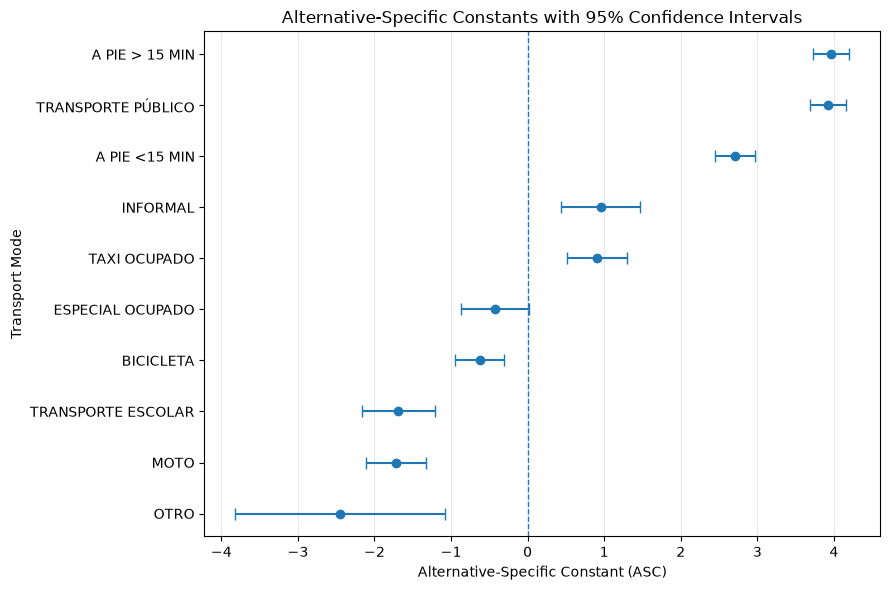

In [38]:
import matplotlib.pyplot as plt

# Sort alternatives by ASC value
asc_plot = asc_tests.sort_values("ASC")

# Calculate confidence interval widths
errors = 1.96 * asc_plot["Std_Error"]

# Plot alternative-specific constants
plt.figure(figsize=(9, 6))

plt.errorbar(
    asc_plot["ASC"],
    asc_plot["Alternative"],
    xerr=errors,
    fmt="o",
    capsize=4
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Alternative-Specific Constant (ASC)")
plt.ylabel("Transport Mode")
plt.title("Alternative-Specific Constants with 95% Confidence Intervals")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 1.3.4 Bondad de ajuste modelo sin restricciones

In [39]:
# Inspect baseline MNL estimation statistics
print("Log-likelihood:", mnl_results_lbfgs.llf)
print("Number of observations:", mnl_results_lbfgs.nobs)
print("Number of estimated parameters:", mnl_results_lbfgs.params.size)
print("AIC:", mnl_results_lbfgs.aic)
print("BIC:", mnl_results_lbfgs.bic)
print("Converged:", mnl_results_lbfgs.mle_retvals["converged"])

Log-likelihood: -108311.7273193966
Number of observations: 80114
Number of estimated parameters: 310
AIC: 217243.4546387932
BIC: 220123.72846757836
Converged: True


#### 1.3.4 Evaluación predictiva MNL-Base

In [47]:
from scipy.sparse import issparse

# Transform test predictors using the fitted training preprocessor
X_test_mnl = preprocessor.transform(X_test)

if issparse(X_test_mnl):
    X_test_mnl = X_test_mnl.toarray()

X_test_mnl = pd.DataFrame(
    X_test_mnl,
    columns=preprocessor.get_feature_names_out(),
    index=X_test.index
)

# Add intercept and preserve training feature order
X_test_mnl = sm.add_constant(
    X_test_mnl,
    has_constant="add"
)

X_test_mnl = X_test_mnl[X_train_mnl.columns]

# Encode test target using the training alternative order
y_test_mnl = pd.Series(
    pd.Categorical(
        y_test,
        categories=mode_categories
    ).codes,
    index=y_test.index,
    name="mode_choice"
)

# Verify test data
print("Test design matrix:", X_test_mnl.shape)
print("Test target:", y_test_mnl.shape)
print("Unknown target categories:", (y_test_mnl == -1).sum())
print("Feature order consistent:", X_test_mnl.columns.equals(X_train_mnl.columns))
print("Alternative categories:", len(mode_categories))

Test design matrix: (20029, 31)
Test target: (20029,)
Unknown target categories: 0
Feature order consistent: True
Alternative categories: 11


In [48]:
# Diagnose numerical stability in MNL predictions
from scipy.special import softmax

# Calculate systematic utilities for all alternatives
utility_test = (
    X_test_mnl.to_numpy()
    @ mnl_results_lbfgs.params.to_numpy()
)

# Construct the utility matrix including the reference alternative
utility_matrix = np.column_stack([
    np.zeros(len(X_test_mnl)),
    utility_test
])

# Calculate numerically stable choice probabilities
probabilities = softmax(utility_matrix, axis=1)

# Store predicted probabilities
y_test_prob_df = pd.DataFrame(
    probabilities,
    columns=mode_categories,
    index=X_test_mnl.index
)

# Identify the predicted alternative
y_test_pred = pd.Series(
    y_test_prob_df.idxmax(axis=1),
    index=y_test_prob_df.index,
    name="predicted_mode"
)

# Verify predicted probabilities
print("Probability matrix shape:", y_test_prob_df.shape)
print("Minimum probability:", y_test_prob_df.min().min())
print("Maximum probability:", y_test_prob_df.max().max())
print("Minimum row probability sum:", y_test_prob_df.sum(axis=1).min())
print("Maximum row probability sum:", y_test_prob_df.sum(axis=1).max())
print("Total NaN values:", y_test_prob_df.isna().sum().sum())

print("\nPredicted mode distribution:")
display(y_test_pred.value_counts())

Probability matrix shape: (20029, 11)
Minimum probability: 2.0095215929820376e-14
Maximum probability: 0.9859463831465174
Minimum row probability sum: 0.9999999999999994
Maximum row probability sum: 1.0000000000000004
Total NaN values: 0

Predicted mode distribution:


predicted_mode
A PIE > 15 MIN        7859
TRANSPORTE PÚBLICO    6496
AUTO                  3109
MOTO                  1516
BICICLETA              628
TRANSPORTE ESCOLAR     246
A PIE <15 MIN          126
TAXI OCUPADO            47
OTRO                     2
Name: count, dtype: int64

In [49]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# Evaluate baseline MNL predictive performance
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, y_test_pred
    ),
    "Macro Precision": precision_score(
        y_test, y_test_pred,
        labels=mode_categories,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_test_pred,
        labels=mode_categories,
        average="macro",
        zero_division=0
    ),
    "Macro F1-score": f1_score(
        y_test, y_test_pred,
        labels=mode_categories,
        average="macro",
        zero_division=0
    ),
    "Log Loss": log_loss(
        y_test_mnl,
        y_test_prob_df[mode_categories],
        labels=list(range(len(mode_categories)))
    )
}

baseline_metrics_df = pd.DataFrame(
    baseline_metrics.items(),
    columns=["Metric", "Value"]
)

display(baseline_metrics_df.round(4))

,Metric,Value
0,Accuracy,0.5375
1,Balanced Accuracy,0.3107
2,Macro Precision,0.3590
3,Macro Recall,0.3107
4,Macro F1-score,0.2970
5,Log Loss,1.3446


In [50]:
from sklearn.metrics import confusion_matrix, classification_report

# Compute the confusion matrix
baseline_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=mode_categories
)

baseline_cm_df = pd.DataFrame(
    baseline_cm,
    index=mode_categories,
    columns=mode_categories
)

# Display the confusion matrix
display(baseline_cm_df)

# Calculate performance metrics by alternative
baseline_class_report = classification_report(
    y_test,
    y_test_pred,
    labels=mode_categories,
    output_dict=True,
    zero_division=0
)

baseline_class_metrics = pd.DataFrame(
    baseline_class_report
).T.loc[mode_categories, ["precision", "recall", "f1-score", "support"]]

display(baseline_class_metrics.round(4))

,AUTO,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
AUTO,1613,17,288,40,0,0,164,2,10,27,355
A PIE <15 MIN,183,47,1889,58,0,0,54,0,0,12,235
A PIE > 15 MIN,350,41,3569,112,0,0,82,0,5,40,785
BICICLETA,133,13,433,246,0,0,91,0,0,2,302
ESPECIAL OCUPADO,54,1,121,26,0,0,13,0,5,8,168
INFORMAL,12,1,99,5,0,0,6,0,0,0,50
MOTO,93,3,76,11,0,0,973,0,0,5,88
OTRO,20,0,17,4,0,0,4,0,0,1,21
TAXI OCUPADO,151,0,192,7,0,0,8,0,18,3,275
TRANSPORTE ESCOLAR,4,0,213,10,0,0,0,0,0,134,51


,precision,recall,f1-score,support
AUTO,0.5188,0.6411,0.5735,2516.0
A PIE <15 MIN,0.3730,0.0190,0.0361,2478.0
A PIE > 15 MIN,0.4541,0.7161,0.5558,4984.0
BICICLETA,0.3917,0.2016,0.2662,1220.0
ESPECIAL OCUPADO,0.0000,0.0000,0.0000,396.0
INFORMAL,0.0000,0.0000,0.0000,173.0
MOTO,0.6418,0.7790,0.7038,1249.0
OTRO,0.0000,0.0000,0.0000,67.0
TAXI OCUPADO,0.3830,0.0275,0.0514,654.0
TRANSPORTE ESCOLAR,0.5447,0.3252,0.4073,412.0


### Predictive Evaluation – Unrestricted MNL Baseline

**Overall predictive performance**

The unrestricted Multinomial Logit (MNL) model was evaluated using the independent test set, consisting of 20,029 trips from individuals not included in the training sample. The evaluation considered both classification-based metrics and probabilistic performance to assess the model's ability to predict observed travel mode choices.

| Metric | Value |
|:---|---:|
| Accuracy | 0.5375 |
| Balanced Accuracy | 0.3107 |
| Macro Precision | 0.3590 |
| Macro Recall | 0.3107 |
| Macro F1-score | 0.2970 |
| Log Loss | 1.3446 |

The model achieved an overall accuracy of **53.75%**, indicating that slightly more than half of the observed travel mode choices were correctly classified. However, the substantially lower balanced accuracy (31.07%) and macro F1-score (29.70%) reveal an uneven predictive performance across alternatives. This difference suggests that the overall accuracy is strongly influenced by the model's ability to identify more frequently selected alternatives, while its performance on less frequently observed modes remains limited.

The log loss of **1.3446** provides an additional assessment of the predicted choice probabilities, accounting for both the assigned probabilities and the observed outcomes. This metric will be particularly useful when comparing the baseline specification with subsequent econometric and machine learning models.

**Predictive performance by travel mode**

The classification report provides a more detailed assessment of the model's ability to identify each travel mode. The following table summarizes precision, recall, and F1-score for all alternatives.

| Travel mode | Precision | Recall | F1-score |
|:---|---:|---:|---:|
| AUTO | 0.5188 | 0.6411 | 0.5735 |
| A PIE <15 MIN | 0.3730 | 0.0190 | 0.0361 |
| A PIE >15 MIN | 0.4541 | 0.7161 | 0.5558 |
| BICICLETA | 0.3917 | 0.2016 | 0.2662 |
| ESPECIAL OCUPADO | 0.0000 | 0.0000 | 0.0000 |
| INFORMAL | 0.0000 | 0.0000 | 0.0000 |
| MOTO | 0.6418 | 0.7790 | 0.7038 |
| OTRO | 0.0000 | 0.0000 | 0.0000 |
| TAXI OCUPADO | 0.3830 | 0.0275 | 0.0514 |
| TRANSPORTE ESCOLAR | 0.5447 | 0.3252 | 0.4073 |
| TRANSPORTE PÚBLICO | 0.6413 | 0.7085 | 0.6732 |

The model shows its strongest predictive performance for **MOTO**, with an F1-score of 0.7038 and recall of 77.90%. **TRANSPORTE PÚBLICO** and **A PIE >15 MIN** also show relatively high recall values (70.85% and 71.61%, respectively). AUTO presents moderate performance, with a recall of 64.11%.

In contrast, the model has substantial difficulties identifying **A PIE <15 MIN** and **TAXI OCUPADO**, with recall values of only 1.90% and 2.75%, respectively. Moreover, **ESPECIAL OCUPADO, INFORMAL, and OTRO** have zero precision, recall, and F1-score because none of these alternatives was selected as the predicted mode for any test observation.

These results indicate that the model's predictive capability is concentrated in a subset of travel alternatives rather than being evenly distributed across the choice set.

**Confusion patterns and alternative misclassification**

The confusion matrix provides further insight into the model's classification behavior. A particularly relevant pattern is the misclassification between the two walking alternatives. Of the 2,478 observed trips classified as A PIE <15 MIN, only 47 were correctly predicted, while 1,889 were classified as A PIE >15 MIN. This represents a substantial difficulty in distinguishing between short and longer walking trips.

Other relevant patterns include:

- **AUTO:** 355 observed trips were classified as TRANSPORTE PÚBLICO, while 288 were classified as A PIE >15 MIN.
- **BICICLETA:** 433 observations were classified as A PIE >15 MIN, indicating considerable confusion between cycling and longer walking trips.
- **TAXI OCUPADO:** Most observations were classified as TRANSPORTE PÚBLICO (275) or AUTO (151).
- **TRANSPORTE ESCOLAR:** 213 observations were classified as A PIE >15 MIN, while only 134 were correctly identified.
- **TRANSPORTE PÚBLICO:** The model correctly classified 4,166 observations, but also assigned 962 observations from A PIE >15 MIN and 496 from AUTO to this alternative.

The distribution of predictions also shows that the model concentrates its classifications on a limited number of alternatives. In particular, A PIE >15 MIN received 7,859 predictions, TRANSPORTE PÚBLICO received 6,215, and AUTO received 3,109. Conversely, ESPECIAL OCUPADO, INFORMAL, and OTRO received no predicted classifications.

It is important to distinguish between an alternative receiving no predicted classifications and receiving zero estimated probability. The MNL model assigns probabilities to all available alternatives, but these three modes never achieved the highest predicted probability for any observation in the test set.

**General interpretation and modeling implications**

The predictive evaluation highlights several limitations of the unrestricted MNL baseline:

- **Uneven classification performance:** The model identifies some alternatives reasonably well but has limited capacity to distinguish several other travel modes. Consequently, overall accuracy alone does not adequately represent its predictive performance.

- **Difficulty distinguishing similar alternatives:** The substantial confusion between A PIE <15 MIN and A PIE >15 MIN suggests that the current explanatory variables may not sufficiently capture the factors differentiating these two walking categories.

- **Limited identification of less frequently selected alternatives:** ESPECIAL OCUPADO, INFORMAL, and OTRO were never selected as the predicted alternative. Their relatively small test samples may contribute to this result, although the classification results alone cannot establish that class frequency is the only explanation.

- **Limitations of the explanatory variables:** The current specification primarily incorporates individual, household, and trip-context characteristics. It does not explicitly include alternative-specific service attributes such as travel time, monetary cost, waiting time, or other level-of-service characteristics. Therefore, the model cannot directly capture these dimensions of modal choice or their marginal effects.

**Overall assessment**

The unrestricted MNL model provides a useful econometric and predictive benchmark for the subsequent modeling stages. Its results demonstrate that individual, household, and trip-context characteristics contain relevant information for explaining observed travel mode choices. Nevertheless, the substantial differences in classification performance across alternatives indicate that the model has limited predictive balance.

These findings motivate the development of a more parsimonious MNL specification, with restrictions supported by behavioral theory and statistical evidence. The resulting model will be compared with the unrestricted baseline in terms of goodness of fit, model complexity, and predictive performance. Subsequently, machine learning models will provide an additional benchmark to investigate whether more flexible algorithms can improve classification performance, particularly for alternatives that are poorly identified by the econometric specification.

*The unrestricted MNL baseline should therefore be interpreted not only in terms of its overall predictive accuracy, but also in terms of its ability to represent the full range of observed travel mode alternatives.*

In [51]:

# Retrieve the feature names from the existing fitted preprocessing pipeline
existing_features = list(preprocessor.get_feature_names_out())

print(f"Existing transformed features: {len(existing_features)}")
print("\n".join(existing_features))


Existing transformed features: 30
binary__has_car_license
binary__has_motorcycle_license
binary__has_public_transport_license
categorical__sexo_Intersexual
categorical__sexo_Mujer
categorical__income_group_LOW_INCOME
categorical__income_group_MEDIUM_INCOME
categorical__income_group_NS_NR
categorical__estra_hg_2
categorical__estra_hg_3
categorical__estra_hg_4
categorical__estra_hg_5
categorical__estra_hg_6
categorical__estra_hg_No aplica
categorical__vehicle_availability_1
categorical__vehicle_availability_2+
categorical__purpose_group_ESCORT
categorical__purpose_group_HEALTH
categorical__purpose_group_HOME_RETURN
categorical__purpose_group_LEISURE
categorical__purpose_group_PERSONAL_ERRANDS
categorical__purpose_group_SOCIAL_RELIGIOUS
categorical__purpose_group_WORK
categorical__time_period_6_AM_PEAK
categorical__time_period_6_EVENING
categorical__time_period_6_OVERNIGHT
categorical__time_period_6_PM_OFF_PEAK
categorical__time_period_6_PM_PEAK
numerical__edad
numerical__zat_centroid_dis

### 1.4 Modelo parsimonia MNL 

#### 1.4.1 Confirmacion variables y justificacion teorica

**Theoretical Review and Explanatory Variable Selection**

The unrestricted MNL baseline included 11 original explanatory variables, represented by 30 transformed features. Before developing parsimonious specifications, a theoretical and statistical review was conducted to identify variables that should be retained, excluded, or represented through alternative coefficient restrictions.

The selection process considered three dimensions:

1. **Joint statistical significance:** Wald tests evaluated whether the coefficients associated with each original variable were jointly different from zero across each non-reference alternative. P-values were adjusted using the Benjamini–Hochberg procedure, with a 10% significance threshold.
2. **Coefficient signs and behavioral consistency:** Individual coefficient estimates were examined using Benjamini–Hochberg-adjusted p-values at a 5% significance threshold. Sign interpretation considers AUTO as the reference alternative and the reference categories used in the explanatory variables.
3. **Theoretical justification:** Variables were assessed according to their relevance to individual travel mode choice, socioeconomic conditions, vehicle availability, and trip characteristics.

**Summary of the theoretical and statistical review**

| Variable | Wald test evidence | Coefficient signs and behavioral consistency | Theoretical justification | Conclusion and proposed specification |
|---|---|---|---|---|
| `has_car_license` | Jointly significant in 10/10 alternatives. All 10 individual coefficients were significant after BH adjustment. | All 10 coefficients were negative. This is behaviorally consistent with a stronger relative preference for AUTO among individuals holding a car license. | A driver's license represents an important individual condition associated with access to and use of private motorized transportation. | **Retain in the main model.** Initially maintain alternative-specific coefficients. Evaluate whether selected coefficients can be restricted without substantially reducing model fit. |
| `has_motorcycle_license` | Jointly significant in 3/10 alternatives. Only 3 of the 10 individual coefficients were significant after BH adjustment. | The effects are mixed across alternatives. The strongest behavioral expectation concerns MOTO. | A motorcycle license is directly related to the ability to operate a motorcycle, making it particularly relevant to motorcycle choice. | **Retain with restrictions.** Test a specification in which its coefficient is estimated only for MOTO, compared with the unrestricted specification. |
| `has_public_transport_license` | Jointly significant in 8/10 alternatives. Eight individual coefficients were significant after BH adjustment. | The signs do not provide sufficient behavioral justification for retaining this variable as a passenger-level explanatory attribute. | The variable indicates whether an individual holds a license to drive a public transportation vehicle. It does not measure access to, or eligibility to use, public transportation as a passenger. | **Exclude from the parsimonious models.** Statistical significance alone does not justify its inclusion when its behavioral interpretation is not appropriate for the modeled choice. |
| `sexo` | Jointly significant in 8/10 alternatives. Twelve of the 20 individual coefficients were significant after BH adjustment. | The coefficients for Mujer show consistent statistical evidence in several alternatives. The Intersexual category has less stable estimates in some alternatives, including large standard errors in certain cases. | Gender can be associated with differences in travel behavior, mobility constraints, and mode preferences. | **Retain in the main model.** Initially preserve both existing dummy variables. Evaluate a restricted specification for the Intersexual coefficient without removing observations from the sample. |
| `income_group` | Jointly significant in 8/10 alternatives. Sixteen of the 30 individual coefficients were significant after BH adjustment. | The coefficient signs are predominantly positive relative to HIGH_INCOME (24 positive and 6 negative), although the effects vary across alternatives and income categories. | Individual or household income is relevant to transport affordability and access to private motorized modes. However, it is associated with residential socioeconomic stratum. | **Exclude from the principal parsimonious specification, but retain in alternative models.** Compare models with and without income to evaluate its additional contribution when residential stratum is already included. |
| `estra_hg` | Jointly significant in 10/10 alternatives. Forty-six of the 60 individual coefficients were significant after BH adjustment. | The coefficients show heterogeneous signs (18 positive and 42 negative). This is not necessarily inconsistent because the effects are measured relative to AUTO and the residential stratum reference category. | Colombian socioeconomic stratum reflects residential housing and neighborhood characteristics. Previous transportation research in Bogotá has incorporated this variable in mode choice models. It provides a residential socioeconomic dimension that is not identical to individual or household income. | **Retain in the main model.** Preserve the existing six dummy variables, including `No aplica`. Initially allow alternative-specific coefficients and evaluate equality restrictions in subsequent specifications. |
| `vehicle_availability` | Jointly significant in 10/10 alternatives. Nineteen of the 20 individual coefficients were significant after BH adjustment. | The coefficients are predominantly negative (17 negative and 3 positive). This is broadly consistent with the greater relative attractiveness of private motorized modes when vehicles are available. | Vehicle availability directly influences the feasible and attractive transportation alternatives available to an individual or household. | **Retain in the main model.** Preserve the existing categorical representation. Evaluate alternative-specific and potentially restricted coefficient structures. |
| `purpose_group` | Jointly significant in 10/10 alternatives. Thirty-eight of the 70 individual coefficients were significant after BH adjustment. | The signs are heterogeneous (29 positive and 41 negative). This is expected because trip purposes have different relationships with transportation alternatives, relative to EDUCATION. | Trip purpose is a fundamental determinant of travel behavior because work, education, health, leisure, and other activities generate different mobility requirements. | **Retain in the main model.** Preserve all existing purpose categories. Initially allow alternative-specific coefficients because the relationship between purpose and mode choice is expected to vary across alternatives. |
| `time_period_6` | Jointly significant in 9/10 alternatives. Thirty-three of the 50 individual coefficients were significant after BH adjustment. | The signs are mixed (17 positive and 33 negative). Different time periods may favor different alternatives relative to the AM_OFF_PEAK reference period. | Travel demand, congestion, service availability, and activity schedules vary throughout the day. | **Retain in the main model.** Preserve the existing categorical representation. Evaluate whether some effects can be shared across behaviorally similar alternatives. |
| `edad` | Jointly significant in 9/10 alternatives. Nine of the 10 individual coefficients were significant after BH adjustment. | Eight coefficients are negative and two are positive. The direction may reasonably differ across alternatives because age can influence mobility, physical capabilities, and travel preferences. | Age is a relevant individual characteristic associated with travel behavior and mobility needs throughout the life course. | **Retain in the main model.** Compare alternative-specific coefficients against a specification with a shared coefficient across non-reference alternatives. |
| `zat_centroid_distance_m` | Jointly significant in 9/10 alternatives. Nine of the 10 individual coefficients were significant after BH adjustment. | Seven coefficients are negative and three are positive. Different relationships across modes are behaviorally plausible. | The distance associated with the trip's spatial context can influence the relative attractiveness of different transportation alternatives. | **Retain in the main model.** Initially preserve alternative-specific coefficients. Evaluate restrictions only if the estimated effects support a common behavioral pattern. |

**Overall variable selection decision**

The theoretical review establishes the following initial specification:

**Main parsimonious model:**
- `has_car_license`
- `has_motorcycle_license`
- `sexo`
- `estra_hg`
- `vehicle_availability`
- `purpose_group`
- `time_period_6`
- `edad`
- `zat_centroid_distance_m`

**Variables excluded from the main specification:**
- `has_public_transport_license`: excluded due to insufficient behavioral justification for passenger mode choice.
- `income_group`: excluded from the principal specification to avoid unnecessary socioeconomic overlap with residential stratum, but retained for alternative model comparisons.

**Important modeling decisions:**
- The existing categorical representation of `estra_hg` is maintained, including the six transformed features and the existing reference category. No changes to the preprocessing pipeline are required.
- All existing categories of `sexo` are retained in the dataset. A restriction on the Intersexual coefficient may be evaluated as an alternative specification.
- `has_motorcycle_license` will be evaluated with an alternative-specific restriction focused on MOTO.
- Equality restrictions for `edad`, `estra_hg`, and other explanatory variables will be evaluated in subsequent model specifications rather than imposed without empirical assessment.

The objective of the next stage is to identify a parsimonious MNL specification that maintains theoretically meaningful explanatory variables while reducing the number of estimated parameters through justified restrictions. Model selection will consider likelihood-based statistics, information criteria, statistical tests for nested specifications, convergence, and predictive performance.

#### 1.4.2 Defincion de modelos candidatos a evaluar

In [52]:

# Map original explanatory variables to their transformed features

feature_groups = {
    "has_car_license": [
        "binary__has_car_license"
    ],
    "has_motorcycle_license": [
        "binary__has_motorcycle_license"
    ],
    "has_public_transport_license": [
        "binary__has_public_transport_license"
    ],
    "sexo": [
        "categorical__sexo_Intersexual",
        "categorical__sexo_Mujer"
    ],
    "income_group": [
        "categorical__income_group_LOW_INCOME",
        "categorical__income_group_MEDIUM_INCOME",
        "categorical__income_group_NS_NR"
    ],
    "estra_hg": [
        "categorical__estra_hg_2",
        "categorical__estra_hg_3",
        "categorical__estra_hg_4",
        "categorical__estra_hg_5",
        "categorical__estra_hg_6",
        "categorical__estra_hg_No aplica"
    ],
    "vehicle_availability": [
        "categorical__vehicle_availability_1",
        "categorical__vehicle_availability_2+"
    ],
    "purpose_group": [
        "categorical__purpose_group_ESCORT",
        "categorical__purpose_group_HEALTH",
        "categorical__purpose_group_HOME_RETURN",
        "categorical__purpose_group_LEISURE",
        "categorical__purpose_group_PERSONAL_ERRANDS",
        "categorical__purpose_group_SOCIAL_RELIGIOUS",
        "categorical__purpose_group_WORK"
    ],
    "time_period_6": [
        "categorical__time_period_6_AM_PEAK",
        "categorical__time_period_6_EVENING",
        "categorical__time_period_6_OVERNIGHT",
        "categorical__time_period_6_PM_OFF_PEAK",
        "categorical__time_period_6_PM_PEAK"
    ],
    "edad": [
        "numerical__edad"
    ],
    "zat_centroid_distance_m": [
        "numerical__zat_centroid_distance_m"
    ]
}

# Validate the mapping against the existing model matrix
available_features = set(X_train_mnl.columns) - {"const"}

missing_features = [
    feature
    for features in feature_groups.values()
    for feature in features
    if feature not in available_features
]

print("Original variables:", len(feature_groups))
print("Mapped transformed features:", sum(map(len, feature_groups.values())))
print("Missing features:", missing_features)
print("Mapping valid:", len(missing_features) == 0)


Original variables: 11
Mapped transformed features: 30
Missing features: []
Mapping valid: True


In [53]:

# Define the explanatory variable sets for candidate specifications

baseline_variables = list(feature_groups.keys())

reduced_variables = [
    "has_car_license",
    "has_motorcycle_license",
    "sexo",
    "estra_hg",
    "vehicle_availability",
    "purpose_group",
    "time_period_6",
    "edad",
    "zat_centroid_distance_m"
]

compact_variables = [
    "has_car_license",
    "estra_hg",
    "vehicle_availability",
    "purpose_group",
    "time_period_6",
    "edad",
    "zat_centroid_distance_m"
]

# Validate variable sets
assert len(baseline_variables) == 11
assert len(reduced_variables) == 9
assert len(compact_variables) == 7

assert set(reduced_variables).issubset(baseline_variables)
assert set(compact_variables).issubset(reduced_variables)

print("Baseline variables:", len(baseline_variables))
print("Reduced model variables:", len(reduced_variables))
print("Compact model variables:", len(compact_variables))
print("Variable sets validated:", True)


Baseline variables: 11
Reduced model variables: 9
Compact model variables: 7
Variable sets validated: True


In [54]:

# Define the alternatives and reference category

reference_alternative = "AUTO"

estimated_alternatives = [
    alternative
    for alternative in mode_categories
    if alternative != reference_alternative
]

# Validate the alternative structure
assert reference_alternative in mode_categories
assert len(mode_categories) == 11
assert len(estimated_alternatives) == 10
assert "MOTO" in estimated_alternatives

print("Reference alternative:", reference_alternative)
print("Number of estimated alternatives:", len(estimated_alternatives))
print("\nEstimated alternatives:")

for alternative in estimated_alternatives:
    print("-", alternative)

print("\nAlternative structure validated:", True)


Reference alternative: AUTO
Number of estimated alternatives: 10

Estimated alternatives:
- A PIE <15 MIN
- A PIE > 15 MIN
- BICICLETA
- ESPECIAL OCUPADO
- INFORMAL
- MOTO
- OTRO
- TAXI OCUPADO
- TRANSPORTE ESCOLAR
- TRANSPORTE PÚBLICO

Alternative structure validated: True


In [55]:

# Define reusable coefficient restriction rules

# Each transformed feature belonging to these variables
# will have one shared coefficient across all estimated alternatives.
shared_variables = [
    "edad",
    "estra_hg",
    "zat_centroid_distance_m",
    "time_period_6",
    "sexo"
]

# Define coefficients constrained to zero for selected alternatives.
zero_restrictions = {
    "motorcycle_license": {
        "feature": "binary__has_motorcycle_license",
        "alternatives": [
            alternative
            for alternative in estimated_alternatives
            if alternative != "MOTO"
        ]
    },
    "intersexual": {
        "feature": "categorical__sexo_Intersexual",
        "alternatives": estimated_alternatives.copy()
    }
}

# Validate restriction definitions
shared_features = [
    feature
    for variable in shared_variables
    for feature in feature_groups[variable]
]

assert len(shared_features) == len(set(shared_features))

assert all(
    alternative in estimated_alternatives
    for restriction in zero_restrictions.values()
    for alternative in restriction["alternatives"]
)

assert len(zero_restrictions["motorcycle_license"]["alternatives"]) == 9
assert len(zero_restrictions["intersexual"]["alternatives"]) == 10

print("Shared variables:", shared_variables)
print("Number of shared transformed features:", len(shared_features))

print("\nZero restrictions:")
for name, restriction in zero_restrictions.items():
    print(
        f"{name}: {len(restriction['alternatives'])} "
        "alternative-specific coefficients constrained to zero"
    )

print("\nRestriction rules validated:", True)


Shared variables: ['edad', 'estra_hg', 'zat_centroid_distance_m', 'time_period_6', 'sexo']
Number of shared transformed features: 15

Zero restrictions:
motorcycle_license: 9 alternative-specific coefficients constrained to zero
intersexual: 10 alternative-specific coefficients constrained to zero

Restriction rules validated: True


In [56]:

# Build the candidate restricted MNL specification catalog

def make_spec(name, variables, shared=None, zero=None, parent=None):
    return {
        "name": name,
        "variables": variables.copy(),
        "shared_variables": (shared or []).copy(),
        "zero_restrictions": (zero or {}).copy(),
        "parent": parent
    }


# Reusable restriction definitions
motorcycle_specific = {
    "binary__has_motorcycle_license": ["MOTO"]
}

restricted_intersexual = {
    "categorical__sexo_Intersexual": []
}

# Group A: Initial reduction
model_specs = {
    "A0": make_spec(
        "Unrestricted baseline",
        baseline_variables
    ),
    "A1": make_spec(
        "Reduced MNL",
        reduced_variables,
        parent="A0"
    ),

    # Group B: Individual restrictions
    "B1": make_spec(
        "Shared age",
        reduced_variables,
        shared=["edad"],
        parent="A1"
    ),
    "B2": make_spec(
        "Motorcycle license specific",
        reduced_variables,
        zero=motorcycle_specific,
        parent="A1"
    ),
    "B3": make_spec(
        "Restricted sex",
        reduced_variables,
        zero=restricted_intersexual,
        parent="A1"
    ),
    "B4": make_spec(
        "Shared age + motorcycle license specific",
        reduced_variables,
        shared=["edad"],
        zero=motorcycle_specific,
        parent="A1"
    ),
    "B5": make_spec(
        "Shared age + restricted sex",
        reduced_variables,
        shared=["edad"],
        zero=restricted_intersexual,
        parent="A1"
    ),

    # Group C: Socioeconomic restrictions
    "C1": make_spec(
        "Shared stratum",
        reduced_variables,
        shared=["estra_hg"],
        parent="A1"
    ),
    "C2": make_spec(
        "Shared sex + shared stratum",
        reduced_variables,
        shared=["sexo", "estra_hg"],
        parent="A1"
    ),
    "C3": make_spec(
        "Shared age + shared stratum",
        reduced_variables,
        shared=["edad", "estra_hg"],
        parent="A1"
    ),
    "C4": make_spec(
        "Shared age + shared stratum + restricted sex",
        reduced_variables,
        shared=["edad", "estra_hg"],
        zero=restricted_intersexual,
        parent="A1"
    ),

    # Group D: Spatial and temporal restrictions
    "D1": make_spec(
        "Shared distance",
        reduced_variables,
        shared=["zat_centroid_distance_m"],
        parent="A1"
    ),
    "D2": make_spec(
        "Shared time period",
        reduced_variables,
        shared=["time_period_6"],
        parent="A1"
    ),
    "D3": make_spec(
        "Shared distance + shared time period",
        reduced_variables,
        shared=["zat_centroid_distance_m", "time_period_6"],
        parent="A1"
    ),
    "D4": make_spec(
        "Shared age + distance + time period",
        reduced_variables,
        shared=["edad", "zat_centroid_distance_m", "time_period_6"],
        parent="A1"
    ),

    # Group E: Combined restrictions and variable reduction
    "E1": make_spec(
        "Core shared-effects model",
        reduced_variables,
        shared=["edad", "estra_hg", "zat_centroid_distance_m"],
        parent="A1"
    ),
    "E2": make_spec(
        "Core + restricted motorcycle license",
        reduced_variables,
        shared=["edad", "estra_hg", "zat_centroid_distance_m"],
        zero=motorcycle_specific,
        parent="E1"
    ),
    "E3": make_spec(
        "Core + shared time period",
        reduced_variables,
        shared=[
            "edad", "estra_hg",
            "zat_centroid_distance_m", "time_period_6"
        ],
        parent="E1"
    ),
    "E4": make_spec(
        "Core without sex",
        [v for v in reduced_variables if v != "sexo"],
        shared=["edad", "estra_hg", "zat_centroid_distance_m"],
        parent="E1"
    ),
    "E5": make_spec(
        "Compact parsimonious model",
        compact_variables,
        shared=[
            "edad", "estra_hg",
            "zat_centroid_distance_m", "time_period_6"
        ],
        parent="E1"
    ),

    # Group F: Income sensitivity
    "F1": make_spec(
        "Reduced MNL + income",
        reduced_variables + ["income_group"],
        parent="A1"
    ),
    "F2": make_spec(
        "Shared income",
        reduced_variables + ["income_group"],
        shared=["income_group"],
        parent="A1"
    ),
    "F3": make_spec(
        "Shared income + shared age",
        reduced_variables + ["income_group"],
        shared=["income_group", "edad"],
        parent="F2"
    ),
    "F4": make_spec(
        "Compact model + income",
        compact_variables + ["income_group"],
        shared=[
            "edad", "estra_hg",
            "zat_centroid_distance_m", "time_period_6"
        ],
        parent="E5"
    )
}

print("Candidate specifications defined:", len(model_specs))
print("Model IDs:", list(model_specs.keys()))


Candidate specifications defined: 24
Model IDs: ['A0', 'A1', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'D1', 'D2', 'D3', 'D4', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4']


In [57]:

# Correct zero-restriction definitions

motorcycle_specific = {
    "binary__has_motorcycle_license": [
        alternative
        for alternative in estimated_alternatives
        if alternative != "MOTO"
    ]
}

restricted_intersexual = {
    "categorical__sexo_Intersexual": estimated_alternatives.copy()
}

# Update the corresponding model specifications
for model_id in ["B2", "B4", "E2"]:
    model_specs[model_id]["zero_restrictions"] = motorcycle_specific.copy()

for model_id in ["B3", "B5", "C4"]:
    model_specs[model_id]["zero_restrictions"] = restricted_intersexual.copy()

# Validate the restrictions
assert len(motorcycle_specific["binary__has_motorcycle_license"]) == 9
assert "MOTO" not in motorcycle_specific["binary__has_motorcycle_license"]

assert len(restricted_intersexual["categorical__sexo_Intersexual"]) == 10

print("Motorcycle license: free only for MOTO")
print("Intersexual coefficient: zero for all 10 alternatives")
print("Corrected specifications:", ["B2", "B3", "B4", "B5", "C4", "E2"])
print("Restriction definitions validated:", True)


Motorcycle license: free only for MOTO
Intersexual coefficient: zero for all 10 alternatives
Corrected specifications: ['B2', 'B3', 'B4', 'B5', 'C4', 'E2']
Restriction definitions validated: True


In [58]:
# Calculate the expected number of free parameters for each model

n_alternatives = len(estimated_alternatives)

model_summary = []

for model_id, spec in model_specs.items():

    selected_features = [
        feature
        for variable in spec["variables"]
        for feature in feature_groups[variable]
    ]

    shared_features = [
        feature
        for variable in spec["shared_variables"]
        for feature in feature_groups[variable]
    ]

    zero_restrictions = spec["zero_restrictions"]

    # Validate restriction definitions
    assert set(shared_features).issubset(set(selected_features))
    assert set(zero_restrictions).issubset(set(selected_features))
    assert not set(shared_features).intersection(zero_restrictions)

    # Count free parameters
    feature_parameters = 0

    for feature in selected_features:

        if feature in shared_features:
            feature_parameters += 1

        elif feature in zero_restrictions:
            feature_parameters += (
                n_alternatives
                - len(zero_restrictions[feature])
            )

        else:
            feature_parameters += n_alternatives

    # Add alternative-specific constants
    total_parameters = feature_parameters + n_alternatives

    model_summary.append({
        "Model": model_id,
        "Specification": spec["name"],
        "Variables": len(spec["variables"]),
        "Transformed_Features": len(selected_features),
        "Free_Parameters": total_parameters,
        "Parent": spec["parent"]
    })

model_summary_df = pd.DataFrame(model_summary)

print(f"Total specifications: {len(model_summary_df)}")
display(model_summary_df)

Total specifications: 24


,Model,Specification,Variables,Transformed_Features,Free_Parameters,Parent
0,A0,Unrestricted baseline,11,30,310,None
1,A1,Reduced MNL,9,26,270,A0
2,B1,Shared age,9,26,261,A1
3,B2,Motorcycle license specific,9,26,261,A1
4,B3,Restricted sex,9,26,260,A1
5,B4,Shared age + motorcycle license specific,9,26,252,A1
6,B5,Shared age + restricted sex,9,26,251,A1
7,C1,Shared stratum,9,26,216,A1
8,C2,Shared sex + shared stratum,9,26,198,A1
9,C3,Shared age + shared stratum,9,26,207,A1


#### 1.4.3 construccion de funcion y parametros para la evaluacion

In [59]:
# Validate the custom MNL log-likelihood against the baseline model

from scipy.special import logsumexp

X = X_train_mnl.to_numpy(dtype=float)
B = mnl_results_lbfgs.params.to_numpy(dtype=float)
y = y_train_mnl.to_numpy(dtype=int)

# Calculate utilities for non-reference alternatives
utilities = X @ B

# Include AUTO as the reference alternative
utility_matrix = np.column_stack([
    np.zeros(len(X)),
    utilities
])

# Calculate log probabilities using a numerically stable expression
log_probabilities = (
    utility_matrix
    - logsumexp(utility_matrix, axis=1, keepdims=True)
)

# Extract the log probability of each observed choice
custom_log_likelihood = log_probabilities[
    np.arange(len(y)), y
].sum()

baseline_log_likelihood = mnl_results_lbfgs.llf

difference = custom_log_likelihood - baseline_log_likelihood

print(f"Statsmodels log-likelihood: {baseline_log_likelihood:.10f}")
print(f"Custom log-likelihood:      {custom_log_likelihood:.10f}")
print(f"Absolute difference:        {abs(difference):.12e}")

assert abs(difference) < 1e-5, "Log-likelihood validation failed."

print("Validation successful.")

Statsmodels log-likelihood: -108311.7273193966
Custom log-likelihood:      -108311.7273193966
Absolute difference:        0.000000000000e+00
Validation successful.


In [60]:
# Validate the analytical gradient using finite differences

from scipy.special import softmax
from scipy.optimize._numdiff import approx_derivative

X = X_train_mnl.to_numpy(dtype=float)
B = mnl_results_lbfgs.params.to_numpy(dtype=float)
y = y_train_mnl.to_numpy(dtype=int)

n_obs, n_features = X.shape
n_alternatives = B.shape[1]

Y = np.eye(n_alternatives + 1)[y][:, 1:]

def negative_log_likelihood_gradient(theta):

    beta = theta.reshape(n_features, n_alternatives)

    utilities = X @ beta
    utility_matrix = np.column_stack([
        np.zeros(n_obs),
        utilities
    ])

    probabilities = softmax(utility_matrix, axis=1)

    log_likelihood = (
        np.log(np.maximum(probabilities[np.arange(n_obs), y], 1e-300))
    ).sum()

    gradient = X.T @ (probabilities[:, 1:] - Y)

    return -log_likelihood, gradient.ravel()

theta_baseline = B.ravel()

numerical_gradient = approx_derivative(
    lambda theta: np.array([
        negative_log_likelihood_gradient(theta)[0]
    ]),
    theta_baseline,
    method="3-point"
).ravel()

_, analytical_gradient = negative_log_likelihood_gradient(theta_baseline)

gradient_difference = np.abs(
    analytical_gradient - numerical_gradient
)

print(f"Maximum absolute gradient difference: {gradient_difference.max():.8e}")
print(f"Mean absolute gradient difference:    {gradient_difference.mean():.8e}")

Maximum absolute gradient difference: 2.26856335e-06
Mean absolute gradient difference:    5.58041663e-07


In [61]:
# Build the parameter mapping for a given model specification

def build_parameter_map(model_id):

    spec = model_specs[model_id]

    features = [
        "const",
        *[
            feature
            for variable in spec["variables"]
            for feature in feature_groups[variable]
        ]
    ]

    shared_features = {
        feature
        for variable in spec["shared_variables"]
        for feature in feature_groups[variable]
    }

    zero_restrictions = spec["zero_restrictions"]

    parameter_map = pd.DataFrame(
        -1,
        index=features,
        columns=estimated_alternatives,
        dtype=int
    )

    parameter_names = []
    parameter_index = 0

    for feature in features:

        restricted_alternatives = zero_restrictions.get(feature, [])

        if feature in shared_features:
            parameter_map.loc[feature, :] = parameter_index
            parameter_names.append(f"{feature}__shared")
            parameter_index += 1

        else:
            for alternative in estimated_alternatives:

                if alternative not in restricted_alternatives:
                    parameter_map.loc[feature, alternative] = parameter_index
                    parameter_names.append(
                        f"{feature}__{alternative}"
                    )
                    parameter_index += 1

    assert parameter_index == model_summary_df.set_index(
        "Model"
    ).loc[model_id, "Free_Parameters"]

    return parameter_map, parameter_names


# Validate the mapping for the baseline and compact specifications
for model_id in ["A0", "A1", "E5"]:

    parameter_map, parameter_names = build_parameter_map(model_id)

    print(
        f"{model_id}: "
        f"{len(parameter_names)} parameters | "
        f"{(parameter_map >= 0).sum().sum()} free coefficients | "
        f"{(parameter_map == -1).sum().sum()} zero restrictions"
    )

A0: 310 parameters | 310 free coefficients | 0 zero restrictions
A1: 270 parameters | 270 free coefficients | 0 zero restrictions
E5: 123 parameters | 240 free coefficients | 0 zero restrictions


In [62]:
# Validate parameter mappings across all candidate models

mapping_validation = []

for model_id in model_specs:

    parameter_map, parameter_names = build_parameter_map(model_id)
    spec = model_specs[model_id]

    unique_indices = set(parameter_map.values.ravel())
    unique_indices.discard(-1)

    shared_features = [
        feature
        for variable in spec["shared_variables"]
        for feature in feature_groups[variable]
    ]

    shared_valid = all(
        parameter_map.loc[feature].nunique() == 1
        for feature in shared_features
    )

    zero_valid = all(
        (parameter_map.loc[feature, alternatives] == -1).all()
        for feature, alternatives in spec["zero_restrictions"].items()
    )

    expected = model_summary_df.set_index("Model").loc[
        model_id, "Free_Parameters"
    ]

    mapping_validation.append({
        "Model": model_id,
        "Expected_Parameters": expected,
        "Mapped_Parameters": len(unique_indices),
        "Shared_Valid": shared_valid,
        "Zero_Restrictions_Valid": zero_valid
    })

mapping_validation_df = pd.DataFrame(mapping_validation)

assert (
    mapping_validation_df["Expected_Parameters"]
    == mapping_validation_df["Mapped_Parameters"]
).all()

assert mapping_validation_df["Shared_Valid"].all()
assert mapping_validation_df["Zero_Restrictions_Valid"].all()

print("All 24 parameter mappings validated successfully.")
display(mapping_validation_df)

All 24 parameter mappings validated successfully.


,Model,Expected_Parameters,Mapped_Parameters,Shared_Valid,Zero_Restrictions_Valid
0,A0,310,310,True,True
1,A1,270,270,True,True
2,B1,261,261,True,True
3,B2,261,261,True,True
4,B3,260,260,True,True
5,B4,252,252,True,True
6,B5,251,251,True,True
7,C1,216,216,True,True
8,C2,198,198,True,True
9,C3,207,207,True,True


In [65]:
# Validate coefficient reconstruction for the unrestricted baseline

baseline_map, baseline_parameter_names = build_parameter_map("A0")

baseline_beta = mnl_results_lbfgs.params.copy()
baseline_beta.columns = estimated_alternatives

theta_baseline = np.zeros(len(baseline_parameter_names))

for feature in baseline_map.index:
    for alternative in estimated_alternatives:

        parameter_idx = baseline_map.loc[feature, alternative]

        theta_baseline[parameter_idx] = baseline_beta.loc[
            feature, alternative
        ]

reconstructed_beta = pd.DataFrame(
    index=baseline_map.index,
    columns=estimated_alternatives,
    dtype=float
)

for feature in baseline_map.index:
    for alternative in estimated_alternatives:

        parameter_idx = baseline_map.loc[feature, alternative]

        reconstructed_beta.loc[feature, alternative] = (
            0.0 if parameter_idx == -1
            else theta_baseline[parameter_idx]
        )

max_difference = np.abs(
    reconstructed_beta.to_numpy() - baseline_beta.to_numpy()
).max()

print(f"Parameters reconstructed: {len(theta_baseline)}")
print(f"Maximum coefficient difference: {max_difference:.12e}")

assert max_difference < 1e-12

print("Baseline coefficient reconstruction successful.")

Parameters reconstructed: 310
Maximum coefficient difference: 0.000000000000e+00
Baseline coefficient reconstruction successful.


In [68]:
# Define the restricted MNL objective function and analytical gradient

from scipy.special import logsumexp, softmax

def mnl_objective(theta, X, y, parameter_map):

    n_obs = X.shape[0]
    n_alternatives = len(estimated_alternatives)

    # Reconstruct the coefficient matrix
    beta = np.zeros(parameter_map.shape)

    valid_positions = np.where(parameter_map.to_numpy() >= 0)

    beta[valid_positions] = theta[
        parameter_map.to_numpy()[valid_positions]
    ]

    # Calculate alternative utilities
    utilities = X @ beta

    utility_matrix = np.column_stack([
        np.zeros(n_obs),
        utilities
    ])

    # Calculate probabilities and negative log-likelihood
    log_probabilities = (
        utility_matrix
        - logsumexp(utility_matrix, axis=1, keepdims=True)
    )

    negative_log_likelihood = -log_probabilities[
        np.arange(n_obs), y
    ].sum()

    probabilities = softmax(utility_matrix, axis=1)

    # Calculate analytical gradient
    observed_choices = np.eye(n_alternatives + 1)[y][:, 1:]

    gradient_beta = X.T @ (
        probabilities[:, 1:] - observed_choices
    )

    gradient = np.zeros(len(theta))

    np.add.at(
        gradient,
        parameter_map.to_numpy()[valid_positions],
        gradient_beta[valid_positions]
    )

    return negative_log_likelihood, gradient

In [69]:
# Test the objective function using the unrestricted baseline

baseline_map, _ = build_parameter_map("A0")

X = X_train_mnl.to_numpy(dtype=float)
y = y_train_mnl.to_numpy(dtype=int)

baseline_nll, baseline_gradient = mnl_objective(
    theta_baseline,
    X,
    y,
    baseline_map
)

print(f"Negative log-likelihood: {baseline_nll:.10f}")
print(f"Baseline negative log-likelihood: {-mnl_results_lbfgs.llf:.10f}")
print(f"Maximum absolute gradient: {np.abs(baseline_gradient).max():.8e}")
print(f"Gradient norm: {np.linalg.norm(baseline_gradient):.8e}")

Negative log-likelihood: 108311.7273193966
Baseline negative log-likelihood: 108311.7273193966
Maximum absolute gradient: 5.10915253e+00
Gradient norm: 9.31309441e+00


In [70]:
# Diagnose baseline optimization convergence

print("Statsmodels convergence information:")
print(mnl_results_lbfgs.mle_retvals)

print("\nGradient diagnostics:")
print(f"Observations: {len(y)}")
print(f"Maximum absolute gradient: {np.abs(baseline_gradient).max():.8e}")
print(f"Maximum gradient per observation: {np.abs(baseline_gradient).max() / len(y):.8e}")
print(f"Gradient norm: {np.linalg.norm(baseline_gradient):.8e}")
print(f"Gradient norm per observation: {np.linalg.norm(baseline_gradient) / len(y):.8e}")

Statsmodels convergence information:
{'fopt': np.float64(1.3519700341937313), 'gopt': array([ 1.00740433e-05,  2.39577334e-06,  1.13211938e-06,  1.26036895e-06,
        3.89843977e-07,  7.53827827e-06, -3.66237246e-07,  7.07284839e-06,
        3.82601577e-06,  9.46489153e-06,  2.07920839e-06,  1.98986930e-06,
        1.49704974e-06,  1.91079066e-06, -3.62535797e-06,  1.49143420e-06,
        1.26874555e-06, -8.62471200e-07,  6.94580105e-07,  3.68313289e-06,
        4.94565012e-07,  4.38791027e-06,  1.30604761e-07,  3.34267449e-06,
        2.84148133e-06, -4.10649790e-07,  9.45101767e-07,  5.66799060e-06,
        8.76450102e-07, -5.73080000e-06, -8.18392093e-06,  1.92086839e-05,
       -5.90447609e-07, -1.26486043e-06,  1.24837145e-06,  3.79887674e-07,
        1.21187867e-05,  4.11753711e-06,  7.52020095e-06,  3.20853451e-06,
        4.41295132e-06,  2.73563183e-06, -7.24488878e-07,  6.21325014e-07,
        1.59600667e-06,  1.05394719e-05,  9.87516193e-06, -1.00944825e-06,
        2.1458

In [71]:
# Compare the custom mean gradient with Statsmodels convergence gradient

custom_mean_gradient = baseline_gradient / len(y)

statsmodels_gradient = np.asarray(
    mnl_results_lbfgs.mle_retvals["gopt"]
)

print(
    "Maximum gradient difference:",
    f"{np.max(np.abs(custom_mean_gradient - statsmodels_gradient)):.8e}"
)

print(
    "Custom maximum gradient:",
    f"{np.abs(custom_mean_gradient).max():.8e}"
)

print(
    "Statsmodels maximum gradient:",
    f"{np.abs(statsmodels_gradient).max():.8e}"
)

Maximum gradient difference: 7.32384209e-05
Custom maximum gradient: 6.37735293e-05
Statsmodels maximum gradient: 6.37735293e-05


In [72]:
# Check gradient consistency under different parameter orderings

gradient_matrix = custom_mean_gradient.reshape(
    mnl_results_lbfgs.params.shape,
    order="C"
)

statsmodels_gradient_matrix = statsmodels_gradient.reshape(
    mnl_results_lbfgs.params.shape,
    order="F"
)

statsmodels_gradient_c_order = statsmodels_gradient_matrix.ravel(
    order="C"
)

difference_c = np.max(
    np.abs(custom_mean_gradient - statsmodels_gradient)
)

difference_f = np.max(
    np.abs(custom_mean_gradient - statsmodels_gradient_c_order)
)

print(f"Difference using original ordering: {difference_c:.8e}")
print(f"Difference after order alignment:   {difference_f:.8e}")

Difference using original ordering: 7.32384209e-05
Difference after order alignment:   4.54517879e-18


##### intento con A1

In [73]:
# Initialize model parameters using baseline estimates

def initialize_mnl_parameters(model_id):

    parameter_map, parameter_names = build_parameter_map(model_id)

    theta_initial = np.zeros(len(parameter_names))

    for feature in parameter_map.index:

        for alternative in estimated_alternatives:

            parameter_idx = parameter_map.loc[feature, alternative]

            if parameter_idx == -1:
                continue

            theta_initial[parameter_idx] = (
                baseline_beta.loc[feature, alternative]
            )

    return theta_initial, parameter_map, parameter_names


# Validate initialization for A1
theta_initial, parameter_map, parameter_names = (
    initialize_mnl_parameters("A1")
)

print("Model: A1")
print(f"Initial parameters: {len(theta_initial)}")
print(f"Expected parameters: 270")
print(f"All values finite: {np.isfinite(theta_initial).all()}")

Model: A1
Initial parameters: 270
Expected parameters: 270
All values finite: True


In [75]:
# Build the design matrix for A1

a1_features = [
    "const",
    *[
        feature
        for variable in model_specs["A1"]["variables"]
        for feature in feature_groups[variable]
    ]
]

X_train_a1 = X_train_mnl[a1_features].copy()

print(f"Baseline design matrix: {X_train_mnl.shape}")
print(f"A1 design matrix: {X_train_a1.shape}")
print(f"Parameter map features: {len(parameter_map)}")
print(f"Feature order matches: {list(X_train_a1.columns) == list(parameter_map.index)}")

Baseline design matrix: (80114, 31)
A1 design matrix: (80114, 27)
Parameter map features: 27
Feature order matches: True


In [81]:
from scipy.optimize import minimize
import time

In [82]:


def estimate_mnl_model(model_id):

    start_time = time.perf_counter()

    # Build parameter structure
    parameter_map, parameter_names = build_parameter_map(model_id)

    # Build model-specific design matrix
    model_features = list(parameter_map.index)
    X_model = X_train_mnl[model_features].to_numpy(dtype=float)
    y = y_train_mnl.to_numpy(dtype=int)

    # Initialize parameters from baseline estimates
    theta_initial = np.zeros(len(parameter_names))

    for feature in parameter_map.index:

        feature_map = parameter_map.loc[feature]

        for parameter_idx in feature_map.unique():

            if parameter_idx < 0:
                continue

            alternatives = feature_map[
                feature_map == parameter_idx
            ].index

            theta_initial[parameter_idx] = (
                baseline_beta.loc[feature, alternatives].mean()
            )

    # Define average negative log-likelihood
    def objective_mean(theta):

        nll, gradient = mnl_objective(
            theta, X_model, y, parameter_map
        )

        return nll / len(y), gradient / len(y)

    # Estimate model
    optimization = minimize(
        fun=objective_mean,
        x0=theta_initial,
        jac=True,
        method="L-BFGS-B",
        options={
            "maxiter": 1000,
            "ftol": 1e-9,
            "gtol": 1e-6
        }
    )

    # Calculate model statistics
    n_parameters = len(theta_initial)
    log_likelihood = -optimization.fun * len(y)

    aic = 2 * n_parameters - 2 * log_likelihood
    bic = np.log(len(y)) * n_parameters - 2 * log_likelihood

    runtime = time.perf_counter() - start_time

    return {
        "model_id": model_id,
        "optimization": optimization,
        "parameter_map": parameter_map,
        "parameter_names": parameter_names,
        "coefficients": optimization.x,
        "n_parameters": n_parameters,
        "log_likelihood": log_likelihood,
        "AIC": aic,
        "BIC": bic,
        "converged": optimization.success,
        "iterations": optimization.nit,
        "gradient_norm": np.linalg.norm(optimization.jac),
        "runtime_seconds": runtime
    }

In [83]:
# Estimate the A1 model

a1_result = estimate_mnl_model("A1")

print(f"Model: {a1_result['model_id']}")
print(f"Converged: {a1_result['converged']}")
print(f"Log-likelihood: {a1_result['log_likelihood']:.4f}")
print(f"AIC: {a1_result['AIC']:.4f}")
print(f"BIC: {a1_result['BIC']:.4f}")
print(f"Parameters: {a1_result['n_parameters']}")
print(f"Iterations: {a1_result['iterations']}")
print(f"Gradient norm: {a1_result['gradient_norm']:.8f}")
print(f"Runtime: {a1_result['runtime_seconds']:.2f} seconds")

Model: A1
Converged: True
Log-likelihood: -108894.8345
AIC: 218329.6690
BIC: 220838.2946
Parameters: 270
Iterations: 260
Gradient norm: 0.00001384
Runtime: 32.46 seconds


In [84]:
# Estimate the E5 model

e5_result = estimate_mnl_model("E5")

print(f"Model: {e5_result['model_id']}")
print(f"Converged: {e5_result['converged']}")
print(f"Log-likelihood: {e5_result['log_likelihood']:.4f}")
print(f"AIC: {e5_result['AIC']:.4f}")
print(f"BIC: {e5_result['BIC']:.4f}")
print(f"Parameters: {e5_result['n_parameters']}")
print(f"Iterations: {e5_result['iterations']}")
print(f"Gradient norm: {e5_result['gradient_norm']:.8f}")
print(f"Runtime: {e5_result['runtime_seconds']:.2f} seconds")

Model: E5
Converged: True
Log-likelihood: -129991.4697
AIC: 260228.9394
BIC: 261371.7577
Parameters: 123
Iterations: 467
Gradient norm: 0.00006920
Runtime: 56.67 seconds


In [85]:
# Inspect E5 optimization diagnostics

e5_optimization = e5_result["optimization"]
e5_map = e5_result["parameter_map"]

parameter_usage = (
    e5_map.replace(-1, np.nan)
    .stack()
    .value_counts()
)

shared_parameters = (parameter_usage > 1).sum()

print("E5 Optimization Diagnostics")
print("-" * 40)
print(f"Termination message: {e5_optimization.message}")
print(f"Success flag: {e5_optimization.success}")
print(f"Maximum absolute gradient: {np.max(np.abs(e5_optimization.jac)):.8f}")
print(f"Gradient norm: {np.linalg.norm(e5_optimization.jac):.8f}")
print(f"Shared parameters: {shared_parameters}")
print(f"Total free parameters: {e5_result['n_parameters']}")

E5 Optimization Diagnostics
----------------------------------------
Termination message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Success flag: True
Maximum absolute gradient: 0.00004607
Gradient norm: 0.00006920
Shared parameters: 13
Total free parameters: 123


##### Especificacion del modelo completo

In [86]:
# Validate cross-validation configuration

print("CROSS-VALIDATION CONFIGURATION")
print("-" * 45)

print(f"CV object: {type(inner_cv).__name__}")
print(f"Number of folds: {inner_cv.n_splits}")

print("\nDevelopment data:")
print(f"X shape: {X_train_mnl.shape}")
print(f"y shape: {y_train_mnl.shape}")

# Identify available individual-level grouping variables
group_candidates = [
    "key_pers_train",
    "groups_train",
    "key_pers",
    "groups"
]

for name in group_candidates:
    if name in globals():
        values = globals()[name]
        print(f"\nAvailable grouping variable: {name}")
        print(f"Length: {len(values)}")
        print(f"Unique individuals: {pd.Series(values).nunique()}")
        print(f"Missing values: {pd.Series(values).isna().sum()}")

print("\nModel specifications:")
print(f"Number of models: {len(model_specs)}")
print(f"Model IDs: {list(model_specs.keys())}")

CROSS-VALIDATION CONFIGURATION
---------------------------------------------
CV object: StratifiedGroupKFold
Number of folds: 5

Development data:
X shape: (80114, 31)
y shape: (80114,)

Available grouping variable: groups_train
Length: 80114
Unique individuals: 38821
Missing values: 0

Available grouping variable: groups
Length: 100143
Unique individuals: 48528
Missing values: 0

Model specifications:
Number of models: 24
Model IDs: ['A0', 'A1', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'D1', 'D2', 'D3', 'D4', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4']


In [87]:
# Validate grouped cross-validation folds

fold_diagnostics = []

for fold, (train_idx, valid_idx) in enumerate(
    inner_cv.split(
        X_train_mnl,
        y_train_mnl,
        groups=groups_train
    ),
    start=1
):

    train_groups = set(
        np.asarray(groups_train)[train_idx]
    )

    valid_groups = set(
        np.asarray(groups_train)[valid_idx]
    )

    overlap = train_groups.intersection(valid_groups)

    train_classes = y_train_mnl.iloc[train_idx].nunique()
    valid_classes = y_train_mnl.iloc[valid_idx].nunique()

    fold_diagnostics.append({
        "Fold": fold,
        "Train observations": len(train_idx),
        "Validation observations": len(valid_idx),
        "Train individuals": len(train_groups),
        "Validation individuals": len(valid_groups),
        "Group overlap": len(overlap),
        "Train classes": train_classes,
        "Validation classes": valid_classes
    })

fold_diagnostics_df = pd.DataFrame(fold_diagnostics)

display(fold_diagnostics_df)

print(
    "\nNo individual overlap:",
    (fold_diagnostics_df["Group overlap"] == 0).all()
)

print(
    "All 11 classes represented:",
    (
        (fold_diagnostics_df["Train classes"] == 11)
        & (fold_diagnostics_df["Validation classes"] == 11)
    ).all()
)

,Fold,Train observations,Validation observations,Train individuals,Validation individuals,Group overlap,Train classes,Validation classes
0,1,64091,16023,31058,7763,0,11,11
1,2,64090,16024,31055,7766,0,11,11
2,3,64091,16023,31054,7767,0,11,11
3,4,64092,16022,31060,7761,0,11,11
4,5,64092,16022,31057,7764,0,11,11



No individual overlap: True
All 11 classes represented: True


##### construccion de la funcion definitiva

In [88]:

import time
import itertools
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import chi2

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    log_loss,
    confusion_matrix
)


def run_mnl_model_selection(
    cv=inner_cv,
    groups=groups_train,
    verbose=True
):
    """
    Estimate and compare the 24 predefined MNL specifications.

    The function performs:
    1. Full development-sample estimation for every model.
    2. Five-fold grouped cross-validation.
    3. Predictive evaluation.
    4. Nested-model likelihood ratio tests.
    5. Consolidated result tables.

    Existing preprocessing, feature transformations, model specifications,
    and development/test partitions remain unchanged.
    """

    global_start = time.perf_counter()

    # ---------------------------------------------------------
    # 1. General configuration
    # ---------------------------------------------------------

    model_ids = list(model_specs.keys())
    y_full = np.asarray(y_train_mnl, dtype=int)
    n_observations = len(y_full)
    n_alternatives = len(mode_categories)

    groups_array = np.asarray(groups)

    if len(groups_array) != n_observations:
        raise ValueError(
            "The groups vector must match the development sample."
        )

    if not np.array_equal(
        X_train_mnl.index.to_numpy(),
        y_train_mnl.index.to_numpy()
    ):
        raise ValueError(
            "X_train_mnl and y_train_mnl must have identical indexes."
        )

    # Generate grouped folds once and reuse them for all models.
    cv_splits = list(
        cv.split(
            X_train_mnl,
            y_train_mnl,
            groups=groups_array
        )
    )

    if len(cv_splits) != 5:
        raise ValueError(
            "This evaluation requires exactly five CV folds."
        )

    # ---------------------------------------------------------
    # 2. Internal helper functions
    # ---------------------------------------------------------

    def unpack_coefficients(theta, parameter_map):
        """Reconstruct the alternative-specific coefficient matrix."""

        map_array = parameter_map.to_numpy()
        beta = np.zeros(parameter_map.shape, dtype=float)

        valid_positions = np.where(map_array >= 0)

        beta[valid_positions] = theta[
            map_array[valid_positions]
        ]

        return beta

    def initialize_parameters(parameter_map):
        """Initialize restricted parameters from baseline estimates."""

        theta_initial = np.zeros(
            int(parameter_map.to_numpy().max()) + 1,
            dtype=float
        )

        for feature in parameter_map.index:

            feature_map = parameter_map.loc[feature]

            for parameter_idx in feature_map.unique():

                if parameter_idx < 0:
                    continue

                alternatives = feature_map[
                    feature_map == parameter_idx
                ].index

                theta_initial[parameter_idx] = (
                    baseline_beta.loc[
                        feature, alternatives
                    ].mean()
                )

        return theta_initial

    def fit_one_model(model_id, X_data, y_data):
        """Estimate one MNL specification on a supplied sample."""

        start_time = time.perf_counter()

        parameter_map, parameter_names = build_parameter_map(
            model_id
        )

        model_features = list(parameter_map.index)

        X_array = X_data[model_features].to_numpy(dtype=float)
        y_array = np.asarray(y_data, dtype=int)

        theta_initial = initialize_parameters(parameter_map)

        def objective_mean(theta):
            nll, gradient = mnl_objective(
                theta,
                X_array,
                y_array,
                parameter_map
            )

            return (
                nll / len(y_array),
                gradient / len(y_array)
            )

        optimization = minimize(
            fun=objective_mean,
            x0=theta_initial,
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": 1000,
                "ftol": 1e-9,
                "gtol": 1e-6
            }
        )

        beta = unpack_coefficients(
            optimization.x,
            parameter_map
        )

        log_likelihood = -optimization.fun * len(y_array)
        n_parameters = len(optimization.x)

        aic = (
            2 * n_parameters
            - 2 * log_likelihood
        )

        bic = (
            np.log(len(y_array)) * n_parameters
            - 2 * log_likelihood
        )

        runtime = time.perf_counter() - start_time

        return {
            "model_id": model_id,
            "optimization": optimization,
            "parameter_map": parameter_map,
            "parameter_names": parameter_names,
            "coefficients": optimization.x.copy(),
            "beta": beta,
            "n_parameters": n_parameters,
            "log_likelihood": log_likelihood,
            "AIC": aic,
            "BIC": bic,
            "converged": bool(optimization.success),
            "iterations": optimization.nit,
            "gradient_norm": np.linalg.norm(
                optimization.jac
            ),
            "runtime_seconds": runtime,
            "message": optimization.message
        }

    def predict_probabilities(model_result, X_data):
        """Calculate numerically stable MNL choice probabilities."""

        parameter_map = model_result["parameter_map"]
        beta = model_result["beta"]

        model_features = list(parameter_map.index)

        X_array = X_data[model_features].to_numpy(dtype=float)

        utilities = X_array @ beta

        # AUTO is the normalized reference alternative.
        utility_matrix = np.column_stack([
            np.zeros(len(X_array)),
            utilities
        ])

        return softmax(
            utility_matrix,
            axis=1
        )

    def calculate_metrics(y_true, probabilities):
        """Calculate classification and probability-based metrics."""

        y_pred = np.argmax(probabilities, axis=1)

        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                labels=np.arange(n_alternatives),
                average="macro",
                zero_division=0
            )
        )

        return {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_Accuracy": balanced_accuracy_score(
                y_true, y_pred
            ),
            "Macro_Precision": precision,
            "Macro_Recall": recall,
            "Macro_F1": f1,
            "Log_Loss": log_loss(
                y_true,
                probabilities,
                labels=np.arange(n_alternatives)
            )
        }

    def is_nested(restricted_map, unrestricted_map):
        """
        Check whether the restricted parameter space is contained
        in the unrestricted parameter space.
        """

        if not set(restricted_map.index).issubset(
            set(unrestricted_map.index)
        ):
            return False

        for feature in restricted_map.index:

            restricted_values = restricted_map.loc[
                feature
            ].to_numpy()

            unrestricted_values = unrestricted_map.loc[
                feature
            ].to_numpy()

            # Every coefficient free in the restricted model
            # must also be free in the unrestricted model.
            for alt_idx in range(len(estimated_alternatives)):

                if (
                    restricted_values[alt_idx] >= 0
                    and unrestricted_values[alt_idx] < 0
                ):
                    return False

            # If the unrestricted model ties two alternatives
            # to the same parameter, the restricted model must
            # preserve that equality restriction.
            for i, j in itertools.combinations(
                range(len(estimated_alternatives)), 2
            ):

                if (
                    unrestricted_values[i] >= 0
                    and unrestricted_values[i]
                    == unrestricted_values[j]
                    and restricted_values[i]
                    != restricted_values[j]
                ):
                    return False

        return True

    # ---------------------------------------------------------
    # 3. Full-sample estimation and cross-validation
    # ---------------------------------------------------------

    model_results = {}
    model_summary_rows = []
    cv_metric_rows = []
    cv_confusion_matrices = {}

    total_tasks = len(model_ids) * (1 + len(cv_splits))
    completed_tasks = 0

    for model_position, model_id in enumerate(model_ids, start=1):

        if verbose:
            print(
                f"\n{'=' * 65}\n"
                f"MODEL {model_id} "
                f"({model_position}/{len(model_ids)})\n"
                f"{'=' * 65}"
            )

        # -----------------------------------------------------
        # 3.1 Full development-sample estimation
        # -----------------------------------------------------

        try:

            full_result = fit_one_model(
                model_id,
                X_train_mnl,
                y_full
            )

            model_results[model_id] = {
                "full_sample": full_result,
                "cv_folds": []
            }

            model_summary_rows.append({
                "Model": model_id,
                "Variables": len(
                    model_specs[model_id]["variables"]
                ),
                "Free_Parameters": full_result[
                    "n_parameters"
                ],
                "Log_Likelihood": full_result[
                    "log_likelihood"
                ],
                "AIC": full_result["AIC"],
                "BIC": full_result["BIC"],
                "Converged": full_result["converged"],
                "Iterations": full_result["iterations"],
                "Gradient_Norm": full_result[
                    "gradient_norm"
                ],
                "Runtime_Seconds": full_result[
                    "runtime_seconds"
                ],
                "Status": "Completed",
                "Error": None
            })

            if verbose:
                print(
                    f"Full sample | LL: "
                    f"{full_result['log_likelihood']:.2f} | "
                    f"Parameters: "
                    f"{full_result['n_parameters']} | "
                    f"Converged: "
                    f"{full_result['converged']} | "
                    f"Time: "
                    f"{full_result['runtime_seconds']:.1f}s"
                )

        except Exception as error:

            model_summary_rows.append({
                "Model": model_id,
                "Variables": len(
                    model_specs[model_id]["variables"]
                ),
                "Free_Parameters": np.nan,
                "Log_Likelihood": np.nan,
                "AIC": np.nan,
                "BIC": np.nan,
                "Converged": False,
                "Iterations": np.nan,
                "Gradient_Norm": np.nan,
                "Runtime_Seconds": np.nan,
                "Status": "Failed",
                "Error": str(error)
            })

            model_results[model_id] = {
                "full_sample": None,
                "cv_folds": [],
                "error": str(error)
            }

            if verbose:
                print(f"Full-sample estimation failed: {error}")

            completed_tasks += 1
            continue

        completed_tasks += 1

        if verbose:
            print(
                f"Overall progress: "
                f"{completed_tasks}/{total_tasks}"
            )

        # -----------------------------------------------------
        # 3.2 Five-fold grouped cross-validation
        # -----------------------------------------------------

        fold_confusion_sum = np.zeros(
            (n_alternatives, n_alternatives),
            dtype=int
        )

        for fold_number, (train_idx, validation_idx) in enumerate(
            cv_splits,
            start=1
        ):

            fold_start = time.perf_counter()

            try:

                X_fold_train = X_train_mnl.iloc[train_idx]
                X_fold_validation = X_train_mnl.iloc[
                    validation_idx
                ]

                y_fold_train = y_full[train_idx]
                y_fold_validation = y_full[validation_idx]

                fold_result = fit_one_model(
                    model_id,
                    X_fold_train,
                    y_fold_train
                )

                probabilities = predict_probabilities(
                    fold_result,
                    X_fold_validation
                )

                metrics = calculate_metrics(
                    y_fold_validation,
                    probabilities
                )

                predictions = np.argmax(
                    probabilities,
                    axis=1
                )

                fold_confusion = confusion_matrix(
                    y_fold_validation,
                    predictions,
                    labels=np.arange(n_alternatives)
                )

                fold_confusion_sum += fold_confusion

                fold_record = {
                    "Model": model_id,
                    "Fold": fold_number,
                    **metrics,
                    "Converged": fold_result["converged"],
                    "Iterations": fold_result["iterations"],
                    "Gradient_Norm": fold_result[
                        "gradient_norm"
                    ],
                    "Runtime_Seconds": (
                        time.perf_counter() - fold_start
                    ),
                    "Status": "Completed",
                    "Error": None
                }

                model_results[model_id][
                    "cv_folds"
                ].append(fold_result)

                cv_metric_rows.append(fold_record)

                if verbose:
                    print(
                        f"Fold {fold_number}/5 | "
                        f"Macro-F1: {metrics['Macro_F1']:.4f} | "
                        f"Log Loss: {metrics['Log_Loss']:.4f} | "
                        f"Time: "
                        f"{fold_record['Runtime_Seconds']:.1f}s"
                    )

            except Exception as error:

                cv_metric_rows.append({
                    "Model": model_id,
                    "Fold": fold_number,
                    "Accuracy": np.nan,
                    "Balanced_Accuracy": np.nan,
                    "Macro_Precision": np.nan,
                    "Macro_Recall": np.nan,
                    "Macro_F1": np.nan,
                    "Log_Loss": np.nan,
                    "Converged": False,
                    "Iterations": np.nan,
                    "Gradient_Norm": np.nan,
                    "Runtime_Seconds": (
                        time.perf_counter() - fold_start
                    ),
                    "Status": "Failed",
                    "Error": str(error)
                })

                if verbose:
                    print(
                        f"Fold {fold_number}/5 failed: {error}"
                    )

            completed_tasks += 1

            if verbose:
                print(
                    f"Overall progress: "
                    f"{completed_tasks}/{total_tasks}"
                )

        cv_confusion_matrices[model_id] = (
            fold_confusion_sum
        )

    # ---------------------------------------------------------
    # 4. Consolidate full-sample results
    # ---------------------------------------------------------

    model_summary_df = pd.DataFrame(
        model_summary_rows
    )

    cv_metrics_df = pd.DataFrame(
        cv_metric_rows
    )

    # ---------------------------------------------------------
    # 5. Cross-validation summary
    # ---------------------------------------------------------

    metric_columns = [
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_Precision",
        "Macro_Recall",
        "Macro_F1",
        "Log_Loss"
    ]

    if not cv_metrics_df.empty:

        cv_summary_df = (
            cv_metrics_df
            .groupby("Model")[metric_columns]
            .agg(["mean", "std"])
        )

        cv_summary_df.columns = [
            f"{metric}_{stat}"
            for metric, stat in cv_summary_df.columns
        ]

        cv_summary_df = cv_summary_df.reset_index()

        completed_folds_df = (
            cv_metrics_df
            .groupby("Model")["Status"]
            .apply(lambda values: (values == "Completed").sum())
            .rename("CV_Folds_Completed")
            .reset_index()
        )

        cv_summary_df = cv_summary_df.merge(
            completed_folds_df,
            on="Model",
            how="left"
        )

    else:

        cv_summary_df = pd.DataFrame(
            columns=["Model", "CV_Folds_Completed"]
        )

    # ---------------------------------------------------------
    # 6. Likelihood ratio tests for nested model pairs
    # ---------------------------------------------------------

    lr_rows = []

    successful_models = {
        model_id: result["full_sample"]
        for model_id, result in model_results.items()
        if result["full_sample"] is not None
    }

    for model_a, model_b in itertools.combinations(
        successful_models.keys(), 2
    ):

        result_a = successful_models[model_a]
        result_b = successful_models[model_b]

        map_a = result_a["parameter_map"]
        map_b = result_b["parameter_map"]

        if result_a["n_parameters"] == result_b["n_parameters"]:
            continue

        if result_a["n_parameters"] < result_b["n_parameters"]:

            restricted_id = model_a
            unrestricted_id = model_b
            restricted_result = result_a
            unrestricted_result = result_b
            restricted_map = map_a
            unrestricted_map = map_b

        else:

            restricted_id = model_b
            unrestricted_id = model_a
            restricted_result = result_b
            unrestricted_result = result_a
            restricted_map = map_b
            unrestricted_map = map_a

        if not is_nested(
            restricted_map,
            unrestricted_map
        ):
            continue

        degrees_freedom = (
            unrestricted_result["n_parameters"]
            - restricted_result["n_parameters"]
        )

        lr_statistic = 2 * (
            unrestricted_result["log_likelihood"]
            - restricted_result["log_likelihood"]
        )

        # A negative statistic indicates numerical or optimization
        # problems and is not treated as a valid LR test.
        if lr_statistic < -1e-6:
            p_value = np.nan
            test_status = "Check optimization"
        else:
            lr_statistic = max(0.0, lr_statistic)
            p_value = chi2.sf(
                lr_statistic,
                degrees_freedom
            )
            test_status = "Completed"

        lr_rows.append({
            "Restricted_Model": restricted_id,
            "Unrestricted_Model": unrestricted_id,
            "LR_Statistic": lr_statistic,
            "Degrees_of_Freedom": degrees_freedom,
            "P_Value": p_value,
            "Status": test_status
        })

    lr_tests_df = pd.DataFrame(lr_rows)

    # ---------------------------------------------------------
    # 7. Final consolidated comparison table
    # ---------------------------------------------------------

    comparison_df = model_summary_df.merge(
        cv_summary_df,
        on="Model",
        how="left"
    )

    if not comparison_df.empty:

        comparison_df = comparison_df.sort_values(
            by="BIC",
            ascending=True,
            na_position="last"
        ).reset_index(drop=True)

    # ---------------------------------------------------------
    # 8. Final execution summary
    # ---------------------------------------------------------

    total_runtime = time.perf_counter() - global_start

    successful_estimations = sum(
        result["full_sample"] is not None
        for result in model_results.values()
    )

    if verbose:

        print("\n" + "=" * 65)
        print("MNL MODEL SELECTION COMPLETED")
        print("=" * 65)

        print(
            f"Models defined: {len(model_ids)}"
        )

        print(
            f"Successful full-sample estimations: "
            f"{successful_estimations}/{len(model_ids)}"
        )

        print(
            f"CV folds configured: {len(cv_splits)}"
        )

        print(
            f"Nested-model LR comparisons: "
            f"{len(lr_tests_df)}"
        )

        print(
            f"Total runtime: "
            f"{total_runtime / 60:.2f} minutes"
        )

    # ---------------------------------------------------------
    # 9. Return all results
    # ---------------------------------------------------------

    return {
        "model_results": model_results,
        "model_summary": model_summary_df,
        "cv_metrics": cv_metrics_df,
        "cv_summary": cv_summary_df,
        "comparison": comparison_df,
        "lr_tests": lr_tests_df,
        "confusion_matrices": cv_confusion_matrices,
        "runtime_seconds": total_runtime
    }


#### 1.4.3 Evaluacion de Modelos Candidatos

In [89]:
mnl_selection_results = run_mnl_model_selection()


MODEL A0 (1/24)
Full sample | LL: -108311.68 | Parameters: 310 | Converged: True | Time: 16.1s
Overall progress: 1/144
Fold 1/5 | Macro-F1: 0.2903 | Log Loss: 1.3691 | Time: 50.3s
Overall progress: 2/144
Fold 2/5 | Macro-F1: 0.2962 | Log Loss: 1.3526 | Time: 79.3s
Overall progress: 3/144
Fold 3/5 | Macro-F1: 0.2823 | Log Loss: 1.3558 | Time: 61.8s
Overall progress: 4/144
Fold 4/5 | Macro-F1: 0.2992 | Log Loss: 1.3615 | Time: 50.5s
Overall progress: 5/144
Fold 5/5 | Macro-F1: 0.2940 | Log Loss: 1.3544 | Time: 106.1s
Overall progress: 6/144

MODEL A1 (2/24)
Full sample | LL: -108894.83 | Parameters: 270 | Converged: True | Time: 35.5s
Overall progress: 7/144
Fold 1/5 | Macro-F1: 0.2917 | Log Loss: 1.3754 | Time: 46.7s
Overall progress: 8/144
Fold 2/5 | Macro-F1: 0.2946 | Log Loss: 1.3595 | Time: 74.9s
Overall progress: 9/144
Fold 3/5 | Macro-F1: 0.2820 | Log Loss: 1.3624 | Time: 64.4s
Overall progress: 10/144
Fold 4/5 | Macro-F1: 0.2855 | Log Loss: 1.3675 | Time: 62.1s
Overall progress:

In [91]:
# Inspect the final MNL model selection outputs

for table_name in [
    "model_summary",
    "cv_metrics",
    "cv_summary",
    "comparison",
    "lr_tests"
]:
    print(f"\n{'=' * 65}")
    print(f"{table_name.upper()}")
    print(f"{'=' * 65}")

    table = mnl_selection_results[table_name]

    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    display(table.head())


MODEL_SUMMARY
Shape: (24, 12)
Columns: ['Model', 'Variables', 'Free_Parameters', 'Log_Likelihood', 'AIC', 'BIC', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']


,Model,Variables,Free_Parameters,Log_Likelihood,AIC,BIC,Converged,Iterations,Gradient_Norm,Runtime_Seconds,Status,Error
0,A0,11,310,-108311.682648,217243.365295,220123.639124,True,110,0.000044,16.105523,Completed,None
1,A1,9,270,-108894.834516,218329.669032,220838.294625,True,260,0.000014,35.548774,Completed,None
2,B1,9,261,-110124.665491,220771.330982,223196.335722,True,598,0.000044,78.098040,Completed,None
3,B2,9,261,-108913.947123,218349.894246,220774.898986,True,273,0.000022,97.208426,Completed,None
4,B3,9,260,-108906.166830,218332.333659,220748.047193,True,276,0.000012,101.488086,Completed,None



CV_METRICS
Shape: (120, 14)
Columns: ['Model', 'Fold', 'Accuracy', 'Balanced_Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Log_Loss', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']


,Model,Fold,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss,Converged,Iterations,Gradient_Norm,Runtime_Seconds,Status,Error
0,A0,1,0.536479,0.304511,0.360615,0.304511,0.290274,1.369134,True,482,0.000012,50.349260,Completed,None
1,A0,2,0.542748,0.309441,0.358425,0.309441,0.296199,1.352562,True,806,0.000032,79.323266,Completed,None
2,A0,3,0.540348,0.299578,0.361976,0.299578,0.282331,1.355825,True,581,0.000069,61.833184,Completed,None
3,A0,4,0.537511,0.307093,0.444562,0.307093,0.299163,1.361464,True,453,0.000081,50.453999,Completed,None
4,A0,5,0.540320,0.309836,0.357383,0.309836,0.293985,1.354355,False,1000,0.000032,106.122225,Completed,None



CV_SUMMARY
Shape: (24, 14)
Columns: ['Model', 'Accuracy_mean', 'Accuracy_std', 'Balanced_Accuracy_mean', 'Balanced_Accuracy_std', 'Macro_Precision_mean', 'Macro_Precision_std', 'Macro_Recall_mean', 'Macro_Recall_std', 'Macro_F1_mean', 'Macro_F1_std', 'Log_Loss_mean', 'Log_Loss_std', 'CV_Folds_Completed']


,Model,Accuracy_mean,Accuracy_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,Macro_Precision_mean,Macro_Precision_std,Macro_Recall_mean,Macro_Recall_std,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std,CV_Folds_Completed
0,A0,0.539481,0.002501,0.306092,0.004218,0.376592,0.038039,0.306092,0.004218,0.292390,0.006492,1.358668,0.006733,5
1,A1,0.538308,0.003337,0.303896,0.003807,0.361787,0.008721,0.303896,0.003807,0.288553,0.004974,1.364977,0.006611,5
2,B1,0.536485,0.002760,0.295184,0.002049,0.356007,0.007605,0.295184,0.002049,0.278961,0.003557,1.380221,0.005467,5
3,B2,0.538183,0.003309,0.303503,0.003517,0.361005,0.009126,0.303503,0.003517,0.288214,0.004734,1.365119,0.006403,5
4,B3,0.538258,0.003353,0.303893,0.003756,0.361787,0.008724,0.303893,0.003756,0.288559,0.004919,1.364827,0.006772,5



COMPARISON
Shape: (24, 25)
Columns: ['Model', 'Variables', 'Free_Parameters', 'Log_Likelihood', 'AIC', 'BIC', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error', 'Accuracy_mean', 'Accuracy_std', 'Balanced_Accuracy_mean', 'Balanced_Accuracy_std', 'Macro_Precision_mean', 'Macro_Precision_std', 'Macro_Recall_mean', 'Macro_Recall_std', 'Macro_F1_mean', 'Macro_F1_std', 'Log_Loss_mean', 'Log_Loss_std', 'CV_Folds_Completed']


,Model,Variables,Free_Parameters,Log_Likelihood,AIC,BIC,Converged,Iterations,Gradient_Norm,Runtime_Seconds,...,Balanced_Accuracy_std,Macro_Precision_mean,Macro_Precision_std,Macro_Recall_mean,Macro_Recall_std,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std,CV_Folds_Completed
0,A0,11,310,-108311.682648,217243.365295,220123.639124,True,110,0.000044,16.105523,...,0.004218,0.376592,0.038039,0.306092,0.004218,0.292390,0.006492,1.358668,0.006733,5
1,F1,10,300,-108494.137539,217588.275077,220375.636847,True,216,0.000018,84.447609,...,0.004671,0.358792,0.003648,0.304498,0.004671,0.289470,0.005415,1.360649,0.006980,5
2,F2,10,273,-108814.734839,218175.469678,220711.968888,True,208,0.000015,81.547897,...,0.003721,0.361526,0.006162,0.303964,0.003721,0.288633,0.004636,1.364090,0.006801,5
3,B3,9,260,-108906.166830,218332.333659,220748.047193,True,276,0.000012,101.488086,...,0.003756,0.361787,0.008724,0.303893,0.003756,0.288559,0.004919,1.364827,0.006772,5
4,B2,9,261,-108913.947123,218349.894246,220774.898986,True,273,0.000022,97.208426,...,0.003517,0.361005,0.009126,0.303503,0.003517,0.288214,0.004734,1.365119,0.006403,5



LR_TESTS
Shape: (158, 6)
Columns: ['Restricted_Model', 'Unrestricted_Model', 'LR_Statistic', 'Degrees_of_Freedom', 'P_Value', 'Status']


,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
0,A1,A0,1166.303737,40,1.657595e-218,Completed
1,B1,A0,3625.965687,49,0.000000e+00,Completed
2,B2,A0,1204.528950,49,4.805945e-220,Completed
3,B3,A0,1188.968364,50,4.200748e-216,Completed
4,B4,A0,3718.087711,58,0.000000e+00,Completed


#### 1.4.4 Revision de modelos de mejor desempeño

In [93]:
# Rank all MNL specifications by predictive performance and parsimony

selection_table = (
    mnl_selection_results["comparison"]
    [[
        "Model",
        "Variables",
        "Free_Parameters",
        "AIC",
        "BIC",
        "Log_Likelihood",
        "Macro_F1_mean",
        "Macro_F1_std",
        "Log_Loss_mean",
        "Log_Loss_std",
        "CV_Folds_Completed"
    ]]
    .sort_values(
        ["Macro_F1_mean", "Log_Loss_mean"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(selection_table.to_string(index=False))

'Model  Variables  Free_Parameters           AIC           BIC  Log_Likelihood  Macro_F1_mean  Macro_F1_std  Log_Loss_mean  Log_Loss_std  CV_Folds_Completed\n   A0         11              310 217243.365295 220123.639124  -108311.682648       0.292390      0.006492       1.358668      0.006733                   5\n   F1         10              300 217588.275077 220375.636847  -108494.137539       0.289470      0.005415       1.360649      0.006980                   5\n   F2         10              273 218175.469678 220711.968888  -108814.734839       0.288633      0.004636       1.364090      0.006801                   5\n   B3          9              260 218332.333659 220748.047193  -108906.166830       0.288559      0.004919       1.364827      0.006772                   5\n   A1          9              270 218329.669032 220838.294625  -108894.834516       0.288553      0.004974       1.364977      0.006611                   5\n   B2          9              261 218349.894246 220774.89

In [94]:
# Audit convergence across all cross-validation estimations

cv_failures = (
    mnl_selection_results["cv_metrics"]
    .loc[
        ~mnl_selection_results["cv_metrics"]["Converged"],
        [
            "Model",
            "Fold",
            "Iterations",
            "Gradient_Norm",
            "Macro_F1",
            "Log_Loss",
            "Runtime_Seconds"
        ]
    ]
    .sort_values(["Model", "Fold"])
)

print(f"Non-converged CV estimations: {len(cv_failures)}")
display(cv_failures)

Non-converged CV estimations: 4


,Model,Fold,Iterations,Gradient_Norm,Macro_F1,Log_Loss,Runtime_Seconds
4,A0,5,1000,0.000032,0.293985,1.354355,106.122225
16,B2,2,1000,0.000031,0.293903,1.359807,283.133621
19,B2,5,1000,0.000061,0.289176,1.360364,285.202354
29,B4,5,1000,0.000029,0.278141,1.377560,293.385387


#### 1.4.4 Seleccion del modelo definitivo

In [95]:
# Inspect the specification and parameter restrictions of model B3

print("B3 specification:")
display(model_specs["B3"])

print("\nB3 parameter count:")
print(mnl_selection_results["model_summary"]
      .query("Model == 'B3'")[["Model", "Variables", "Free_Parameters"]])

B3 specification:


{'name': 'Restricted sex',
 'variables': ['has_car_license',
  'has_motorcycle_license',
  'sexo',
  'estra_hg',
  'vehicle_availability',
  'purpose_group',
  'time_period_6',
  'edad',
  'zat_centroid_distance_m'],
 'shared_variables': [],
 'zero_restrictions': {'categorical__sexo_Intersexual': ['A PIE <15 MIN',
   'A PIE > 15 MIN',
   'BICICLETA',
   'ESPECIAL OCUPADO',
   'INFORMAL',
   'MOTO',
   'OTRO',
   'TAXI OCUPADO',
   'TRANSPORTE ESCOLAR',
   'TRANSPORTE PÚBLICO']},
 'parent': 'A1'}


B3 parameter count:
  Model  Variables  Free_Parameters
4    B3          9              260


In [99]:
# Inspect the existing likelihood-ratio test results

lr_results = mnl_selection_results["lr_tests"]

print("Available columns:")
print(lr_results.columns.tolist())

print("\nFirst five rows:")
display(lr_results.head())

Available columns:
['Restricted_Model', 'Unrestricted_Model', 'LR_Statistic', 'Degrees_of_Freedom', 'P_Value', 'Status']

First five rows:


,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
0,A1,A0,1166.303737,40,1.657595e-218,Completed
1,B1,A0,3625.965687,49,0.000000e+00,Completed
2,B2,A0,1204.528950,49,4.805945e-220,Completed
3,B3,A0,1188.968364,50,4.200748e-216,Completed
4,B4,A0,3718.087711,58,0.000000e+00,Completed


In [100]:
# Retrieve the existing likelihood-ratio test for B3 against A1

b3_lr_test = lr_results.loc[
    (lr_results["Restricted_Model"] == "B3") &
    (lr_results["Unrestricted_Model"] == "A1")
]

display(b3_lr_test)

if b3_lr_test.empty:
    print("The B3 vs A1 comparison is not available in the existing LR results.")

,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
25,B3,A1,22.664627,10,0.012055,Completed


#### 1.5. Final MNL Model Selection


**
 Model selection strategy**

The final MNL specification was selected by considering three complementary dimensions: **model fit, predictive performance, and parsimony**. Rather than selecting the unrestricted model solely because it achieved the best in-sample fit, the analysis considered whether a more parsimonious specification could retain comparable predictive performance.

Three specifications were retained for the final analysis:

| Model | Role | Variables | Free parameters |
|---|---|---:|---:|
| A0 | Unrestricted baseline | 11 | 310 |
| A1 | Reduced reference model | 9 | 270 |
| B3 | Parsimonious selected model | 9 | 260 |

**Unrestricted baseline: A0**

A0 represents the unrestricted MNL baseline. It provides the reference point for evaluating the consequences of imposing restrictions on the model structure.

**Reduced reference model: A1**

A1 reduces the specification to nine explanatory variables and 270 free parameters. It serves as the parent specification for B3 and provides a reference for assessing the additional restrictions imposed in the parsimonious model.

**Parsimonious specification: B3**

B3 imposes ten joint zero restrictions on the coefficients associated with the `Intersexual` category of the variable `sexo`, across all non-reference alternatives. The AUTO alternative remains the reference category.

This restriction reduces the number of free parameters from 270 in A1 to 260 in B3.

**Predictive performance and model fit**

B3 achieves a cross-validated Macro-F1 of 0.288559, compared with 0.288553 for A1 and 0.292390 for A0. Its cross-validated Log Loss is also very close to A1.

Relative to A0, B3 reduces the number of free parameters by 16.1%, while retaining approximately 98.7% of its cross-validated Macro-F1.

The likelihood-ratio test comparing B3 against A1 yields LR = 22.665, with 10 degrees of freedom and p = 0.0121. Therefore, the joint zero restrictions are rejected at the 5% significance level. B3 is consequently interpreted as a prediction-oriented parsimonious specification, rather than as a statistically equivalent unrestricted model.

**Final decision**

The three models are retained for distinct purposes:

- **A0:** unrestricted econometric benchmark.
- **A1:** reduced reference specification.
- **B3:** selected parsimonious MNL specification for subsequent predictive comparisons.

This selection provides a transparent basis for comparing discrete choice models with machine learning approaches, while explicitly acknowledging the trade-off between model complexity, statistical fit, and predictive performance.

In [102]:
# Prepare the five selected MNL specifications for graphical comparison

selected_models = ["A0", "A1", "F2", "B3", "D2"]

final_mnl_comparison = (
    mnl_selection_results["comparison"]
    .set_index("Model")
    .loc[selected_models]
    .reset_index()
)

display(
    final_mnl_comparison[
        [
            "Model",
            "Free_Parameters",
            "AIC",
            "BIC",
            "Macro_F1_mean",
            "Macro_F1_std",
            "Log_Loss_mean",
            "Log_Loss_std"
        ]
    ]
)

,Model,Free_Parameters,AIC,BIC,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std
0,A0,310,217243.365295,220123.639124,0.292390,0.006492,1.358668,0.006733
1,A1,270,218329.669032,220838.294625,0.288553,0.004974,1.364977,0.006611
2,F2,273,218175.469678,220711.968888,0.288633,0.004636,1.364090,0.006801
3,B3,260,218332.333659,220748.047193,0.288559,0.004919,1.364827,0.006772
4,D2,225,219679.975316,221770.496643,0.282405,0.005506,1.373221,0.006806


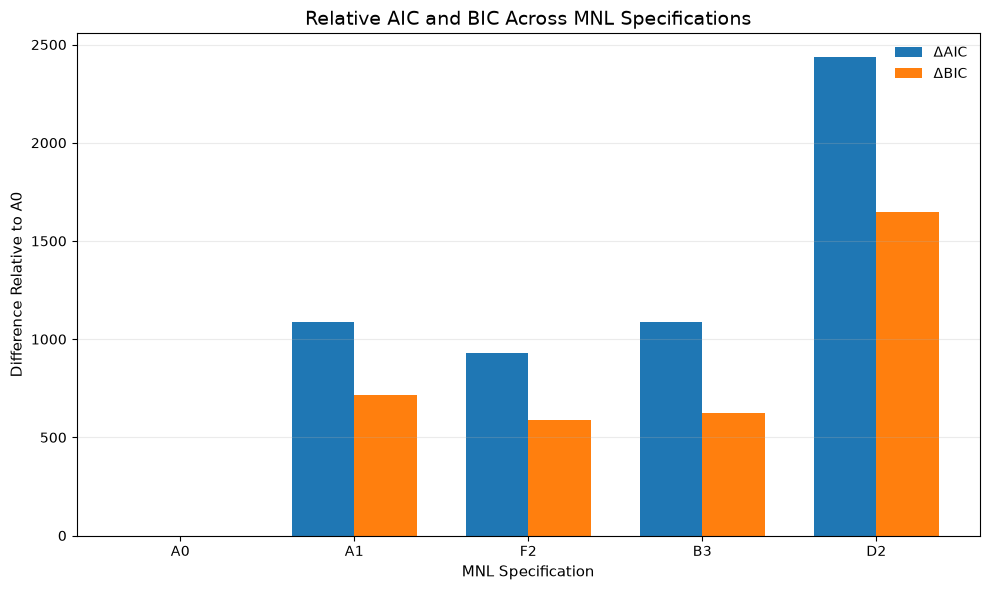

In [103]:
# Figure 1. Relative AIC and BIC comparison

import matplotlib.pyplot as plt
import numpy as np

plot_data = final_mnl_comparison.copy()

# Calculate information criteria differences relative to A0
a0_aic = plot_data.loc[plot_data["Model"] == "A0", "AIC"].iloc[0]
a0_bic = plot_data.loc[plot_data["Model"] == "A0", "BIC"].iloc[0]

plot_data["Delta_AIC"] = plot_data["AIC"] - a0_aic
plot_data["Delta_BIC"] = plot_data["BIC"] - a0_bic

x = np.arange(len(plot_data))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    plot_data["Delta_AIC"],
    width,
    label="ΔAIC"
)

ax.bar(
    x + width / 2,
    plot_data["Delta_BIC"],
    width,
    label="ΔBIC"
)

ax.set_title("Relative AIC and BIC Across MNL Specifications", fontsize=14)
ax.set_xlabel("MNL Specification", fontsize=11)
ax.set_ylabel("Difference Relative to A0", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(plot_data["Model"])
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [104]:
# Retrieve likelihood-ratio tests among the five selected MNL models

selected_models = ["A0", "A1", "F2", "B3", "D2"]

lr_plot_data = mnl_selection_results["lr_tests"].loc[
    mnl_selection_results["lr_tests"]["Restricted_Model"].isin(selected_models)
    & mnl_selection_results["lr_tests"]["Unrestricted_Model"].isin(selected_models)
].copy()

lr_plot_data = lr_plot_data.sort_values(
    ["Unrestricted_Model", "Restricted_Model"]
).reset_index(drop=True)

display(
    lr_plot_data[
        [
            "Restricted_Model",
            "Unrestricted_Model",
            "LR_Statistic",
            "Degrees_of_Freedom",
            "P_Value",
            "Status"
        ]
    ]
)

,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
0,A1,A0,1166.303737,40,1.657595e-218,Completed
1,B3,A0,1188.968364,50,4.200748e-216,Completed
2,D2,A0,2606.610020,85,0.000000e+00,Completed
3,F2,A0,1006.104382,37,4.416654e-187,Completed
4,B3,A1,22.664627,10,1.205453e-02,Completed
5,D2,A1,1440.306283,45,2.051895e-272,Completed
6,A1,F2,160.199354,3,1.660002e-34,Completed
7,B3,F2,182.863981,13,4.416102e-32,Completed
8,D2,F2,1600.505638,48,6.745226e-304,Completed


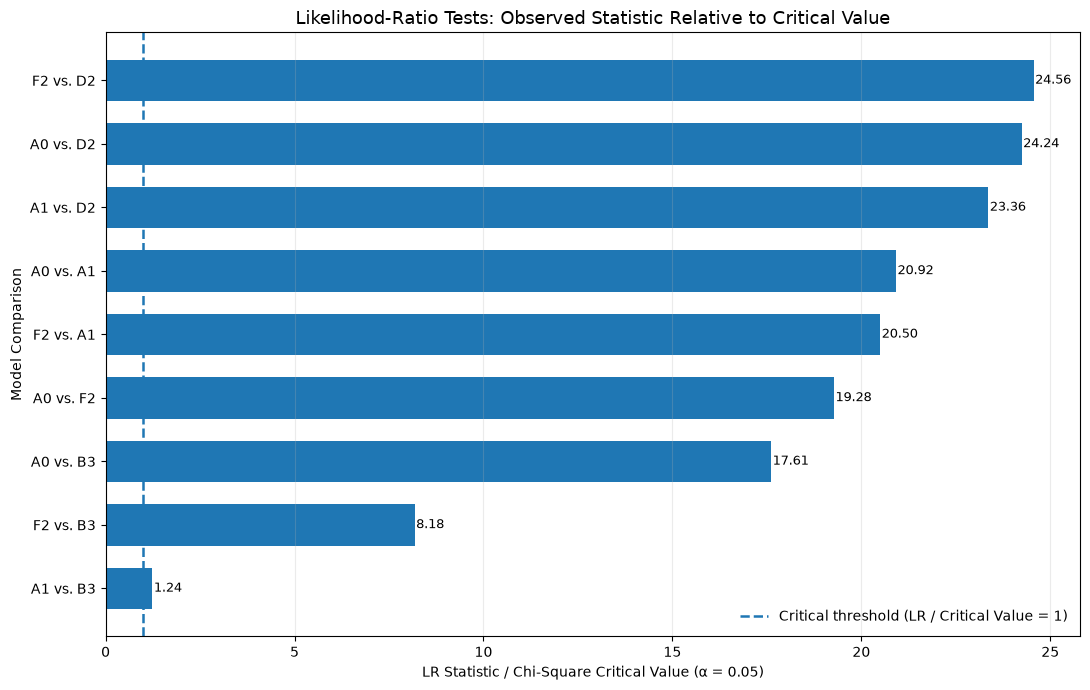

In [105]:
# Figure 2. Likelihood-ratio statistics versus chi-square critical values

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2

lr_plot = lr_plot_data.copy()

# Calculate the 5% chi-square critical value for each test
lr_plot["Critical_Value"] = chi2.ppf(
    0.95,
    lr_plot["Degrees_of_Freedom"]
)

# Calculate the ratio between observed and critical LR statistics
lr_plot["LR_Ratio"] = (
    lr_plot["LR_Statistic"] / lr_plot["Critical_Value"]
)

lr_plot["Comparison"] = (
    lr_plot["Unrestricted_Model"]
    + " vs. "
    + lr_plot["Restricted_Model"]
)

lr_plot = lr_plot.sort_values("LR_Ratio", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(lr_plot))

ax.barh(
    y,
    lr_plot["LR_Ratio"],
    height=0.65
)

ax.axvline(
    1,
    linestyle="--",
    linewidth=1.8,
    label="Critical threshold (LR / Critical Value = 1)"
)

ax.set_yticks(y)
ax.set_yticklabels(lr_plot["Comparison"])

ax.set_title(
    "Likelihood-Ratio Tests: Observed Statistic Relative to Critical Value",
    fontsize=13
)
ax.set_xlabel("LR Statistic / Chi-Square Critical Value (α = 0.05)")
ax.set_ylabel("Model Comparison")

# Annotate each bar with the LR ratio
for i, value in enumerate(lr_plot["LR_Ratio"]):
    ax.text(
        value + 0.04,
        i,
        f"{value:.2f}",
        va="center",
        fontsize=9
    )

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

1. **Likelihood-ratio test interpretation.** The likelihood-ratio (LR) tests evaluate whether imposing parameter restrictions significantly reduces the goodness of fit of the MNL specifications. The observed LR statistics are compared against their corresponding chi-square critical values at a 5% significance level.

2. **Comparison with the unrestricted baseline (A0).** All four restricted specifications (A1, F2, B3, and D2) exhibit LR statistics substantially above their respective critical values. Therefore, the null hypothesis that the imposed restrictions do not significantly reduce model fit is rejected in all four comparisons. This indicates that the unrestricted specification provides a significantly better in-sample fit.

3. **Comparison between A1 and B3.** The comparison between A1 and B3 produces an LR statistic of 22.665 with 10 degrees of freedom (p = 0.0121). Although the result is statistically significant at the 5% level, it is the comparison closest to the critical threshold among the evaluated tests. This indicates that the additional restrictions imposed by B3 produce a relatively limited loss of in-sample fit compared with A1.

4. **Comparison between F2 and B3.** The LR statistic is 182.864 with 13 degrees of freedom (p < 0.001). Despite their nearly identical cross-validated Macro-F1 scores, the two specifications differ significantly in their in-sample goodness of fit. This illustrates that similar predictive performance does not necessarily imply equivalent model fit.

5. **Impact of stronger parameter restrictions.** D2 exhibits substantially larger LR statistics relative to the critical values across its comparisons. This suggests a considerable deterioration in in-sample fit when a more restrictive specification is adopted, supporting the decision to avoid excessive model simplification.

6. **Overall interpretation and model selection.** The LR tests indicate that the restrictions imposed by the parsimonious specifications generally involve statistically significant losses in model fit. Nevertheless, statistical significance alone does not determine predictive usefulness, particularly given the large sample size. Considering parameter reduction, cross-validated predictive performance, and model complexity, B3 was retained as the parsimonious MNL specification. A0 remains the unrestricted benchmark, while A1 serves as the reduced reference model.

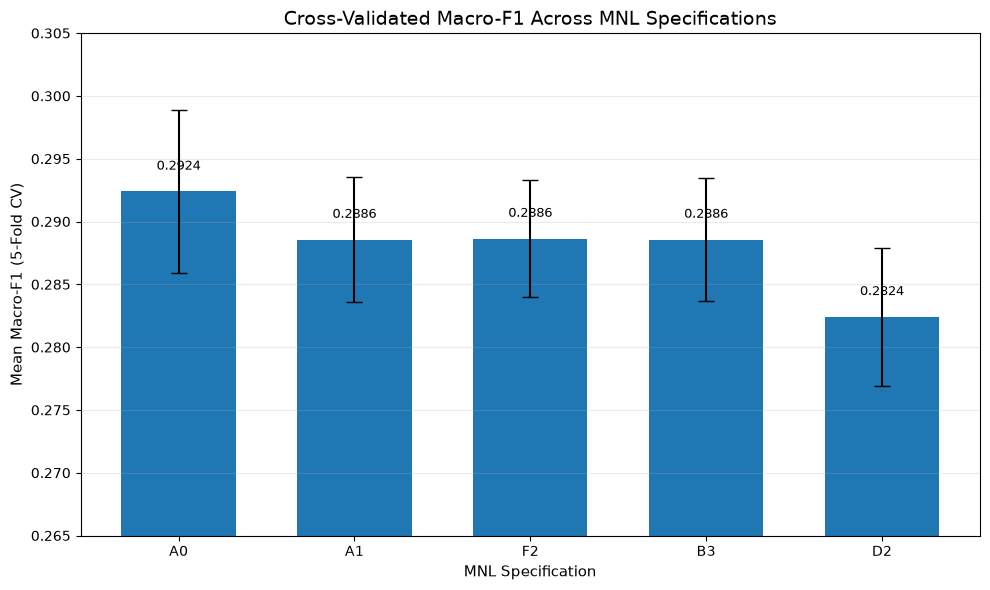

In [106]:
# Figure 3. Cross-validated Macro-F1 across MNL specifications

import matplotlib.pyplot as plt
import numpy as np

plot_data = final_mnl_comparison.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["Model"],
    plot_data["Macro_F1_mean"],
    yerr=plot_data["Macro_F1_std"],
    capsize=6,
    width=0.65
)

# Annotate mean Macro-F1 values
for bar, value in zip(bars, plot_data["Macro_F1_mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Cross-Validated Macro-F1 Across MNL Specifications",
    fontsize=14
)
ax.set_xlabel("MNL Specification", fontsize=11)
ax.set_ylabel("Mean Macro-F1 (5-Fold CV)", fontsize=11)

ax.set_ylim(0.265, 0.305)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

1. **Overall predictive performance.** The unrestricted baseline A0 achieves the highest cross-validated Macro-F1 (0.2924), followed by F2 (0.2886), B3 (0.2886), and A1 (0.2886). D2 exhibits the lowest performance (0.2824).

2. **Comparison between A0 and B3.** B3 achieves a Macro-F1 of 0.2886, compared with 0.2924 for A0. This represents an approximately 1.31% relative reduction in Macro-F1, while reducing the number of free parameters from 310 to 260 (16.1%). Therefore, B3 retains approximately 98.7% of the predictive performance of the unrestricted baseline.

3. **Comparison among A1, F2, and B3.** These three specifications exhibit virtually identical predictive performance. In particular, the difference between F2 and B3 is negligible (approximately 0.0001 Macro-F1 points), despite F2 having 13 additional free parameters. This supports the selection of B3 as a more parsimonious alternative without an appreciable loss in cross-validated predictive performance.

4. **Effect of further model simplification.** D2 achieves a lower Macro-F1 of 0.2824. This suggests that more aggressive parameter reduction may involve a more noticeable predictive cost.

5. **Cross-validation variability.** The standard deviations across the five folds range from approximately 0.0046 to 0.0065. Although the observed variability is relatively limited, the error bars represent descriptive fold-to-fold variability rather than formal confidence intervals or statistical significance tests.

6. **Implications for final model selection.** The results support retaining A0 as the unrestricted benchmark, A1 as the reduced reference specification, and B3 as the selected parsimonious MNL model. B3 provides a favorable balance between parameter reduction and predictive performance, making it an appropriate econometric reference for the subsequent comparison with machine learning classifiers.

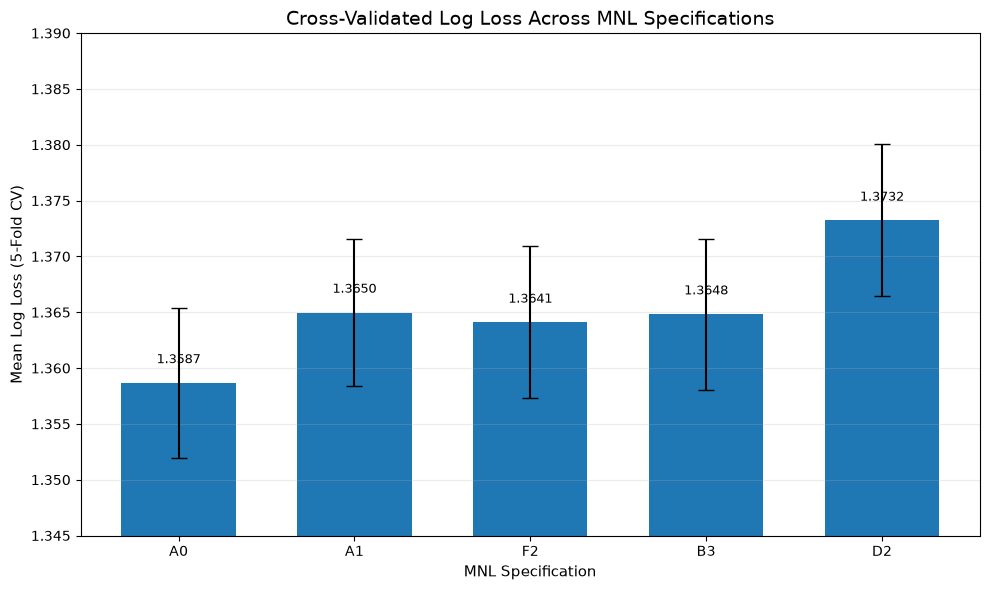

In [107]:
# Figure 4. Cross-validated Log Loss across MNL specifications

import matplotlib.pyplot as plt
import numpy as np

plot_data = final_mnl_comparison.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["Model"],
    plot_data["Log_Loss_mean"],
    yerr=plot_data["Log_Loss_std"],
    capsize=6,
    width=0.65
)

# Annotate mean Log Loss values
for bar, value in zip(bars, plot_data["Log_Loss_mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Cross-Validated Log Loss Across MNL Specifications",
    fontsize=14
)

ax.set_xlabel("MNL Specification", fontsize=11)
ax.set_ylabel("Mean Log Loss (5-Fold CV)", fontsize=11)

ax.set_ylim(1.345, 1.390)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

1. **Overall probabilistic performance.** A0 achieves the lowest cross-validated Log Loss (1.3587), indicating the best probabilistic predictive performance among the five evaluated specifications. Among the restricted models, F2 obtains the lowest Log Loss (1.3641), followed closely by B3 (1.3648) and A1 (1.3650).

2. **Comparison between A0 and B3.** B3 exhibits a Log Loss of 1.3648, compared with 1.3587 for A0. The difference is approximately 0.0062 points, indicating a relatively small deterioration in probabilistic performance despite reducing the number of free parameters from 310 to 260.

3. **Comparison between F2 and B3.** F2 achieves a slightly lower Log Loss than B3, with a difference of approximately 0.0007 points. However, F2 requires 13 additional parameters, while both specifications exhibit nearly identical Macro-F1 performance. Therefore, the predictive advantage of F2 is limited relative to its additional complexity.

4. **Effect of further simplification.** D2 exhibits the highest Log Loss (1.3732), consistent with its lower Macro-F1 performance. This suggests that more aggressive parameter reduction can negatively affect both classification performance and probabilistic predictions.

5. **Cross-validation variability.** The standard deviations across the five folds are relatively similar, ranging from approximately 0.0066 to 0.0068. These values indicate comparable fold-to-fold variability across the evaluated specifications.

6. **Implications for final model selection.** Although A0 provides the best probabilistic predictions, B3 maintains a competitive Log Loss while using substantially fewer parameters. Together with the Macro-F1 results, these findings support retaining A0 as the unrestricted benchmark, A1 as the reduced reference specification, and B3 as the selected parsimonious MNL model.

#### ultima prueba aislada

In [108]:
# Inspect existing MNL specification and estimation objects

print("Available specification objects:")

for name in [
    "model_specs",
    "mnl_model_specs",
    "specifications",
    "model_specifications"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")

        if isinstance(obj, dict):
            print("Available model IDs:", list(obj.keys()))

            for model_id in ["A1", "B2", "B3", "B4", "B5"]:
                if model_id in obj:
                    print(f"\n{model_id}:")
                    print(obj[model_id])

print("\nAvailable estimation functions:")

for name in [
    "estimate_mnl_model",
    "mnl_objective",
    "run_mnl_model_selection"
]:
    print(f"{name}: {name in globals()}")

Available specification objects:

model_specs: dict
Available model IDs: ['A0', 'A1', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'D1', 'D2', 'D3', 'D4', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4']

A1:
{'name': 'Reduced MNL', 'variables': ['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m'], 'shared_variables': [], 'zero_restrictions': {}, 'parent': 'A0'}

B2:
{'name': 'Motorcycle license specific', 'variables': ['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m'], 'shared_variables': [], 'zero_restrictions': {'binary__has_motorcycle_license': ['A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO']}, 'parent': 'A1'}

B3:
{'name': 'Restricted sex', 'variables': ['has

In [109]:
# Inspect the MNL estimation function interface

import inspect

print("Function signature:")
print(inspect.signature(estimate_mnl_model))

print("\nFunction documentation:")
print(inspect.getdoc(estimate_mnl_model))

Function signature:
(model_id)

Function documentation:
None


In [110]:
# Inspect the existing MNL estimation implementation

print(inspect.getsource(estimate_mnl_model))

def estimate_mnl_model(model_id):

    start_time = time.perf_counter()

    # Build parameter structure
    parameter_map, parameter_names = build_parameter_map(model_id)

    # Build model-specific design matrix
    model_features = list(parameter_map.index)
    X_model = X_train_mnl[model_features].to_numpy(dtype=float)
    y = y_train_mnl.to_numpy(dtype=int)

    # Initialize parameters from baseline estimates
    theta_initial = np.zeros(len(parameter_names))

    for feature in parameter_map.index:

        feature_map = parameter_map.loc[feature]

        for parameter_idx in feature_map.unique():

            if parameter_idx < 0:
                continue

            alternatives = feature_map[
                feature_map == parameter_idx
            ].index

            theta_initial[parameter_idx] = (
                baseline_beta.loc[feature, alternatives].mean()
            )

    # Define average negative log-likelihood
    def objective_mean(theta):

        nll, gradien

In [111]:
# Inspect the parameter-map construction function

print(inspect.getsource(build_parameter_map))

def build_parameter_map(model_id):

    spec = model_specs[model_id]

    features = [
        "const",
        *[
            feature
            for variable in spec["variables"]
            for feature in feature_groups[variable]
        ]
    ]

    shared_features = {
        feature
        for variable in spec["shared_variables"]
        for feature in feature_groups[variable]
    }

    zero_restrictions = spec["zero_restrictions"]

    parameter_map = pd.DataFrame(
        -1,
        index=features,
        columns=estimated_alternatives,
        dtype=int
    )

    parameter_names = []
    parameter_index = 0

    for feature in features:

        restricted_alternatives = zero_restrictions.get(feature, [])

        if feature in shared_features:
            parameter_map.loc[feature, :] = parameter_index
            parameter_names.append(f"{feature}__shared")
            parameter_index += 1

        else:
            for alternative in estimated_alternatives:

          

#### Creaqcion del modelo B6

In [112]:
# Define the combined B6 model specification
b6_spec = {
    "name": "Combined motorcycle license and restricted sex",
    "variables": model_specs["A1"]["variables"].copy(),
    "shared_variables": [],
    "zero_restrictions": {
        "binary__has_motorcycle_license":
            model_specs["B2"]["zero_restrictions"][
                "binary__has_motorcycle_license"
            ].copy(),
        "categorical__sexo_Intersexual":
            model_specs["B3"]["zero_restrictions"][
                "categorical__sexo_Intersexual"
            ].copy()
    },
    "parent": "A1"
}

# Calculate the expected number of free parameters
b6_features = [
    "const",
    *[
        feature
        for variable in b6_spec["variables"]
        for feature in feature_groups[variable]
    ]
]

b6_restrictions = b6_spec["zero_restrictions"]

b6_expected_parameters = sum(
    len(estimated_alternatives) - len(b6_restrictions.get(feature, []))
    for feature in b6_features
)

print("B6 specification created successfully.")
print(f"Number of predictors: {len(b6_spec['variables'])}")
print(f"Number of estimated alternatives: {len(estimated_alternatives)}")
print(f"Expected free parameters: {b6_expected_parameters}")
print("Restrictions:", list(b6_restrictions.keys()))

B6 specification created successfully.
Number of predictors: 9
Number of estimated alternatives: 10
Expected free parameters: 251
Restrictions: ['binary__has_motorcycle_license', 'categorical__sexo_Intersexual']


In [113]:
# Inspect the model summary structure
print("Columns:", model_summary_df.columns.tolist())

display(
    model_summary_df.loc[
        model_summary_df["Model"].isin(["A1", "B2", "B3"]),
        ["Model", "Free_Parameters"]
    ]
)

Columns: ['Model', 'Specification', 'Variables', 'Transformed_Features', 'Free_Parameters', 'Parent']


,Model,Free_Parameters
1,A1,270
3,B2,261
4,B3,260


In [115]:
import copy

# Temporarily register B6 and validate its parameter map
model_specs_original = copy.deepcopy(model_specs)
model_summary_original = model_summary_df.copy(deep=True)

try:
    model_specs["B6"] = b6_spec

    b6_summary_row = model_summary_df.iloc[0].copy()
    b6_summary_row["Model"] = "B6"
    b6_summary_row["Free_Parameters"] = b6_expected_parameters

    model_summary_df = pd.concat(
        [model_summary_df, b6_summary_row.to_frame().T],
        ignore_index=True
    )

    b6_parameter_map, b6_parameter_names = build_parameter_map("B6")

    print("B6 parameter map validated successfully.")
    print(f"Generated parameters: {len(b6_parameter_names)}")
    print(f"Expected parameters: {b6_expected_parameters}")

finally:
    model_specs = model_specs_original
    model_summary_df = model_summary_original

B6 parameter map validated successfully.
Generated parameters: 251
Expected parameters: 251


In [116]:
import copy

# Temporarily register B6 for model estimation
model_specs_original = copy.deepcopy(model_specs)
model_summary_original = model_summary_df.copy(deep=True)

try:
    model_specs["B6"] = b6_spec

    b6_summary_row = model_summary_df.iloc[0].copy()
    b6_summary_row["Model"] = "B6"
    b6_summary_row["Free_Parameters"] = b6_expected_parameters

    model_summary_df = pd.concat(
        [model_summary_df, b6_summary_row.to_frame().T],
        ignore_index=True
    )

    # Estimate B6
    b6_model_result = estimate_mnl_model("B6")

finally:
    # Restore original model catalog and summary
    model_specs = model_specs_original
    model_summary_df = model_summary_original

# Display estimation results
print("B6 estimation completed.")
print(f"Converged: {b6_model_result['converged']}")
print(f"Iterations: {b6_model_result['iterations']}")
print(f"Gradient norm: {b6_model_result['gradient_norm']:.8f}")
print(f"Free parameters: {b6_model_result['n_parameters']}")
print(f"Log-Likelihood: {b6_model_result['log_likelihood']:.4f}")
print(f"AIC: {b6_model_result['AIC']:.4f}")
print(f"BIC: {b6_model_result['BIC']:.4f}")
print(f"Runtime: {b6_model_result['runtime_seconds']:.2f} seconds")

B6 estimation completed.
Converged: True
Iterations: 254
Gradient norm: 0.00005401
Free parameters: 251
Log-Likelihood: -108925.2727
AIC: 218352.5453
BIC: 220684.6380
Runtime: 85.85 seconds


In [117]:
# Identify existing cross-validation functions
import inspect

cv_functions = [
    name for name, obj in globals().items()
    if callable(obj)
    and inspect.isfunction(obj)
    and ("cv" in name.lower() or "fold" in name.lower())
]

print("Available cross-validation functions:")
for name in cv_functions:
    print(name)

Available cross-validation functions:


In [118]:
# Inspect existing model-selection and cross-validation objects
for name, obj in globals().items():
    if any(term in name.lower() for term in [
        "selection", "comparison", "fold", "cv", "result"
    ]):
        if isinstance(obj, (pd.DataFrame, dict, list)):
            print(
                f"{name}: {type(obj).__name__}",
                f"| shape: {obj.shape}" if isinstance(obj, pd.DataFrame) else "",
                f"| length: {len(obj)}"
            )

wald_results: list  | length: 30
group_wald_results: list  | length: 11
school_results: DataFrame | shape: (42, 3) | length: 42
individual_wald_results: list  | length: 310
a1_result: dict  | length: 13
e5_result: dict  | length: 13
fold_diagnostics: list  | length: 5
fold_diagnostics_df: DataFrame | shape: (5, 8) | length: 5
mnl_selection_results: dict  | length: 8
selection_table: DataFrame | shape: (24, 11) | length: 24
cv_failures: DataFrame | shape: (4, 7) | length: 4
lr_results: DataFrame | shape: (158, 6) | length: 158
final_mnl_comparison: DataFrame | shape: (5, 25) | length: 5
b6_model_result: dict  | length: 13
cv_functions: list  | length: 0


In [119]:
# Inspect the structure of the original model-selection results
print("Keys in mnl_selection_results:")
for key, value in mnl_selection_results.items():
    print(f"\n{key}: {type(value).__name__}")

    if isinstance(value, pd.DataFrame):
        print("Shape:", value.shape)
        print("Columns:", value.columns.tolist())
        display(value.head(3))

    elif isinstance(value, (list, tuple)):
        print("Length:", len(value))
        if len(value) > 0:
            print("First element:", value[0])

    elif isinstance(value, dict):
        print("Nested keys:", list(value.keys()))

Keys in mnl_selection_results:

model_results: dict
Nested keys: ['A0', 'A1', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'D1', 'D2', 'D3', 'D4', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4']

model_summary: DataFrame
Shape: (24, 12)
Columns: ['Model', 'Variables', 'Free_Parameters', 'Log_Likelihood', 'AIC', 'BIC', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']


,Model,Variables,Free_Parameters,Log_Likelihood,AIC,BIC,Converged,Iterations,Gradient_Norm,Runtime_Seconds,Status,Error
0,A0,11,310,-108311.682648,217243.365295,220123.639124,True,110,0.000044,16.105523,Completed,None
1,A1,9,270,-108894.834516,218329.669032,220838.294625,True,260,0.000014,35.548774,Completed,None
2,B1,9,261,-110124.665491,220771.330982,223196.335722,True,598,0.000044,78.098040,Completed,None



cv_metrics: DataFrame
Shape: (120, 14)
Columns: ['Model', 'Fold', 'Accuracy', 'Balanced_Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Log_Loss', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']


,Model,Fold,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss,Converged,Iterations,Gradient_Norm,Runtime_Seconds,Status,Error
0,A0,1,0.536479,0.304511,0.360615,0.304511,0.290274,1.369134,True,482,0.000012,50.349260,Completed,None
1,A0,2,0.542748,0.309441,0.358425,0.309441,0.296199,1.352562,True,806,0.000032,79.323266,Completed,None
2,A0,3,0.540348,0.299578,0.361976,0.299578,0.282331,1.355825,True,581,0.000069,61.833184,Completed,None



cv_summary: DataFrame
Shape: (24, 14)
Columns: ['Model', 'Accuracy_mean', 'Accuracy_std', 'Balanced_Accuracy_mean', 'Balanced_Accuracy_std', 'Macro_Precision_mean', 'Macro_Precision_std', 'Macro_Recall_mean', 'Macro_Recall_std', 'Macro_F1_mean', 'Macro_F1_std', 'Log_Loss_mean', 'Log_Loss_std', 'CV_Folds_Completed']


,Model,Accuracy_mean,Accuracy_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,Macro_Precision_mean,Macro_Precision_std,Macro_Recall_mean,Macro_Recall_std,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std,CV_Folds_Completed
0,A0,0.539481,0.002501,0.306092,0.004218,0.376592,0.038039,0.306092,0.004218,0.292390,0.006492,1.358668,0.006733,5
1,A1,0.538308,0.003337,0.303896,0.003807,0.361787,0.008721,0.303896,0.003807,0.288553,0.004974,1.364977,0.006611,5
2,B1,0.536485,0.002760,0.295184,0.002049,0.356007,0.007605,0.295184,0.002049,0.278961,0.003557,1.380221,0.005467,5



comparison: DataFrame
Shape: (24, 25)
Columns: ['Model', 'Variables', 'Free_Parameters', 'Log_Likelihood', 'AIC', 'BIC', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error', 'Accuracy_mean', 'Accuracy_std', 'Balanced_Accuracy_mean', 'Balanced_Accuracy_std', 'Macro_Precision_mean', 'Macro_Precision_std', 'Macro_Recall_mean', 'Macro_Recall_std', 'Macro_F1_mean', 'Macro_F1_std', 'Log_Loss_mean', 'Log_Loss_std', 'CV_Folds_Completed']


,Model,Variables,Free_Parameters,Log_Likelihood,AIC,BIC,Converged,Iterations,Gradient_Norm,Runtime_Seconds,...,Balanced_Accuracy_std,Macro_Precision_mean,Macro_Precision_std,Macro_Recall_mean,Macro_Recall_std,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std,CV_Folds_Completed
0,A0,11,310,-108311.682648,217243.365295,220123.639124,True,110,0.000044,16.105523,...,0.004218,0.376592,0.038039,0.306092,0.004218,0.292390,0.006492,1.358668,0.006733,5
1,F1,10,300,-108494.137539,217588.275077,220375.636847,True,216,0.000018,84.447609,...,0.004671,0.358792,0.003648,0.304498,0.004671,0.289470,0.005415,1.360649,0.006980,5
2,F2,10,273,-108814.734839,218175.469678,220711.968888,True,208,0.000015,81.547897,...,0.003721,0.361526,0.006162,0.303964,0.003721,0.288633,0.004636,1.364090,0.006801,5



lr_tests: DataFrame
Shape: (158, 6)
Columns: ['Restricted_Model', 'Unrestricted_Model', 'LR_Statistic', 'Degrees_of_Freedom', 'P_Value', 'Status']


,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
0,A1,A0,1166.303737,40,1.657595e-218,Completed
1,B1,A0,3625.965687,49,0.000000e+00,Completed
2,B2,A0,1204.528950,49,4.805945e-220,Completed



confusion_matrices: dict
Nested keys: ['A0', 'A1', 'B1', 'B2', 'B3', 'B4', 'B5', 'C1', 'C2', 'C3', 'C4', 'D1', 'D2', 'D3', 'D4', 'E1', 'E2', 'E3', 'E4', 'E5', 'F1', 'F2', 'F3', 'F4']

runtime_seconds: float


In [120]:
# Inspect the stored B3 model results
b3_stored_result = mnl_selection_results["model_results"]["B3"]

print("B3 result type:", type(b3_stored_result).__name__)

if isinstance(b3_stored_result, dict):
    print("B3 result keys:")
    for key, value in b3_stored_result.items():
        print(f"{key}: {type(value).__name__}")
else:
    print(b3_stored_result)

B3 result type: dict
B3 result keys:
full_sample: dict
cv_folds: list


In [121]:
# Inspect the first B3 cross-validation fold
b3_cv_folds = b3_stored_result["cv_folds"]

print("Number of folds:", len(b3_cv_folds))
print("\nFirst fold type:", type(b3_cv_folds[0]).__name__)

if isinstance(b3_cv_folds[0], dict):
    print("\nFirst fold keys:")
    for key, value in b3_cv_folds[0].items():
        print(f"{key}: {type(value).__name__}")

    print("\nFirst fold contents:")
    for key, value in b3_cv_folds[0].items():
        if isinstance(value, (int, float, str, bool)):
            print(f"{key}: {value}")

Number of folds: 5

First fold type: dict

First fold keys:
model_id: str
optimization: OptimizeResult
parameter_map: DataFrame
parameter_names: list
coefficients: ndarray
beta: ndarray
n_parameters: int
log_likelihood: float64
AIC: float64
BIC: float64
converged: bool
iterations: int
gradient_norm: float64
runtime_seconds: float
message: str

First fold contents:
model_id: B3
n_parameters: 260
log_likelihood: -86916.54830631253
AIC: 174353.09661262506
BIC: 176710.79201175808
converged: True
iterations: 284
gradient_norm: 1.0710352676032603e-05
runtime_seconds: 81.73075029999745
message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


In [123]:
# Inspect the original cross-validation metrics
cv_metrics_original = mnl_selection_results["cv_metrics"]

print("CV metrics type:", type(cv_metrics_original).__name__)

if isinstance(cv_metrics_original, pd.DataFrame):
    print("Shape:", cv_metrics_original.shape)
    print("Columns:", cv_metrics_original.columns.tolist())

    display(
        cv_metrics_original[
            cv_metrics_original["Model"] == "B3"
        ].sort_values("Fold")
    )

CV metrics type: DataFrame
Shape: (120, 14)
Columns: ['Model', 'Fold', 'Accuracy', 'Balanced_Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Log_Loss', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']


,Model,Fold,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Log_Loss,Converged,Iterations,Gradient_Norm,Runtime_Seconds,Status,Error
20,B3,1,0.537540,0.306156,0.371350,0.306156,0.291653,1.375457,True,284,0.000011,81.854076,Completed,None
21,B3,2,0.542811,0.307877,0.370429,0.307877,0.294592,1.359069,True,443,0.000015,125.445477,Completed,None
22,B3,3,0.539787,0.299865,0.359193,0.299865,0.282173,1.361987,True,288,0.000040,89.555503,Completed,None
23,B3,4,0.533704,0.299889,0.351773,0.299889,0.285415,1.367495,True,529,0.000065,149.194794,Completed,None
24,B3,5,0.537449,0.305677,0.356190,0.305677,0.288964,1.360128,True,480,0.000012,139.103737,Completed,None


In [124]:
# Inspect the original model-selection implementation
import inspect

print(inspect.getsource(run_mnl_model_selection))

def run_mnl_model_selection(
    cv=inner_cv,
    groups=groups_train,
    verbose=True
):
    """
    Estimate and compare the 24 predefined MNL specifications.

    The function performs:
    1. Full development-sample estimation for every model.
    2. Five-fold grouped cross-validation.
    3. Predictive evaluation.
    4. Nested-model likelihood ratio tests.
    5. Consolidated result tables.

    Existing preprocessing, feature transformations, model specifications,
    and development/test partitions remain unchanged.
    """

    global_start = time.perf_counter()

    # ---------------------------------------------------------
    # 1. General configuration
    # ---------------------------------------------------------

    model_ids = list(model_specs.keys())
    y_full = np.asarray(y_train_mnl, dtype=int)
    n_observations = len(y_full)
    n_alternatives = len(mode_categories)

    groups_array = np.asarray(groups)

    if len(groups_array) != n_observations:
        rais

In [126]:
# Inspect the original grouped cross-validation configuration
print("CV strategy:", type(inner_cv).__name__)
print("Number of splits:", inner_cv.n_splits)
print("Shuffle:", inner_cv.shuffle)
print("Random state:", inner_cv.random_state)

print("\nTraining observations:", len(X_train_mnl))
print("Training groups:", len(np.unique(groups_train)))

CV strategy: StratifiedGroupKFold
Number of splits: 5
Shuffle: True
Random state: 42

Training observations: 80114
Training groups: 38821


In [127]:
import copy
import time
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import softmax
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    log_loss,
    confusion_matrix
)

# ---------------------------------------------------------
# 1. Preserve the original model specifications and summary
# ---------------------------------------------------------

model_specs_original = copy.deepcopy(model_specs)
model_summary_original = model_summary_df.copy(deep=True)

b6_cv_folds = []
b6_cv_metric_rows = []

n_alternatives = len(mode_categories)
y_full = np.asarray(y_train_mnl, dtype=int)

# Reconstruct the exact original grouped CV splits.
cv_splits = list(
    inner_cv.split(
        X_train_mnl,
        y_train_mnl,
        groups=np.asarray(groups_train)
    )
)

assert len(cv_splits) == 5

# ---------------------------------------------------------
# 2. Temporarily register B6 for parameter-map construction
# ---------------------------------------------------------

try:
    model_specs["B6"] = b6_spec

    b6_summary_row = model_summary_df.iloc[0].copy()
    b6_summary_row["Model"] = "B6"
    b6_summary_row["Free_Parameters"] = b6_expected_parameters

    model_summary_df = pd.concat(
        [model_summary_df, b6_summary_row.to_frame().T],
        ignore_index=True
    )

    # -----------------------------------------------------
    # 3. Define the original estimation helpers
    # -----------------------------------------------------

    def b6_unpack_coefficients(theta, parameter_map):
        map_array = parameter_map.to_numpy()
        beta = np.zeros(parameter_map.shape, dtype=float)

        valid_positions = np.where(map_array >= 0)
        beta[valid_positions] = theta[
            map_array[valid_positions]
        ]

        return beta

    def b6_initialize_parameters(parameter_map):
        theta_initial = np.zeros(
            int(parameter_map.to_numpy().max()) + 1,
            dtype=float
        )

        for feature in parameter_map.index:
            feature_map = parameter_map.loc[feature]

            for parameter_idx in feature_map.unique():
                if parameter_idx < 0:
                    continue

                alternatives = feature_map[
                    feature_map == parameter_idx
                ].index

                theta_initial[parameter_idx] = (
                    baseline_beta.loc[
                        feature, alternatives
                    ].mean()
                )

        return theta_initial

    def b6_fit_one_fold(X_data, y_data):
        start_time = time.perf_counter()

        parameter_map, parameter_names = build_parameter_map("B6")

        model_features = list(parameter_map.index)

        X_array = X_data[model_features].to_numpy(dtype=float)
        y_array = np.asarray(y_data, dtype=int)

        theta_initial = b6_initialize_parameters(parameter_map)

        def objective_mean(theta):
            nll, gradient = mnl_objective(
                theta,
                X_array,
                y_array,
                parameter_map
            )

            return (
                nll / len(y_array),
                gradient / len(y_array)
            )

        optimization = minimize(
            fun=objective_mean,
            x0=theta_initial,
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": 1000,
                "ftol": 1e-9,
                "gtol": 1e-6
            }
        )

        beta = b6_unpack_coefficients(
            optimization.x,
            parameter_map
        )

        return {
            "optimization": optimization,
            "parameter_map": parameter_map,
            "parameter_names": parameter_names,
            "beta": beta,
            "n_parameters": len(optimization.x),
            "converged": bool(optimization.success),
            "iterations": optimization.nit,
            "gradient_norm": np.linalg.norm(optimization.jac),
            "runtime_seconds": time.perf_counter() - start_time,
            "message": optimization.message
        }

    # -----------------------------------------------------
    # 4. Execute the five original grouped CV folds
    # -----------------------------------------------------

    b6_confusion_matrix = np.zeros(
        (n_alternatives, n_alternatives),
        dtype=int
    )

    for fold_number, (train_idx, validation_idx) in enumerate(
        cv_splits,
        start=1
    ):
        fold_start = time.perf_counter()

        print(f"\nB6 — Fold {fold_number}/5")

        X_fold_train = X_train_mnl.iloc[train_idx]
        X_fold_validation = X_train_mnl.iloc[validation_idx]

        y_fold_train = y_full[train_idx]
        y_fold_validation = y_full[validation_idx]

        fold_result = b6_fit_one_fold(
            X_fold_train,
            y_fold_train
        )

        # Calculate validation probabilities.
        X_validation_array = X_fold_validation[
            list(fold_result["parameter_map"].index)
        ].to_numpy(dtype=float)

        utilities = X_validation_array @ fold_result["beta"]

        utility_matrix = np.column_stack([
            np.zeros(len(X_validation_array)),
            utilities
        ])

        probabilities = softmax(utility_matrix, axis=1)

        predictions = np.argmax(probabilities, axis=1)

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_fold_validation,
            predictions,
            labels=np.arange(n_alternatives),
            average="macro",
            zero_division=0
        )

        metrics = {
            "Accuracy": accuracy_score(
                y_fold_validation, predictions
            ),
            "Balanced_Accuracy": balanced_accuracy_score(
                y_fold_validation, predictions
            ),
            "Macro_Precision": precision,
            "Macro_Recall": recall,
            "Macro_F1": f1,
            "Log_Loss": log_loss(
                y_fold_validation,
                probabilities,
                labels=np.arange(n_alternatives)
            )
        }

        fold_confusion = confusion_matrix(
            y_fold_validation,
            predictions,
            labels=np.arange(n_alternatives)
        )

        b6_confusion_matrix += fold_confusion
        b6_cv_folds.append(fold_result)

        fold_record = {
            "Model": "B6",
            "Fold": fold_number,
            **metrics,
            "Converged": fold_result["converged"],
            "Iterations": fold_result["iterations"],
            "Gradient_Norm": fold_result["gradient_norm"],
            "Runtime_Seconds": time.perf_counter() - fold_start,
            "Status": "Completed",
            "Error": None
        }

        b6_cv_metric_rows.append(fold_record)

        print(
            f"Macro-F1: {metrics['Macro_F1']:.4f} | "
            f"Log Loss: {metrics['Log_Loss']:.4f} | "
            f"Converged: {fold_result['converged']} | "
            f"Time: {fold_record['Runtime_Seconds']:.1f}s"
        )

    b6_cv_metrics = pd.DataFrame(b6_cv_metric_rows)

finally:
    # Restore the original model definitions and summary.
    model_specs = model_specs_original
    model_summary_df = model_summary_original

# ---------------------------------------------------------
# 5. Display B6 cross-validation results
# ---------------------------------------------------------

display(
    b6_cv_metrics[
        [
            "Model",
            "Fold",
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1",
            "Log_Loss",
            "Converged",
            "Iterations",
            "Runtime_Seconds"
        ]
    ].round(4)
)

print("\nB6 CV completed:", len(b6_cv_metrics), "/ 5 folds")
print("All folds converged:", b6_cv_metrics["Converged"].all())


B6 — Fold 1/5
Macro-F1: 0.2909 | Log Loss: 1.3752 | Converged: True | Time: 72.7s

B6 — Fold 2/5
Macro-F1: 0.2939 | Log Loss: 1.3591 | Converged: True | Time: 135.0s

B6 — Fold 3/5
Macro-F1: 0.2819 | Log Loss: 1.3622 | Converged: True | Time: 76.4s

B6 — Fold 4/5
Macro-F1: 0.2853 | Log Loss: 1.3677 | Converged: True | Time: 164.3s

B6 — Fold 5/5
Macro-F1: 0.2893 | Log Loss: 1.3599 | Converged: True | Time: 127.7s


,Model,Fold,Accuracy,Balanced_Accuracy,Macro_F1,Log_Loss,Converged,Iterations,Runtime_Seconds
0,B6,1,0.5369,0.3051,0.2909,1.3752,True,268,72.7084
1,B6,2,0.5426,0.3072,0.2939,1.3591,True,520,135.0121
2,B6,3,0.5399,0.2998,0.2819,1.3622,True,283,76.3895
3,B6,4,0.5338,0.2997,0.2853,1.3677,True,650,164.3311
4,B6,5,0.5376,0.3058,0.2893,1.3599,True,478,127.7117



B6 CV completed: 5 / 5 folds
All folds converged: True


### 1.5 Comparacion y seleccion de modelos 

In [130]:
# Prepare the six selected MNL specifications for graphical comparison

selected_models = ["A0", "A1", "F2", "B3", "B6", "D2"]

# Retrieve original comparison results
final_mnl_comparison = (
    mnl_selection_results["comparison"]
    .set_index("Model")
    .loc[["A0", "A1", "F2", "B3", "D2"]]
    .reset_index()
)

# Add B6 results
b6_comparison_row = pd.DataFrame([{
    "Model": "B6",
    "Free_Parameters": b6_model_result["n_parameters"],
    "AIC": b6_model_result["AIC"],
    "BIC": b6_model_result["BIC"],
    "Macro_F1_mean": b6_cv_metrics["Macro_F1"].mean(),
    "Macro_F1_std": b6_cv_metrics["Macro_F1"].std(),
    "Log_Loss_mean": b6_cv_metrics["Log_Loss"].mean(),
    "Log_Loss_std": b6_cv_metrics["Log_Loss"].std()
}])

# Combine all selected models
final_mnl_comparison = (
    pd.concat(
        [final_mnl_comparison, b6_comparison_row],
        ignore_index=True
    )
    .set_index("Model")
    .loc[selected_models]
    .reset_index()
)

display(
    final_mnl_comparison[
        [
            "Model",
            "Free_Parameters",
            "AIC",
            "BIC",
            "Macro_F1_mean",
            "Macro_F1_std",
            "Log_Loss_mean",
            "Log_Loss_std"
        ]
    ].round(6)
)

,Model,Free_Parameters,AIC,BIC,Macro_F1_mean,Macro_F1_std,Log_Loss_mean,Log_Loss_std
0,A0,310,217243.365295,220123.639124,0.292390,0.006492,1.358668,0.006733
1,A1,270,218329.669032,220838.294625,0.288553,0.004974,1.364977,0.006611
2,F2,273,218175.469678,220711.968888,0.288633,0.004636,1.364090,0.006801
3,B3,260,218332.333659,220748.047193,0.288559,0.004919,1.364827,0.006772
4,B6,251,218352.545350,220684.638030,0.288257,0.004741,1.364838,0.006709
5,D2,225,219679.975316,221770.496643,0.282405,0.005506,1.373221,0.006806


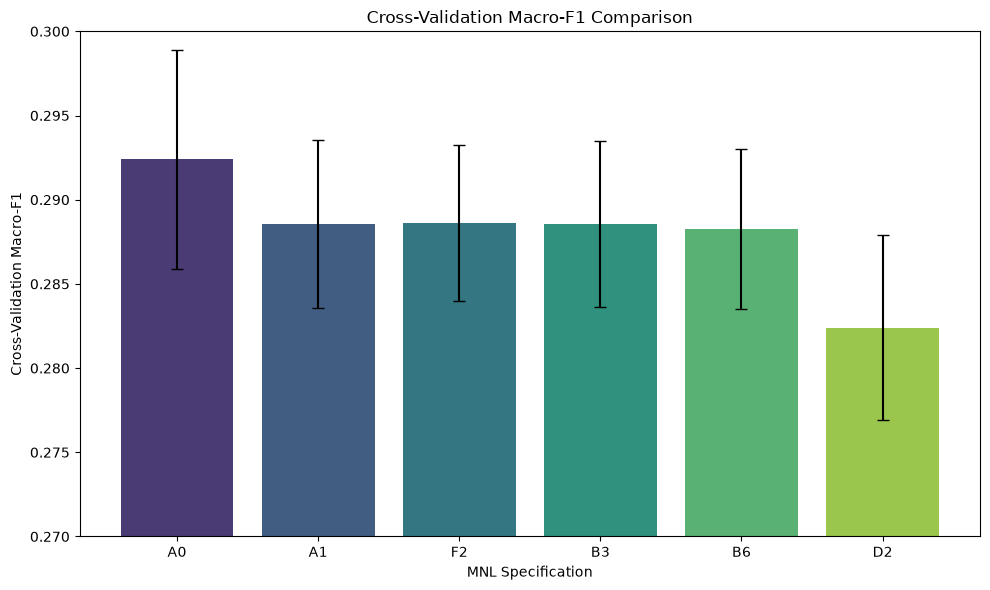

In [ ]:
# Plot cross-validation Macro-F1 comparison with adjusted y-axis
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_mnl_comparison,
    x="Model",
    y="Macro_F1_mean",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.errorbar(
    x=range(len(final_mnl_comparison)),
    y=final_mnl_comparison["Macro_F1_mean"],
    yerr=final_mnl_comparison["Macro_F1_std"],
    fmt="none",
    color="black",
    capsize=4
)

plt.ylim(0.27, 0.30)

plt.ylabel("Cross-Validation Macro-F1")
plt.xlabel("MNL Specification")
plt.title("Cross-Validation Macro-F1 Comparison")

plt.tight_layout()
plt.show()

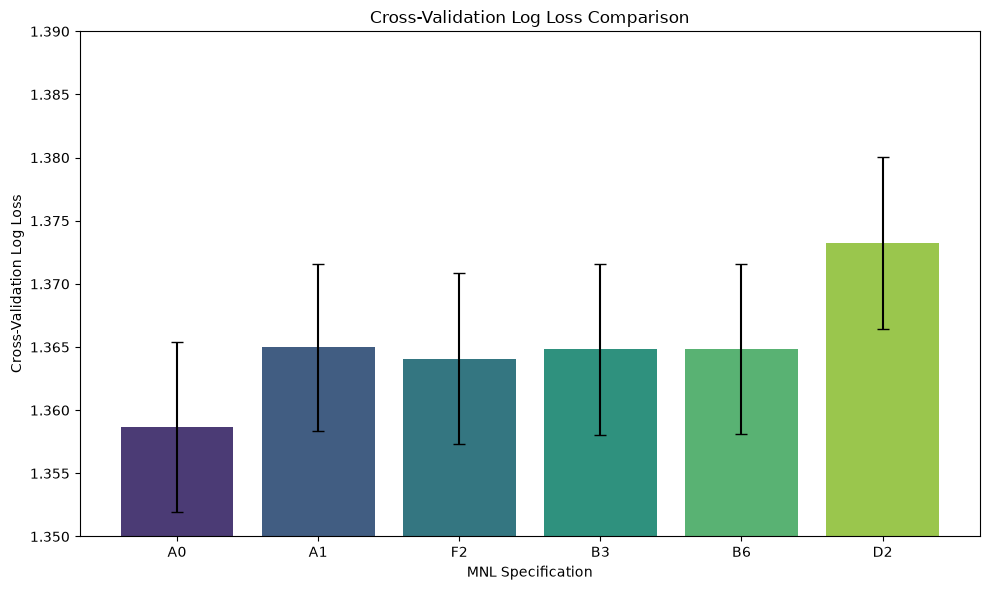

In [134]:
# Plot cross-validation Log Loss comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_mnl_comparison,
    x="Model",
    y="Log_Loss_mean",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.errorbar(
    x=range(len(final_mnl_comparison)),
    y=final_mnl_comparison["Log_Loss_mean"],
    yerr=final_mnl_comparison["Log_Loss_std"],
    fmt="none",
    color="black",
    capsize=4
)

plt.ylim(1.35, 1.39)

plt.ylabel("Cross-Validation Log Loss")
plt.xlabel("MNL Specification")
plt.title("Cross-Validation Log Loss Comparison")

plt.tight_layout()
plt.show()

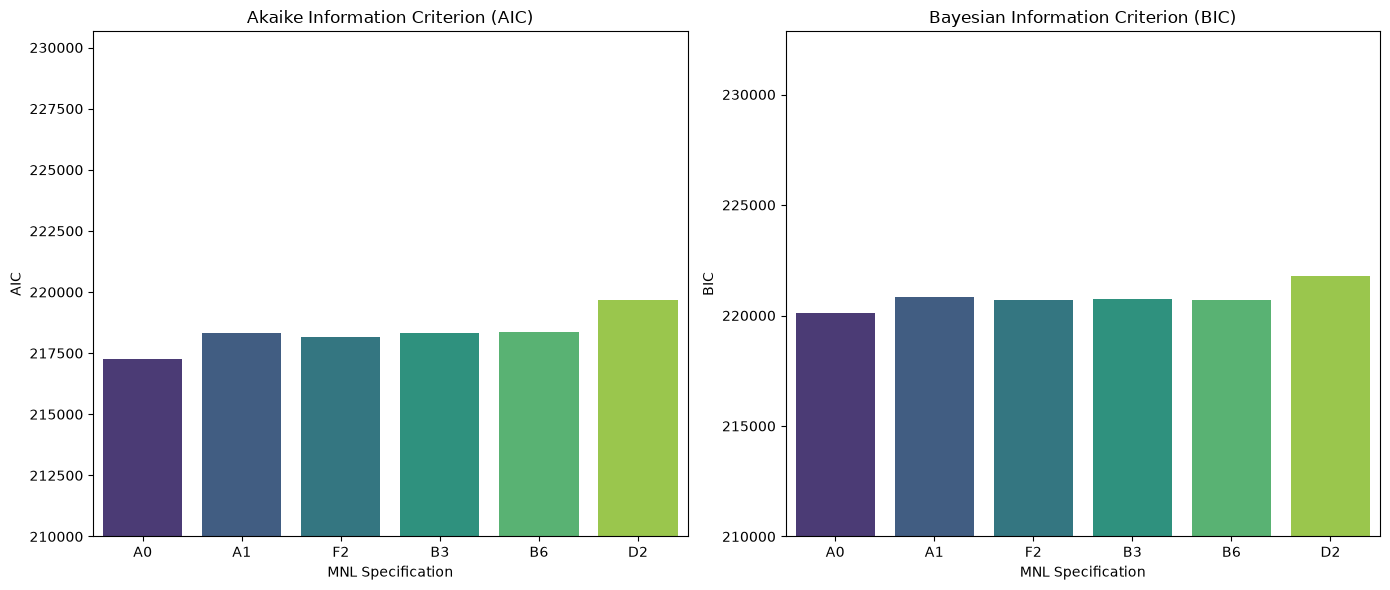

In [139]:
# Plot AIC and BIC comparison with adjusted y-axis

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# AIC
sns.barplot(
    data=final_mnl_comparison,
    x="Model",
    y="AIC",
    hue="Model",
    legend=False,
    palette="viridis",
    ax=axes[0]
)

axes[0].set_title("Akaike Information Criterion (AIC)")
axes[0].set_xlabel("MNL Specification")
axes[0].set_ylabel("AIC")
axes[0].set_ylim(bottom=210000)

# BIC
sns.barplot(
    data=final_mnl_comparison,
    x="Model",
    y="BIC",
    hue="Model",
    legend=False,
    palette="viridis",
    ax=axes[1]
)

axes[1].set_title("Bayesian Information Criterion (BIC)")
axes[1].set_xlabel("MNL Specification")
axes[1].set_ylabel("BIC")
axes[1].set_ylim(bottom=210000)

plt.tight_layout()
plt.show()

In [140]:
# Calculate AIC and BIC differences relative to the best model

information_criteria_comparison = final_mnl_comparison.copy()

information_criteria_comparison["Delta_AIC"] = (
    information_criteria_comparison["AIC"]
    - information_criteria_comparison["AIC"].min()
)

information_criteria_comparison["Delta_BIC"] = (
    information_criteria_comparison["BIC"]
    - information_criteria_comparison["BIC"].min()
)

display(
    information_criteria_comparison[
        [
            "Model",
            "Free_Parameters",
            "Delta_AIC",
            "Delta_BIC"
        ]
    ].sort_values("Delta_AIC").round(3)
)

,Model,Free_Parameters,Delta_AIC,Delta_BIC
0,A0,310,0.000,0.000
2,F2,273,932.104,588.330
1,A1,270,1086.304,714.656
3,B3,260,1088.968,624.408
4,B6,251,1109.180,560.999
5,D2,225,2436.610,1646.858


In [143]:
# Likelihood Ratio Tests for B6 against nested models

from scipy.stats import chi2

# Retrieve full-sample log-likelihoods
ll_b6 = b6_model_result["log_likelihood"]

ll_b3 = mnl_selection_results["model_results"]["B3"]["full_sample"]["log_likelihood"]
ll_a1 = mnl_selection_results["model_results"]["A1"]["full_sample"]["log_likelihood"]

# Define nested model comparisons
lr_comparisons = [
    {
        "Comparison": "B3 vs B6",
        "LL_Unrestricted": ll_b3,
        "LL_Restricted": ll_b6,
        "df": 260 - 251
    },
    {
        "Comparison": "A1 vs B6",
        "LL_Unrestricted": ll_a1,
        "LL_Restricted": ll_b6,
        "df": 270 - 251
    }
]

lr_results = []

for comparison in lr_comparisons:
    lr_stat = 2 * (
        comparison["LL_Unrestricted"]
        - comparison["LL_Restricted"]
    )

    p_value = chi2.sf(lr_stat, comparison["df"])

    lr_results.append({
        "Comparison": comparison["Comparison"],
        "LR_Statistic": lr_stat,
        "Degrees_of_Freedom": comparison["df"],
        "P_Value": p_value
    })

lr_comparison_df = pd.DataFrame(lr_results)

display(lr_comparison_df.round(6))

,Comparison,LR_Statistic,Degrees_of_Freedom,P_Value
0,B3 vs B6,38.211690,9,0.000016
1,A1 vs B6,60.876317,19,0.000003


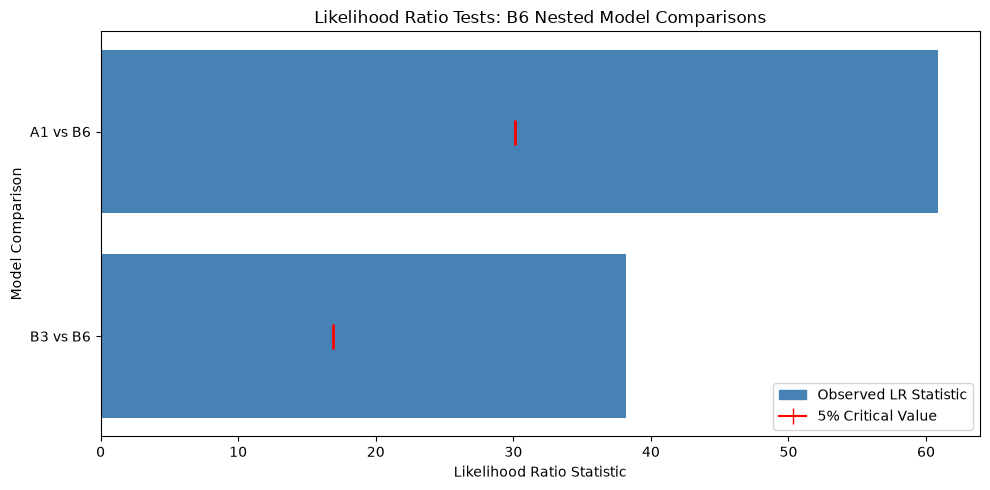

In [144]:
# Plot Likelihood Ratio Test statistics

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

# Calculate 5% critical values
lr_plot_df = lr_comparison_df.copy()

lr_plot_df["Critical_Value"] = lr_plot_df[
    "Degrees_of_Freedom"
].apply(lambda df: chi2.ppf(0.95, df))

plt.figure(figsize=(10, 5))

y_positions = range(len(lr_plot_df))

plt.barh(
    y_positions,
    lr_plot_df["LR_Statistic"],
    color="steelblue",
    label="Observed LR Statistic"
)

for i, row in lr_plot_df.iterrows():
    plt.plot(
        row["Critical_Value"],
        i,
        marker="|",
        markersize=18,
        markeredgewidth=2,
        color="red"
    )

plt.yticks(
    list(y_positions),
    lr_plot_df["Comparison"]
)

plt.xlabel("Likelihood Ratio Statistic")
plt.ylabel("Model Comparison")
plt.title("Likelihood Ratio Tests: B6 Nested Model Comparisons")

plt.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="steelblue",
                      label="Observed LR Statistic"),
        plt.Line2D([0], [0], color="red", marker="|",
                   markersize=12, label="5% Critical Value")
    ]
)

plt.tight_layout()
plt.show()

In [145]:
# Inspect original Likelihood Ratio Test results

lr_tests_original = mnl_selection_results["lr_tests"]

print("Original LR test structure:")
print("Columns:", lr_tests_original.columns.tolist())
print("Number of comparisons:", len(lr_tests_original))

display(lr_tests_original.head(10))

Original LR test structure:
Columns: ['Restricted_Model', 'Unrestricted_Model', 'LR_Statistic', 'Degrees_of_Freedom', 'P_Value', 'Status']
Number of comparisons: 158


,Restricted_Model,Unrestricted_Model,LR_Statistic,Degrees_of_Freedom,P_Value,Status
0,A1,A0,1166.303737,40,1.657595e-218,Completed
1,B1,A0,3625.965687,49,0.000000e+00,Completed
2,B2,A0,1204.528950,49,4.805945e-220,Completed
3,B3,A0,1188.968364,50,4.200748e-216,Completed
4,B4,A0,3718.087711,58,0.000000e+00,Completed
5,B5,A0,3649.615769,59,0.000000e+00,Completed
6,C1,A0,4918.675861,94,0.000000e+00,Completed
7,C2,A0,7133.131984,112,0.000000e+00,Completed
8,C3,A0,7497.061218,103,0.000000e+00,Completed
9,C4,A0,7518.987889,113,0.000000e+00,Completed


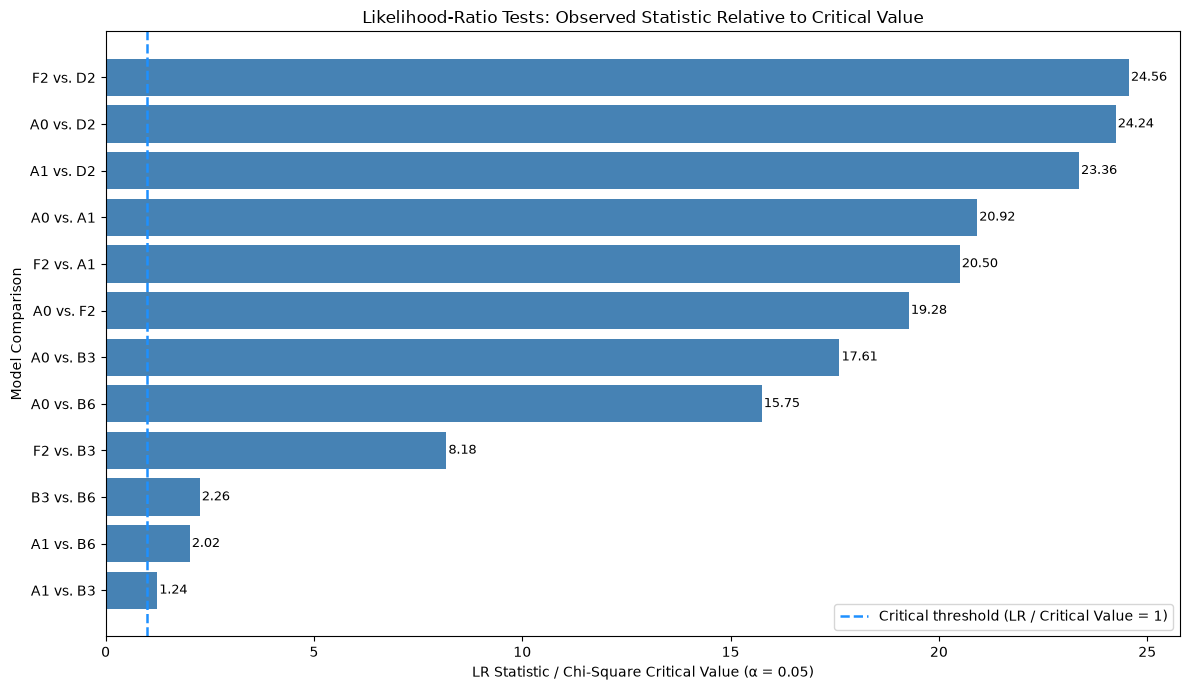

In [146]:
# Reproduce the original LR comparison plot, including B6

from scipy.stats import chi2
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Selected models
selected_models = ["A0", "A1", "F2", "B3", "B6", "D2"]

# Retrieve original comparisons among selected models
lr_plot_df = mnl_selection_results["lr_tests"].copy()

lr_plot_df = lr_plot_df[
    lr_plot_df["Restricted_Model"].isin(selected_models)
    & lr_plot_df["Unrestricted_Model"].isin(selected_models)
].copy()

# Retrieve full-sample log-likelihoods
ll_a0 = mnl_selection_results["model_results"]["A0"]["full_sample"]["log_likelihood"]
ll_a1 = mnl_selection_results["model_results"]["A1"]["full_sample"]["log_likelihood"]
ll_b3 = mnl_selection_results["model_results"]["B3"]["full_sample"]["log_likelihood"]
ll_b6 = b6_model_result["log_likelihood"]

# Add new B6 nested comparisons
b6_comparisons = [
    ("B6", "A0", ll_a0, 310 - 251),
    ("B6", "A1", ll_a1, 270 - 251),
    ("B6", "B3", ll_b3, 260 - 251)
]

new_lr_rows = []

for restricted, unrestricted, ll_unrestricted, df in b6_comparisons:

    lr_stat = 2 * (ll_unrestricted - ll_b6)

    new_lr_rows.append({
        "Restricted_Model": restricted,
        "Unrestricted_Model": unrestricted,
        "LR_Statistic": lr_stat,
        "Degrees_of_Freedom": df,
        "P_Value": chi2.sf(lr_stat, df),
        "Status": "Completed"
    })

# Combine original and new comparisons
lr_plot_df = pd.concat(
    [lr_plot_df, pd.DataFrame(new_lr_rows)],
    ignore_index=True
)

# Calculate normalized LR statistics
lr_plot_df["Critical_Value"] = lr_plot_df[
    "Degrees_of_Freedom"
].apply(lambda df: chi2.ppf(0.95, df))

lr_plot_df["LR_Ratio"] = (
    lr_plot_df["LR_Statistic"] / lr_plot_df["Critical_Value"]
)

# Create comparison labels
lr_plot_df["Comparison"] = (
    lr_plot_df["Unrestricted_Model"]
    + " vs. "
    + lr_plot_df["Restricted_Model"]
)

# Sort comparisons
lr_plot_df = lr_plot_df.sort_values(
    "LR_Ratio",
    ascending=True
).reset_index(drop=True)

# Plot
plt.figure(figsize=(12, 7))

bars = plt.barh(
    lr_plot_df["Comparison"],
    lr_plot_df["LR_Ratio"],
    color="steelblue"
)

plt.axvline(
    x=1,
    color="dodgerblue",
    linestyle="--",
    linewidth=1.8,
    label="Critical threshold (LR / Critical Value = 1)"
)

for bar, value in zip(bars, lr_plot_df["LR_Ratio"]):
    plt.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=9
    )

plt.xlabel(
    "LR Statistic / Chi-Square Critical Value (α = 0.05)"
)
plt.ylabel("Model Comparison")
plt.title(
    "Likelihood-Ratio Tests: Observed Statistic Relative to Critical Value"
)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [147]:
# Inspect B6 nested-model likelihood ratio tests

display(
    lr_plot_df[
        lr_plot_df["Restricted_Model"] == "B6"
    ][
        [
            "Comparison",
            "LR_Statistic",
            "Degrees_of_Freedom",
            "Critical_Value",
            "LR_Ratio",
            "P_Value"
        ]
    ].round(8)
)

,Comparison,LR_Statistic,Degrees_of_Freedom,Critical_Value,LR_Ratio,P_Value
1,A1 vs. B6,60.876317,19,30.143527,2.019549,0.000003
2,B3 vs. B6,38.211690,9,16.918978,2.258511,0.000016
4,A0 vs. B6,1227.180054,59,77.930524,15.747104,0.000000


### 1.6 conclusion


**Final MNL Model Selection**

A0 was retained as the unrestricted benchmark model, while B3 and B6 were considered the main restricted alternatives.

**Final decision: B6 was selected as the parsimonious MNL specification.**

The selection prioritizes model simplicity while preserving practically equivalent predictive performance. Compared with B3, B6 reduces the number of free parameters from 260 to 251, while achieving nearly identical cross-validation performance:

- **Macro-F1:** 0.28826 (B6) vs. 0.28856 (B3).
- **Log Loss:** 1.36484 (B6) vs. 1.36483 (B3).
- **BIC:** 220,684.64 (B6) vs. 220,748.05 (B3).

Although the likelihood-ratio test indicates a statistically significant loss of in-sample fit relative to B3 (LR = 38.21, df = 9, p = 0.000016), the predictive differences are negligible in practical terms.

**Therefore, B6 was retained as the final parsimonious MNL specification**, prioritizing reduced complexity and interpretability over a marginal improvement in in-sample fit.

A0 remains the unrestricted benchmark, and B3 is retained as an intermediate comparison model.


### 1.7 Salvar modelos

In [148]:
# Inspect objects required to transfer the experiment to ML

objects_to_check = [
    "X_train_mnl",
    "y_train_mnl",
    "groups_train",
    "X_test_mnl",
    "y_test_mnl",
    "groups_test",
    "inner_cv",
    "b3_features",
    "key_pers"
]

for name in objects_to_check:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}:")
        print(f"  Type: {type(obj).__name__}")

        if hasattr(obj, "shape"):
            print(f"  Shape: {obj.shape}")

        elif hasattr(obj, "__len__"):
            print(f"  Length: {len(obj)}")

    else:
        print(f"\n{name}: NOT FOUND")


X_train_mnl:
  Type: DataFrame
  Shape: (80114, 31)

y_train_mnl:
  Type: Series
  Shape: (80114,)

groups_train:
  Type: Series
  Shape: (80114,)

X_test_mnl:
  Type: DataFrame
  Shape: (20029, 31)

y_test_mnl:
  Type: Series
  Shape: (20029,)

groups_test:
  Type: Series
  Shape: (20029,)

inner_cv:
  Type: StratifiedGroupKFold

b3_features: NOT FOUND

key_pers: NOT FOUND


In [149]:
# Verify observation indexes and reconstruct the original CV folds

import numpy as np

print("TRAIN INDEX")
print("Unique:", X_train_mnl.index.is_unique)
print("First values:", X_train_mnl.index[:5].tolist())

print("\nTEST INDEX")
print("Unique:", X_test_mnl.index.is_unique)
print("First values:", X_test_mnl.index[:5].tolist())

print("\nTRAIN/TEST OVERLAP")
print("Overlapping indexes:",
      len(set(X_train_mnl.index).intersection(X_test_mnl.index)))

# Reconstruct the exact five CV folds
cv_splits = list(
    inner_cv.split(
        X_train_mnl,
        y_train_mnl,
        groups=groups_train
    )
)

print("\nCROSS-VALIDATION FOLDS")

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {fold}: "
        f"Train={len(train_idx):,}, "
        f"Validation={len(val_idx):,}, "
        f"Train groups={groups_train.iloc[train_idx].nunique():,}, "
        f"Validation groups={groups_train.iloc[val_idx].nunique():,}"
    )

TRAIN INDEX
Unique: True
First values: [0, 1, 2, 3, 4]

TEST INDEX
Unique: True
First values: [21, 22, 25, 26, 27]

TRAIN/TEST OVERLAP
Overlapping indexes: 0

CROSS-VALIDATION FOLDS
Fold 1: Train=64,091, Validation=16,023, Train groups=31,058, Validation groups=7,763
Fold 2: Train=64,090, Validation=16,024, Train groups=31,055, Validation groups=7,766
Fold 3: Train=64,091, Validation=16,023, Train groups=31,054, Validation groups=7,767
Fold 4: Train=64,092, Validation=16,022, Train groups=31,060, Validation groups=7,761
Fold 5: Train=64,092, Validation=16,022, Train groups=31,057, Validation groups=7,764


In [150]:
from pathlib import Path

output_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models"
)

output_path.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_path)
print("Directory exists:", output_path.exists())

Output directory: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models
Directory exists: True


In [151]:
import numpy as np

# Reconstruct the original five grouped cross-validation splits
cv_splits = list(
    inner_cv.split(
        X_train_mnl,
        y_train_mnl,
        groups=groups_train
    )
)

# Store original row indices and CV fold positions
artifacts = {
    "train_indices": X_train_mnl.index.to_numpy(),
    "test_indices": X_test_mnl.index.to_numpy(),
    "y_train": y_train_mnl.to_numpy(),
    "y_test": y_test_mnl.to_numpy(),
    "groups_train": groups_train.to_numpy(),
    "groups_test": groups_test.to_numpy(),
}

# Store each fold's positional indices
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    artifacts[f"fold_{fold}_train"] = train_idx
    artifacts[f"fold_{fold}_validation"] = val_idx

# Save all partitioning artifacts
np.savez_compressed(
    output_path / "MNL_data_partitions_and_CV_folds.npz",
    **artifacts
)

print("Saved:", output_path / "MNL_data_partitions_and_CV_folds.npz")
print("Training observations:", len(artifacts["train_indices"]))
print("Test observations:", len(artifacts["test_indices"]))
print("CV folds saved:", len(cv_splits))

Saved: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models\MNL_data_partitions_and_CV_folds.npz
Training observations: 80114
Test observations: 20029
CV folds saved: 5


In [152]:
# Verify group separation across train/test and CV folds

train_test_overlap = set(groups_train.unique()) & set(groups_test.unique())

print("Train-test overlapping persons:", len(train_test_overlap))

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    train_groups = set(groups_train.iloc[train_idx])
    val_groups = set(groups_train.iloc[val_idx])

    overlap = train_groups & val_groups

    print(
        f"Fold {fold}: "
        f"overlapping persons = {len(overlap)}"
    )

Train-test overlapping persons: 0
Fold 1: overlapping persons = 0
Fold 2: overlapping persons = 0
Fold 3: overlapping persons = 0
Fold 4: overlapping persons = 0
Fold 5: overlapping persons = 0


In [154]:
# Locate B6-related objects currently available in memory

print("Variables containing 'b6' in their names:\n")

for name, obj in globals().copy().items():
    if "b6" in name.lower():
        print(
            f"{name}: "
            f"{type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', None)}"
        )

print("\nOther potentially relevant MNL result objects:\n")

for name, obj in globals().copy().items():
    if any(term in name.lower() for term in [
        "mnl", "comparison", "lr_test", "confusion"
    ]):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

Variables containing 'b6' in their names:

b6_spec: dict, shape=None
b6_features: list, shape=None
b6_restrictions: dict, shape=None
b6_expected_parameters: int, shape=None
b6_summary_row: Series, shape=(6,)
b6_parameter_map: DataFrame, shape=(27, 10)
b6_parameter_names: list, shape=None
b6_model_result: dict, shape=None
b6_cv_folds: list, shape=None
b6_cv_metric_rows: list, shape=None
b6_unpack_coefficients: function, shape=None
b6_initialize_parameters: function, shape=None
b6_fit_one_fold: function, shape=None
b6_confusion_matrix: ndarray, shape=(11, 11)
b6_cv_metrics: DataFrame, shape=(5, 14)
b6_comparison_row: DataFrame, shape=(1, 8)
ll_b6: float64, shape=()
b6_comparisons: list, shape=None

Other potentially relevant MNL result objects:

y_train_mnl: Series
X_train_mnl: DataFrame
mnl_model: MNLogit
mnl_results: MultinomialResultsWrapper
mnl_results_2: MultinomialResultsWrapper
mnl_results_lbfgs: MultinomialResultsWrapper
X_test_mnl: DataFrame
y_test_mnl: Series
confusion_matrix: 

In [155]:
# Inspect B6 objects before exporting

objects_to_inspect = {
    "b6_spec": b6_spec,
    "b6_model_result": b6_model_result,
    "b6_cv_folds": b6_cv_folds,
    "b6_cv_metric_rows": b6_cv_metric_rows,
    "b6_restrictions": b6_restrictions,
    "b6_parameter_map": b6_parameter_map,
    "b6_comparisons": b6_comparisons,
}

for name, obj in objects_to_inspect.items():
    print(f"\n{'=' * 55}")
    print(f"{name}: {type(obj).__name__}")

    if isinstance(obj, dict):
        print("Keys:", list(obj.keys()))

    elif isinstance(obj, list):
        print("Length:", len(obj))
        if len(obj) > 0:
            print("First element type:", type(obj[0]).__name__)
            if isinstance(obj[0], dict):
                print("First element keys:", list(obj[0].keys()))

    elif isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))


b6_spec: dict
Keys: ['name', 'variables', 'shared_variables', 'zero_restrictions', 'parent']

b6_model_result: dict
Keys: ['model_id', 'optimization', 'parameter_map', 'parameter_names', 'coefficients', 'n_parameters', 'log_likelihood', 'AIC', 'BIC', 'converged', 'iterations', 'gradient_norm', 'runtime_seconds']

b6_cv_folds: list
Length: 5
First element type: dict
First element keys: ['optimization', 'parameter_map', 'parameter_names', 'beta', 'n_parameters', 'converged', 'iterations', 'gradient_norm', 'runtime_seconds', 'message']

b6_cv_metric_rows: list
Length: 5
First element type: dict
First element keys: ['Model', 'Fold', 'Accuracy', 'Balanced_Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Log_Loss', 'Converged', 'Iterations', 'Gradient_Norm', 'Runtime_Seconds', 'Status', 'Error']

b6_restrictions: dict
Keys: ['binary__has_motorcycle_license', 'categorical__sexo_Intersexual']

b6_parameter_map: DataFrame
Shape: (27, 10)
Columns: ['A PIE <15 MIN', 'A PIE > 15 MIN', '

### 1.8 respaldo completo de los modelos

In [156]:
import pickle
import json
import pandas as pd
from pathlib import Path

# Define output directory
output_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models"
)

# --------------------------------------------------
# 1. Complete MNL results bundle
# --------------------------------------------------

mnl_backup = {
    # Original 24 MNL specifications
    "mnl_selection_results": mnl_selection_results,

    # Final B6 model
    "b6_spec": b6_spec,
    "b6_model_result": b6_model_result,
    "b6_cv_folds": b6_cv_folds,
    "b6_cv_metrics": b6_cv_metrics,
    "b6_cv_metric_rows": b6_cv_metric_rows,

    # B6 specification and parameter information
    "b6_features": b6_features,
    "b6_restrictions": b6_restrictions,
    "b6_parameter_map": b6_parameter_map,
    "b6_parameter_names": b6_parameter_names,
    "b6_expected_parameters": b6_expected_parameters,

    # B6 evaluation
    "b6_confusion_matrix": b6_confusion_matrix,
    "b6_summary_row": b6_summary_row,
    "b6_comparison_row": b6_comparison_row,
    "b6_comparisons": b6_comparisons,

    # Model comparisons and statistical tests
    "final_mnl_comparison": final_mnl_comparison,
    "b3_lr_test": b3_lr_test,
    "information_criteria_comparison": information_criteria_comparison,
    "lr_comparison_df": lr_comparison_df,
    "lr_tests_original": lr_tests_original,
    "lr_comparisons": lr_comparisons,
}

# Save complete Python objects
pickle_path = output_path / "MNL_complete_results_backup.pkl"

with open(pickle_path, "wb") as file:
    pickle.dump(mnl_backup, file, protocol=pickle.HIGHEST_PROTOCOL)

print("Complete MNL backup saved:")
print(pickle_path)
print("Objects saved:", len(mnl_backup))

Complete MNL backup saved:
D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models\MNL_complete_results_backup.pkl
Objects saved: 21


In [157]:
# Export MNL result tables to CSV

tables_to_export = {
    "MNL_model_summary": mnl_selection_results["model_summary"],
    "MNL_CV_metrics": mnl_selection_results["cv_metrics"],
    "MNL_CV_summary": mnl_selection_results["cv_summary"],
    "MNL_model_comparison": mnl_selection_results["comparison"],
    "MNL_LR_tests": mnl_selection_results["lr_tests"],
    "MNL_B6_CV_metrics": b6_cv_metrics,
    "MNL_B6_parameter_map": b6_parameter_map,
    "MNL_B6_comparison": b6_comparison_row,
    "MNL_final_comparison": final_mnl_comparison,
    "MNL_information_criteria": information_criteria_comparison,
    "MNL_LR_comparison": lr_comparison_df,
}

for filename, dataframe in tables_to_export.items():
    if isinstance(dataframe, pd.DataFrame):
        dataframe.to_csv(
            output_path / f"{filename}.csv",
            index=True
        )
        print(f"Saved: {filename}.csv")
    else:
        print(f"Skipped (not a DataFrame): {filename}")

print("\nCSV export completed.")

Saved: MNL_model_summary.csv
Saved: MNL_CV_metrics.csv
Saved: MNL_CV_summary.csv
Saved: MNL_model_comparison.csv
Saved: MNL_LR_tests.csv
Saved: MNL_B6_CV_metrics.csv
Saved: MNL_B6_parameter_map.csv
Saved: MNL_B6_comparison.csv
Saved: MNL_final_comparison.csv
Saved: MNL_information_criteria.csv
Saved: MNL_LR_comparison.csv

CSV export completed.


In [158]:
import json
import numpy as np

# Convert NumPy and other non-standard objects to JSON-compatible values
def json_serializer(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return str(obj)

# Document the final MNL specification
mnl_configuration = {
    "project": "CME 508 - Urban Travel Forecasting",
    "analysis": "Multinomial Logit Model",
    "final_model": "B6",
    "benchmark_model": "A0",
    "intermediate_model": "B3",

    "selection_rationale": (
        "B6 was selected as the final parsimonious MNL specification, "
        "prioritizing model simplicity and interpretability while "
        "maintaining practically equivalent predictive performance."
    ),

    "b6_specification": b6_spec,
    "b6_restrictions": b6_restrictions,
    "b6_features": b6_features,
    "b6_expected_parameters": b6_expected_parameters,

    "b6_estimation": {
        "n_parameters": b6_model_result["n_parameters"],
        "log_likelihood": b6_model_result["log_likelihood"],
        "AIC": b6_model_result["AIC"],
        "BIC": b6_model_result["BIC"],
        "converged": b6_model_result["converged"],
        "iterations": b6_model_result["iterations"],
        "gradient_norm": b6_model_result["gradient_norm"],
        "runtime_seconds": b6_model_result["runtime_seconds"]
    },

    "validation": {
        "method": "StratifiedGroupKFold",
        "n_splits": 5,
        "group_variable": "key_pers",
        "random_state": 42
    }
}

json_path = output_path / "MNL_B6_model_configuration.json"

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        mnl_configuration,
        file,
        indent=4,
        ensure_ascii=False,
        default=json_serializer
    )

print("Configuration saved:", json_path)
print("Final MNL model:", mnl_configuration["final_model"])
print("Expected parameters:", mnl_configuration["b6_expected_parameters"])

Configuration saved: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models\MNL_B6_model_configuration.json
Final MNL model: B6
Expected parameters: 251


In [ ]:
import pickle
import json

# 1. Verify all expected files
expected_files = [
    "MNL_data_partitions_and_CV_folds.npz",
    "MNL_complete_results_backup.pkl",
    "MNL_B6_model_configuration.json",
    "MNL_model_summary.csv",
    "MNL_CV_metrics.csv",
    "MNL_CV_summary.csv",
    "MNL_model_comparison.csv",
    "MNL_LR_tests.csv",
    "MNL_B6_CV_metrics.csv",
    "MNL_B6_parameter_map.csv",
    "MNL_B6_comparison.csv",
    "MNL_final_comparison.csv",
    "MNL_information_criteria.csv",
    "MNL_LR_comparison.csv",
]

print("FILE VERIFICATION")
print("-" * 55)

for filename in expected_files:
    file_path = output_path / filename
    status = "OK" if file_path.exists() else "MISSING"
    print(f"{status}: {filename}")

# 2. Test pickle recovery
with open(output_path / "MNL_complete_results_backup.pkl", "rb") as file:
    recovered_backup = pickle.load(file)

print("\nPICKLE RECOVERY")
print("Objects recovered:", len(recovered_backup))
print("B6 parameters:", recovered_backup["b6_model_result"]["n_parameters"])
print("B6 CV folds:", len(recovered_backup["b6_cv_folds"]))

# 3. Test JSON recovery
with open(output_path / "MNL_B6_model_configuration.json", "r", encoding="utf-8") as file:
    recovered_config = json.load(file)

print("\nJSON RECOVERY")
print("Final model:", recovered_config["final_model"])
print("Expected parameters:", recovered_config["b6_expected_parameters"])

# 4. Final status
missing_files = [
    filename for filename in expected_files
    if not (output_path / filename).exists()
]

print("\nFINAL STATUS")
print("Missing files:", len(missing_files))
print("Backup directory:", output_path)

FILE VERIFICATION
-------------------------------------------------------
OK: MNL_data_partitions_and_CV_folds.npz
OK: MNL_complete_results_backup.pkl
OK: MNL_B6_model_configuration.json
OK: MNL_model_summary.csv
OK: MNL_CV_metrics.csv
OK: MNL_CV_summary.csv
OK: MNL_model_comparison.csv
OK: MNL_LR_tests.csv
OK: MNL_B6_CV_metrics.csv
OK: MNL_B6_parameter_map.csv
OK: MNL_B6_comparison.csv
OK: MNL_final_comparison.csv
OK: MNL_information_criteria.csv
OK: MNL_LR_comparison.csv

PICKLE RECOVERY
Objects recovered: 21
B6 parameters: 251
B6 CV folds: 5

JSON RECOVERY
Final model: B6
Expected parameters: 251

FINAL STATUS
Missing files: 0
Backup directory: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\MNLM_models


### 1.7 ML XGboost

### 1.8 ML NN

### 1.9 Interpretabilidad: SHAP, importancia de variables e interacciones.

### 1.10 Comparación y conclusiones

#### 1.10.1 Accuracy, macro-F1, balanced accuracy y log-loss.

#### 1.10.2 Matrices de confusión por alternativa.

#### 1.10.3 Interpretabilidad: coeficientes y efectos del MNL frente a SHAP.

#### 1.10.4 Desempeño por grupos socioeconómicos y geográficos.

#### 1.10.5 Conclusiones

#### 1.10.6 Limitaciones y posterioes